# Proyecto Final — Derivados · Apple (AAPL): Bono Convertible Sintético con volatilidad GARCH
**Base metodológica:** caso *Molson Coors Brewing Co.: Valuing a Convertible Bond* (NE90-06-107) + clase de GARCH (Hull, 11.ª ed., caps. 13, 22 y 23)
**Formato de entrega:** dashboard tipo FINA 405 (tarjetas KPI + pestañas), HTML autocontenido
**Datos:** Refinitiv / LSEG (sesión abierta con tu App Key)

**Lógica.** Apple no tiene convertibles: tomamos un bono real de Apple como **bono puro** (su YTM es la tasa de descuento,
el análogo del 5.75% de Molson) y preguntamos qué cupón pagaría Apple si emitiera hoy ese bono como **convertible a 6 años**.
La versión 2 agrega el módulo de la clase: **GARCH(1,1) decide qué volatilidad usar** en la opción de conversión y el
**árbol CRR** mide cuánto vale poder convertir antes (opción americana).

| Paso | Caso Molson / Clase GARCH | Proyecto AAPL |
|---|---|---|
| 1 | Hull 23.1–23.5: histórica, EWMA, GARCH por MLE | Estimación con 5 años de AAPL (Refinitiv), validación con `arch` |
| 2 | Hull 23.4: elegir modelo (LL, AIC/BIC, Ljung-Box) | Tabla comparativa |
| 3 | Hull 23.6: volatilidad promedio para la vida de la opción | σ GARCH promedio a 6 años → entra al convertible |
| 4 | Hull 23.7: correlaciones | AAPL vs S&P 500 con EWMA |
| 5 | Hull 22.6 y 22.8: Monte Carlo GARCH, VaR y Kupiec | Abanico de precios, VaR 99% y back testing |
| 6 | Exhibit 2 del caso | Opción de conversión: BS, CRR americano y MC-GARCH (Duan) |
| 7 | Exhibit 3 | Cupón que deja el convertible a la par |
| 8 | Sensibilidades del caso | Prima × volatilidad |
| 9 | Exhibits 1 y 4 | Call spread: note hedge 25% + warrant 60% |
| 10 | Señal de volatilidad de la clase | σ GARCH vs σ implícita y straddle ATM |
| 11 | Cierre del portafolio (19F) | Operaciones reales en Investopedia, P&L realizado y por qué la estrategia no se ejecutó al 100% |

> **Correr:** *Kernel → Restart & Run All*. Si un campo de Refinitiv no responde, el dato se marca **⚠ respaldo** en el dashboard.

In [1]:
# ---- Silenciar NotOpenSSLWarning (urllib3 v2 + LibreSSL en macOS) — debe ir primero ----
import os, warnings
warnings.filterwarnings("ignore", message=r".*urllib3 v2 only supports OpenSSL.*")
warnings.filterwarnings("ignore", category=UserWarning, module=r"urllib3")
os.environ["PYTHONWARNINGS"] = "ignore:urllib3 v2 only supports OpenSSL"

In [2]:
# ---- Instalación de paquetes (solo si faltan) ----
import subprocess, sys, importlib
for _mod, _pkg in [("plotly", "plotly"), ("scipy", "scipy"), ("arch", "arch"), ("statsmodels", "statsmodels"),
                   ("openpyxl", "openpyxl"), ("nbconvert", "nbconvert")]:
    try:
        importlib.import_module(_mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

In [3]:
import numpy as np, pandas as pd, datetime as dt, json
from scipy.stats import norm, chi2
from scipy.optimize import brentq, minimize
from scipy.signal import lfilter
import plotly.graph_objects as go
from plotly.subplots import make_subplots
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1 · Parámetros del proyecto

In [4]:
AUTORES   = "Equipo 3"
CURSO     = "Productos Derivados y Administración de Riesgos Corporativos · EGADE"
HOY       = dt.date.today()
TICKER_RIC = "AAPL.O"
BENCH_RIC  = ".SPX"                      # para la correlación (Hull 23.7)

BONO = dict(nombre="Apple Inc 4.500% Notes due 12-May-2032", cusip="037833FA3", isin="US037833FA32",
            cupon=0.045, vencimiento="2032-05-12", emision="2025-05-12", monto_usd=1_000_000_000,
            frecuencia=2, rango="Senior Unsecured", call="Make-whole; par call desde 12-Mar-2032")

UNIVERSO_RESPALDO = [
    dict(nombre="AAPL 4.000% 10-May-2028", cusip="037833ET3", isin="US037833ET32", cupon=0.0400, vencimiento="2028-05-10"),
    dict(nombre="AAPL 4.150% 10-May-2030", cusip="037833EU0", isin="US037833EU05", cupon=0.0415, vencimiento="2030-05-10"),
    dict(nombre="AAPL 4.500% 12-May-2032", cusip="037833FA3", isin="US037833FA32", cupon=0.0450, vencimiento="2032-05-12"),
    dict(nombre="AAPL 3.350% 08-Aug-2032", cusip="037833EP1", isin="US037833EP10", cupon=0.0335, vencimiento="2032-08-08"),
]

# Convertible (caso)
PLAZO_CONV      = 6.0
PRIMA_CONV      = 0.25
PRIMA_WARRANT   = 0.60
AJUSTE_VOL_WARR = -0.02
PRIMAS_SENS     = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60]
USAR_DIVIDENDO  = True
MONTO_EMISION   = None

# Volatilidad: cuál entra al convertible → "GARCH" (promedio a 6 años), "HIST" (1 año), "EWMA" o "IV"
VOL_FUENTE      = "GARCH"

# Módulo GARCH (clase)
YEARS        = 5
LAMBDA_EWMA  = 0.94
HORIZON_DAYS = 126            # pronóstico de precio y opción ATM (~6 meses)
N_SIM        = 5000
MU_ANUAL     = 0.08           # rendimiento esperado SUPUESTO (solo para el pronóstico del precio)
SEED         = 123
UMBRAL_SENAL = 0.10
IV_MANUAL    = None           # p. ej. 0.265 si quieres fijar la implícita ATM a mano
N_ARBOL      = 500

# Respaldo — SOLO si Refinitiv no devuelve el dato (se marca ⚠)
RESPALDO = dict(S=347.10, precio_bono=96.894, div_yield=0.0032, iv=0.265,
                ust={2:0.047, 3:0.048, 5:0.0492, 7:0.050, 10:0.0508, 30:0.053})
CARPETA = "."

## 2 · Conexión a Refinitiv y utilidades

In [6]:
import lseg.data as ld
from datetime import datetime
from getpass import getpass

APP_KEY = getpass("App Key: ")
USERNAME = input("Usuario LSEG: ")
PASSWORD = getpass("Contraseña LSEG: ")

API = None
try:
    grant = ld.session.platform.GrantPassword(username=USERNAME, password=PASSWORD)
    definicion = ld.session.platform.Definition(app_key=APP_KEY, grant=grant, signon_control=True)
    session = definicion.get_session()
    session.open()
    ld.session.set_default(session)
    print("Estado:", session.open_state, "| Hora:", datetime.now())
    rd = ld
    prueba = rd.get_data("AAPL.O", ["TR.PriceClose"])
    if prueba is not None and not prueba.empty:
        API = "rd"
        print("CONECTADO: AAPL =", prueba.iloc[0, -1])
except Exception as e:
    print("ERROR DE CONEXION:", e)
PASSWORD = None
print("API:", API)

App Key:  ········
Usuario LSEG:  enegade68@servicio.tec.mx
Contraseña LSEG:  ········


Estado: OpenState.Opened | Hora: 2026-11-09 21:44:18.027238
CONECTADO: AAPL = 350.69
API: rd


In [7]:
FUENTES = {}

def registra(clave, valor, fuente):
    FUENTES[clave] = fuente
    return valor

def num(v):
    try:
        return float(v)
    except Exception:
        return np.nan

def en_pct(v):
    v = num(v)
    return v / 100 if pd.notna(v) else v

def _ok(v):
    if v is None:
        return False
    return str(v).strip() not in ("", "<NA>", "nan", "None")

def get_data(instr, fields):
    if API is None:
        return pd.DataFrame()
    if isinstance(instr, str):
        instr = [instr]
    if isinstance(fields, str):
        fields = [fields]
    try:
        df = rd.get_data(list(instr), list(fields))
        return pd.DataFrame() if df is None else df
    except Exception as e:
        print("  sin dato", fields, str(e)[:80])
        return pd.DataFrame()

def first_value(instr, fields):
    for f in fields:
        df = get_data(instr, [f])
        if df.shape[1] >= 2 and len(df) > 0:
            v = df.iloc[0, -1]
            if _ok(v):
                return v, f
    return None, None

def batch_value(instrs, fields):
    out = {i: np.nan for i in instrs}
    for f in fields:
        faltan = [i for i in instrs if pd.isna(out[i])]
        if len(faltan) == 0:
            break
        df = get_data(faltan, [f])
        if df.shape[1] < 2:
            continue
        for ins, v in zip(df.iloc[:, 0], df.iloc[:, -1]):
            if ins in out and _ok(v):
                out[ins] = num(v)
    return out

def get_history(ric, start, end=None):
    if API is None:
        return pd.Series(dtype=float)
    end = end or HOY.isoformat()
    for campos in (["TRDPRC_1"], ["TR.PriceClose"]):
        try:
            df = rd.get_history(universe=ric, fields=campos, interval="daily", start=start, end=end)
            df = df.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
            if not df.empty:
                s = df.iloc[:, 0].dropna()
                s.index = pd.to_datetime(s.index)
                return s
        except Exception as e:
            print("  historia", ric, str(e)[:80])
    return pd.Series(dtype=float)

print("Utilidades listas. API =", API)

Utilidades listas. API = rd


## 3 · Motor de valuación: Black-Scholes-Merton, bonos, árbol CRR y GARCH

In [8]:
# ---------- Black-Scholes-Merton
def bsm(S, K, r, sig, T, q=0.0):
    S = np.asarray(S, float); sq = sig*np.sqrt(T)
    d1 = (np.log(S/K) + (r - q + 0.5*sig**2)*T)/sq; d2 = d1 - sq
    dq, dr = np.exp(-q*T), np.exp(-r*T)
    c = S*dq*norm.cdf(d1) - K*dr*norm.cdf(d2); p = c - S*dq + K*dr
    return dict(call=c, put=p, d1=d1, d2=d2, delta_c=dq*norm.cdf(d1), delta_p=dq*(norm.cdf(d1)-1),
                gamma=dq*norm.pdf(d1)/(S*sq), vega=S*dq*norm.pdf(d1)*np.sqrt(T)/100,
                theta_c=(-S*dq*norm.pdf(d1)*sig/(2*np.sqrt(T)) - r*K*dr*norm.cdf(d2) + q*S*dq*norm.cdf(d1))/365,
                rho_c=K*T*dr*norm.cdf(d2)/100)

# ---------- Bonos
def flujos(cupon, T, face=1000, f=2):
    n = int(np.ceil(T*f - 1e-9)); t = np.sort(T - np.arange(n)/f); t = t[t > 1e-9]
    cf = np.full(len(t), face*cupon/f); cf[-1] += face
    return t, cf

def valor_bono(cupon, y, T, face=1000, f=2, limpio=True):
    t, cf = flujos(cupon, T, face, f); sucio = np.sum(cf/(1+y/f)**(f*t))
    if not limpio: return sucio
    return sucio - (face*cupon/f*(1 - t[0]*f) if t[0] < 1/f else 0.0)

def ytm_de_precio(precio_100, cupon, T, f=2):
    return brentq(lambda y: valor_bono(cupon, y, T, 100, f) - precio_100, -0.05, 0.5)

def dur_conv(cupon, y, T, f=2):
    t, cf = flujos(cupon, T, 100, f); pv = cf/(1+y/f)**(f*t); P = pv.sum()
    mac = np.sum(t*pv)/P
    return mac, mac/(1+y/f), np.sum(t*(t+1/f)*pv)/(P*(1+y/f)**2)

def cupon_para_valor(objetivo, y, T, face=1000, f=2):
    v0 = valor_bono(0.0, y, T, face, f, False); v1 = valor_bono(0.01, y, T, face, f, False)
    return (objetivo - v0)/(v1 - v0)*0.01

def valuar_convertible(S, prima, r, sig, T, y, q=0.0, face=1000):
    K = S*(1+prima); n = face/K; o = bsm(S, K, r, sig, T, q)
    opc = o["call"]*n; piso = face - opc
    return dict(K=K, n=n, call_acc=float(o["call"]), put_acc=float(o["put"]), delta=float(o["delta_c"]),
                opcion_bono=float(opc), piso=float(piso), cupon=cupon_para_valor(piso, y, T, face), greeks=o)

# ---------- Árbol CRR (Hull cap. 13) con griegas
def crr(S0, K, r, sigma, T, N=500, tipo="call", americana=True, q=0.0):
    dt_ = T/N; u_ = np.exp(sigma*np.sqrt(dt_)); d_ = 1/u_
    p = (np.exp((r-q)*dt_) - d_)/(u_ - d_); disc = np.exp(-r*dt_); sg = 1 if tipo == "call" else -1
    niveles = [None]*3; j = np.arange(N+1)
    V = np.maximum(sg*(S0*u_**(N-j)*d_**j - K), 0.0)
    for i in range(N-1, -1, -1):
        k = np.arange(i+1); cont = disc*(p*V[:i+1] + (1-p)*V[1:i+2])
        V = np.maximum(cont, np.maximum(sg*(S0*u_**(i-k)*d_**k - K), 0.0)) if americana else cont
        if i <= 2: niveles[i] = V
    return V[0], niveles, u_, d_, dt_

def griegas_crr(S0, K, r, sigma, T, N=500, tipo="call", americana=True, q=0.0):
    precio, niv, u_, d_, dt_ = crr(S0, K, r, sigma, T, N, tipo, americana, q)
    f0, f1, f2 = niv[0][0], niv[1], niv[2]
    delta = (f1[0]-f1[1])/(S0*u_ - S0*d_)
    gamma = ((f2[0]-f2[1])/(S0*u_**2 - S0) - (f2[1]-f2[2])/(S0 - S0*d_**2))/(0.5*(S0*u_**2 - S0*d_**2))
    return dict(precio=precio, delta=delta, gamma=gamma, theta=(f2[1]-f0)/(2*dt_)/365,
                vega=crr(S0, K, r, sigma+0.01, T, N, tipo, americana, q)[0] - precio,
                rho=crr(S0, K, r+0.01, sigma, T, N, tipo, americana, q)[0] - precio)

# ---------- GARCH(1,1), EWMA y verosimilitud (Hull 23.2–23.5); rendimientos en %
def var_garch(params, u, v0=None):
    omega, alpha, beta = params
    v0 = np.var(u) if v0 is None else v0
    y, _ = lfilter([1.0], [1.0, -beta], omega + alpha*u[:-1]**2, zi=[beta*v0])
    return np.r_[v0, y]

def var_ewma(u, lam=LAMBDA_EWMA): return var_garch((0.0, 1-lam, lam), u, v0=np.var(u[:30]))
def loglik(v, u): return -0.5*np.sum(np.log(2*np.pi) + np.log(v) + u**2/v)
def vol_anual(v): return np.sqrt(252*np.asarray(v))/100

def ajustar_garch(u):
    v = np.var(u)
    res = minimize(lambda p: -loglik(var_garch(p, u), u), [v*0.03, 0.08, 0.90], method="SLSQP",
                   bounds=[(1e-6, None), (1e-4, 0.5), (0.30, 0.9998)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.9999 - p[1] - p[2]},),
                   options={"maxiter": 500, "ftol": 1e-10})
    return res.x

def kupiec(x, N, p):
    if x == 0: lr = -2*N*np.log(1-p)
    else:
        ph = x/N; lr = -2*((N-x)*np.log((1-p)/(1-ph)) + x*np.log(p/ph))
    return float(1 - chi2.cdf(lr, 1))

## 4 · Validación: replicar el caso Molson Coors (Exhibits 2, 3 y 4)

In [ ]:
m = valuar_convertible(87.61, 0.25, 0.0446, 0.23, 6, 0.0575, q=0.0)
w = bsm(87.61, 87.61*1.60, 0.0446, 0.21, 6)
VALID = pd.DataFrame([
    ["Precio de conversión", 109.51, m["K"]], ["Acciones por bono", 9.13, m["n"]],
    ["Call por acción (25%)", 21.0, m["call_acc"]], ["Delta call", 0.64, m["delta"]],
    ["Put por paridad", 17.2, m["put_acc"]], ["Opción de conversión/bono", 191.5, m["opcion_bono"]],
    ["Valor bono puro", 808.5, m["piso"]], ["Cupón a la par (%)", 1.93, m["cupon"]*100],
    ["Warrant 60% por acción", 11.4, float(w["call"])], ["Costo note hedge (USD M)", 110.0, m["call_acc"]*5.25],
    ["Ingreso warrants (USD M)", 59.0, float(w["call"])*5.25],
], columns=["Concepto", "Caso", "Modelo"])
VALID["Diferencia"] = VALID["Modelo"] - VALID["Caso"]
VALID

## 5 · Universo de bonos USD de Apple en Refinitiv y selección

In [ ]:
def buscar_bonos_aapl():
    if API != "rd": return pd.DataFrame()
    sel = "RIC,ISIN,CUSIP,IssuerLegalName,CouponRate,MaturityDate,IssueDate,FaceIssuedTotal,RCSCurrencyLeaf"
    for flt in ["IsActive eq true and RCSCurrencyLeaf eq 'US Dollar'", "IsActive eq true", None]:
        try:
            kw = dict(view=rd.discovery.Views.GOV_CORP_INSTRUMENTS, query="Apple Inc", select=sel, top=300)
            if flt: kw["filter"] = flt
            df = rd.discovery.search(**kw)
            if df is not None and not df.empty:
                df = df[df.astype(str).agg(" ".join, axis=1).str.contains("Apple Inc", case=False)]
                if "RCSCurrencyLeaf" in df: df = df[df["RCSCurrencyLeaf"].astype(str).str.contains("US Dollar")]
                if not df.empty: return df
        except Exception as e:
            print("  · discovery.search:", str(e)[:100])
    return pd.DataFrame()

raw = buscar_bonos_aapl()
if not raw.empty:
    U = pd.DataFrame({
        "ric": raw.get("RIC"), "isin": raw.get("ISIN"), "cusip": raw.get("CUSIP"),
        "cupon": pd.to_numeric(raw.get("CouponRate"), errors="coerce")/100,
        "vencimiento": pd.to_datetime(raw.get("MaturityDate"), errors="coerce").dt.date,
        "monto": pd.to_numeric(raw.get("FaceIssuedTotal"), errors="coerce")})
    FUENTE_UNIV = "Refinitiv discovery.search (GOV_CORP_INSTRUMENTS)"
else:
    U = pd.DataFrame(UNIVERSO_RESPALDO).drop(columns="nombre")
    U["vencimiento"] = pd.to_datetime(U["vencimiento"]).dt.date; U["ric"] = None; U["monto"] = np.nan
    FUENTE_UNIV = "⚠ respaldo (term sheets SEC)"

U = U.dropna(subset=["cupon", "vencimiento"])

U["nombre"] = [f"AAPL {c*100:.3f}% {v:%d-%b-%Y}" for c, v in zip(U["cupon"], U["vencimiento"])]
U["anios"]  = (pd.to_datetime(U["vencimiento"]) - pd.Timestamp(HOY)).dt.days/365.25
U = U[pd.to_datetime(U["vencimiento"]) > pd.Timestamp(HOY)].drop_duplicates("isin")
U = U[(pd.to_datetime(U["vencimiento"]) - pd.Timestamp(HOY)).dt.days.between(365, 365*12)].sort_values("vencimiento").reset_index(drop=True)
# Precios: en lote con TR.MidPrice (el campo que sí respondió) y respaldo por CUSIP= / ISIN
U["id_px"] = U["cusip"].astype(str) + "="
px = batch_value(U["id_px"].tolist(), ["TR.MidPrice", "MID_PRICE", "CF_CLOSE", "TR.BIDPRICE"])
U["precio"] = U["id_px"].map(px)
falt = U["precio"].isna() & U["isin"].notna()
if falt.any() and API:
    px2 = batch_value(U.loc[falt, "isin"].tolist(), ["TR.MidPrice", "TR.BIDPRICE"])
    U.loc[falt, "precio"] = U.loc[falt, "isin"].map(px2)
U["ytm"] = [ytm_de_precio(p, c, T) if pd.notna(p) and p > 0 else np.nan for p, c, T in zip(U["precio"], U["cupon"], U["anios"])]

U["dist_plazo"] = (U["anios"] - PLAZO_CONV).abs()
U["dist_par"]   = (U["precio"].fillna(100) - 100).abs()
U["puntaje"]    = (100 - 12*U["dist_plazo"] - 2*U["dist_par"]).round(1)
print("Fuente universo:", FUENTE_UNIV, "| bonos con precio:", int(U["precio"].notna().sum()), "de", len(U))
U.sort_values("puntaje", ascending=False)[["nombre", "cusip", "isin", "cupon", "anios", "precio", "ytm", "puntaje"]]

## 6 · Datos de mercado: bono elegido, Treasuries, acción, S&P 500 y dividendo

In [ ]:
T_BONO = (pd.Timestamp(BONO["vencimiento"]) - pd.Timestamp(HOY)).days/365.25
precio_bono = fuente_p = None
for i in [BONO["cusip"] + "=", BONO["isin"]]:
    precio_bono, fuente_p = first_value(i, ["TR.MidPrice", "MID_PRICE", "CF_CLOSE", "CF_LAST"])
    if precio_bono is not None: break
precio_bono = registra("precio_bono", num(precio_bono), f"Refinitiv {fuente_p}") if precio_bono is not None \
              else registra("precio_bono", RESPALDO["precio_bono"], "⚠ respaldo")
YTM = registra("ytm", ytm_de_precio(precio_bono, BONO["cupon"], T_BONO), f"Calculado de precio ({FUENTES['precio_bono']})")
MAC, MOD, CVX = dur_conv(BONO["cupon"], YTM, T_BONO)

UST = {}
for plazo in [2, 3, 5, 7, 10, 30]:
    v, fld = first_value(f"US{plazo}YT=RR", ["MID_YLD_1", "B_YLD_1", "RT_YIELD_1", "TR.MidYield"])
    UST[plazo] = en_pct(v) if v is not None else RESPALDO["ust"][plazo]
    FUENTES[f"ust{plazo}"] = f"Refinitiv {fld}" if v is not None else "⚠ respaldo"
ust_x, ust_y = zip(*sorted(UST.items()))
rf = lambda T: float(np.interp(T, ust_x, ust_y))
RF = registra("rf", rf(PLAZO_CONV), f"UST interpolado a {PLAZO_CONV:.0f}a ({FUENTES['ust5']})")
R_6M = rf(0.5) if min(ust_x) <= 0.5 else UST[2]          # tasa para la opción ATM de ~6 meses
SPREAD = YTM - rf(T_BONO)

S, fs = first_value(TICKER_RIC, ["CF_LAST", "TRDPRC_1", "TR.PriceClose"])
S = registra("S", num(S), f"Refinitiv {fs}") if S is not None else registra("S", RESPALDO["S"], "⚠ respaldo")

# Dividend yield: Refinitiv lo entrega en % → ÷100 (corrige el error de la versión 1)
dy, fdy = first_value(TICKER_RIC, ["TR.DividendYield", "YIELD"])
Q = registra("q", en_pct(dy), f"Refinitiv {fdy} (÷100)") if dy is not None else registra("q", RESPALDO["div_yield"], "⚠ respaldo")
if not (0 <= Q < 0.05):
    print(f"⚠ dividend yield fuera de rango ({Q}); uso respaldo"); Q = registra("q", RESPALDO["div_yield"], "⚠ respaldo")
Q_USO = Q if USAR_DIVIDENDO else 0.0
MONTO = MONTO_EMISION or BONO["monto_usd"]

# Historia: AAPL y S&P 500 (5 años)
inicio = (HOY - dt.timedelta(days=int(YEARS*365.25) + 10)).isoformat()
h_aapl, h_spx = get_history(TICKER_RIC, inicio), get_history(BENCH_RIC, inicio)

def simular_historia(n=1255):
    """Respaldo didáctico: GARCH simulado (solo si no hay Refinitiv)."""
    rng = np.random.default_rng(SEED); z = rng.standard_normal((n, 2)); z[:, 1] = 0.6*z[:, 0] + 0.8*z[:, 1]
    cols = {}
    for j, (nom, (om, al, be), s_fin) in enumerate([("AAPL", (0.10, 0.062, 0.905), S), ("SPX", (0.03, 0.08, 0.90), 6500.0)]):
        v = om/(1-al-be); u = np.empty(n)
        for i in range(n): u[i] = np.sqrt(v)*z[i, j]; v = om + al*u[i]**2 + be*v
        p = np.exp(np.cumsum(u/100 + 0.0003)); cols[nom] = p/p[-1]*s_fin
    return pd.DataFrame(cols, index=pd.bdate_range(end=pd.Timestamp(HOY), periods=n))

if h_aapl.empty:
    PRECIOS = simular_historia(); FUENTE_HIST = "⚠ DATOS SIMULADOS (sin Refinitiv)"
else:
    PRECIOS = pd.concat({"AAPL": h_aapl, "SPX": h_spx}, axis=1).dropna(how="all")
    if PRECIOS["SPX"].isna().all(): PRECIOS = PRECIOS.drop(columns="SPX")
    PRECIOS = PRECIOS.dropna(); FUENTE_HIST = "Refinitiv get_history"
FUENTES["historia"] = FUENTE_HIST
HIST = PRECIOS["AAPL"]
REND = 100*np.log(PRECIOS/PRECIOS.shift(1)).dropna()          # rendimientos en %
print(f"Historia: {FUENTE_HIST} · {len(PRECIOS)} obs · {PRECIOS.index[0].date()} → {PRECIOS.index[-1].date()}")

pd.Series({"Precio limpio bono": precio_bono, "YTM": YTM, "Duración modificada": MOD, "rf 6a": RF, "Spread vs UST": SPREAD,
           "AAPL spot": S, "Dividend yield": Q})

## 7 · Empresa (KPIs FINA 405) y contexto China

In [ ]:
CAMPOS_EMP = {
    "Market Cap": ["TR.CompanyMarketCap"], "Revenue (LTM)": ["TR.Revenue"], "EBITDA": ["TR.EBITDA"],
    "Net Income": ["TR.NetIncome", "TR.NetIncomeBeforeExtraItems"], "Total Debt": ["TR.TotalDebtOutstanding", "TR.TotalDebt"],
    "Total Assets": ["TR.TotalAssetsReported", "TR.TotalAssets"], "Total Equity": ["TR.TotalEquity", "TR.ShareholdersEquity"],
    "Cash & ST Inv.": ["TR.CashAndSTInvestments", "TR.CashandEquivalents"],
    "Interest Expense": ["TR.InterestExpense", "TR.F.IntrExpn", "TR.F.IntExpnTot", "TR.InterestExpNonOperating"],
    "EBIT": ["TR.EBIT"], "Shares Out.": ["TR.SharesOutstanding"],
}
EMP = {}
for k, flds in CAMPOS_EMP.items():
    v, f = first_value(TICKER_RIC, flds)
    EMP[k] = num(v) if v is not None else np.nan
    FUENTES[f"emp_{k}"] = f"Refinitiv {f}" if f else "n/d"

def ratio(a, b):
    return EMP[a]/EMP[b] if pd.notna(EMP.get(a)) and pd.notna(EMP.get(b)) and EMP[b] else np.nan
EMP["D/E"] = ratio("Total Debt", "Total Equity"); EMP["Debt/Assets"] = ratio("Total Debt", "Total Assets")
# Apple no reporta gasto por intereses por separado; si falta, se estima como deuda × YTM y se rotula "estimada"
COB_EST = pd.isna(EMP["Interest Expense"])
int_exp = EMP["Total Debt"]*YTM if COB_EST else abs(EMP["Interest Expense"])
EMP["Interest Coverage"] = EMP["EBIT"]/int_exp if pd.notna(int_exp) and int_exp else np.nan
EMP["Net Debt/EBITDA"] = (EMP["Total Debt"] - EMP["Cash & ST Inv."])/EMP["EBITDA"] if pd.notna(EMP["EBITDA"]) else np.nan
EMP["EBIT Margin"] = ratio("EBIT", "Revenue (LTM)"); EMP["Net Margin"] = ratio("Net Income", "Revenue (LTM)")
EMP["Dilución conv. 25%"] = (MONTO/(S*(1+PRIMA_CONV)))/EMP["Shares Out."] if pd.notna(EMP["Shares Out."]) else np.nan

PAIS = {}
v, _ = first_value("CNY=", ["CF_LAST", "MID_PRICE", "TR.MidPrice"]);         PAIS["USD/CNY"] = num(v) if v is not None else np.nan
v, _ = first_value("CN10YT=RR", ["MID_YLD_1", "B_YLD_1", "TR.MidYield"]);   PAIS["China 10Y"] = en_pct(v) if v is not None else np.nan
PAIS["US 10Y"] = UST[10]
pd.Series({**EMP, **PAIS})

## 8 · Volatilidad: histórica, EWMA y GARCH(1,1) por máxima verosimilitud (Hull 23.1–23.5)
$$\sigma_n^2=\omega+\alpha u_{n-1}^2+\beta\sigma_{n-1}^2,\qquad V_L=\frac{\omega}{1-\alpha-\beta}$$
α = peso del shock de ayer · β = memoria · α+β = persistencia · $V_L$ = varianza de largo plazo.

In [ ]:
u = REND["AAPL"].values
VOL_30 = REND["AAPL"].rolling(30).std()*np.sqrt(252)/100
VOL_HIST_1A = float(REND["AAPL"].iloc[-252:].std()*np.sqrt(252)/100)

P_G = ajustar_garch(u); OMEGA, ALPHA, BETA = P_G
V_G = var_garch(P_G, u); VL = OMEGA/(1-ALPHA-BETA)
V_NEXT = OMEGA + ALPHA*u[-1]**2 + BETA*V_G[-1]
V_EW = var_ewma(u); VOL_EWMA_HOY = float(vol_anual(LAMBDA_EWMA*V_EW[-1] + (1-LAMBDA_EWMA)*u[-1]**2))
VIDA_MEDIA = np.log(0.5)/np.log(ALPHA+BETA)

GARCH_TAB = pd.Series({"omega": OMEGA, "alpha": ALPHA, "beta": BETA, "alpha+beta": ALPHA+BETA,
                       "Vol largo plazo (anual)": float(vol_anual(VL)), "Vol hoy GARCH (anual)": float(vol_anual(V_NEXT)),
                       "Vol EWMA hoy (anual)": VOL_EWMA_HOY, "Vol histórica 1 año": VOL_HIST_1A, "Vida media del shock (días)": VIDA_MEDIA})
try:
    from arch import arch_model
    am = arch_model(u, mean="Zero", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")
    ARCH_CHECK = f"Paquete arch: ω={am.params['omega']:.4f} α={am.params['alpha[1]']:.4f} β={am.params['beta[1]']:.4f} | MLE propio: {OMEGA:.4f} {ALPHA:.4f} {BETA:.4f}"
except Exception as e:
    ARCH_CHECK = f"Validación con arch omitida: {e}"
print(ARCH_CHECK)
print(f"Persistencia {ALPHA+BETA:.3f}: un shock pierde la mitad de su efecto en ~{VIDA_MEDIA:.0f} días. "
      f"Vol largo plazo {vol_anual(VL):.1%}; hoy {vol_anual(V_NEXT):.1%}.")
GARCH_TAB

## 9 · ¿Qué modelo elegir? (Hull 23.4) — LL más alta, AIC/BIC más bajos y Ljung-Box p > 0.05

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox
def lb_p(serie, lags=10): return float(acorr_ljungbox(serie, lags=[lags], return_df=True)["lb_pvalue"].iloc[0])

n_obs = len(u)
grid_l = np.arange(0.80, 0.995, 0.005)
LAM_OPT = grid_l[int(np.argmax([loglik(var_ewma(u, l), u) for l in grid_l]))]
modelos = {"Volatilidad constante": (np.full(n_obs, np.var(u)), 1), "EWMA λ=0.94": (V_EW, 0),
           f"EWMA λ óptimo ({LAM_OPT:.3f})": (var_ewma(u, LAM_OPT), 1), "GARCH(1,1)": (V_G, 3)}
COMPAR = pd.DataFrame([{"Modelo": k, "Log-verosim.": loglik(v, u), "AIC": 2*kk - 2*loglik(v, u),
                        "BIC": kk*np.log(n_obs) - 2*loglik(v, u), "p Ljung-Box (u²/σ²)": lb_p(u**2/v)}
                       for k, (v, kk) in modelos.items()])
MEJOR_MODELO = COMPAR.loc[COMPAR["AIC"].idxmin(), "Modelo"]
print("u² sin modelar, p Ljung-Box:", round(lb_p(u**2), 4), "(p pequeño = hay clustering de volatilidad)")
print("Mejor modelo por AIC:", MEJOR_MODELO)
COMPAR

## 10 · Pronóstico GARCH y volatilidad para el convertible (Hull 23.6)
$$E[\sigma^2_{n+k}]=V_L+(\alpha+\beta)^k(\sigma^2_{n}-V_L)$$
Para una opción de vida $T$ se usa la **volatilidad promedio** esperada en esos $T$ días. El convertible vive 6 años (1,512 días hábiles).

In [ ]:
def pron_var(H):
    k = np.arange(H); return VL + (ALPHA+BETA)**k*(V_NEXT - VL)
def vol_promedio(dias): return float(np.sqrt(252*pron_var(max(int(dias), 1)).mean())/100)
def vol_promedio_hull(dias):
    a = np.log(1/(ALPHA+BETA)); return float(np.sqrt(252*(VL + (1-np.exp(-a*dias))/(a*dias)*(V_NEXT-VL)))/100)

PLAZOS = [10, 30, 63, 126, 252, 756, 1512]
EST_TEMP = pd.DataFrame({"Vol promedio GARCH": [vol_promedio(d) for d in PLAZOS],
                         "Fórmula continua Hull": [vol_promedio_hull(d) for d in PLAZOS]},
                        index=[f"{d} días" for d in PLAZOS])
VOL_GARCH_6A = vol_promedio(PLAZO_CONV*252)
VOL_GARCH_6M = vol_promedio(HORIZON_DAYS)
EST_TEMP

## 11 · Correlación AAPL – S&P 500 con EWMA (Hull 23.7)

In [ ]:
if "SPX" in REND:
    x, y = REND["AAPL"].values, REND["SPX"].values
    cov = np.empty(len(x)); cov[0] = np.mean(x[:30]*y[:30])
    for i in range(1, len(x)): cov[i] = LAMBDA_EWMA*cov[i-1] + (1-LAMBDA_EWMA)*x[i-1]*y[i-1]
    CORR_EWMA = pd.Series(cov/np.sqrt(var_ewma(x)*var_ewma(y)), index=REND.index)
    CORR_60 = REND["AAPL"].rolling(60).corr(REND["SPX"])
    BETA_MKT = np.cov(x[-252:], y[-252:])[0, 1]/np.var(y[-252:])
    print(f"Correlación EWMA hoy {CORR_EWMA.iloc[-1]:.2f} · promedio {CORR_EWMA.mean():.2f} · beta 1 año {BETA_MKT:.2f}")
else:
    CORR_EWMA = CORR_60 = pd.Series(dtype=float); BETA_MKT = np.nan
    print("Sin historia del S&P 500: se omite la correlación")

## 12 · Monte Carlo con GARCH: abanico de precios y VaR (Hull 22.6)

In [ ]:
def simular(S0, H, n_sim, deriva_anual, rng):
    v = np.full(n_sim, V_NEXT); Sx = np.empty((H+1, n_sim)); Sx[0] = S0
    for k in range(1, H+1):
        sig = np.sqrt(v); z = rng.standard_normal(n_sim)
        Sx[k] = Sx[k-1]*np.exp(deriva_anual/252 - 0.5*(sig/100)**2 + (sig/100)*z)
        v = OMEGA + ALPHA*(sig*z)**2 + BETA*v
    return Sx

rng = np.random.default_rng(SEED)
SIM = simular(S, HORIZON_DAYS, N_SIM, MU_ANUAL, rng)
ST = SIM[-1]; r10 = SIM[10]/S - 1
MC = pd.Series({"Precio hoy": S, **dict(zip(["P5", "P25", "Mediana", "P75", "P95"], np.percentile(ST, [5, 25, 50, 75, 95]))),
                "Prob. sube": (ST > S).mean(), "VaR 99% 10 días (%)": -np.percentile(r10, 1),
                "VaR 99% 10 días USD (1 bono convertible)": -np.percentile(r10, 1)*1000})
MC

## 13 · Back testing del VaR con la prueba de Kupiec (Hull 22.8) — GARCH reestimado cada 63 días

In [ ]:
def backtest(nivel, inicio, refit=63):
    n = len(u); z = norm.ppf(nivel)
    pred = {"GARCH(1,1)": np.full(n, np.nan), "EWMA": V_EW, "Histórica 250d": np.full(n, np.nan)}
    for s in range(inicio, n, refit):
        fin = min(n, s+refit); pred["GARCH(1,1)"][s:fin] = var_garch(ajustar_garch(u[:s]), u[:fin], v0=np.var(u[:s]))[s:fin]
    for s in range(inicio, n): pred["Histórica 250d"][s] = np.var(u[s-250:s])
    filas = []
    for nom, vp in pred.items():
        exc = u[inicio:] < -z*np.sqrt(vp[inicio:]); N, xx = len(exc), int(exc.sum())
        filas.append({"Confianza": f"{nivel:.0%}", "Modelo": nom, "Días": N, "Excepciones": xx,
                      "Tasa observada": xx/N, "Tasa esperada": 1-nivel, "p Kupiec": kupiec(xx, N, 1-nivel),
                      "Resultado": "Pasa" if kupiec(xx, N, 1-nivel) > 0.05 else "No pasa"})
    return filas, pred["GARCH(1,1)"], z

INICIO_BT = int(len(u)*0.6); filas_bt = []
for nivel in (0.95, 0.99):
    f_, VG_BT, Z_BT = backtest(nivel, INICIO_BT); filas_bt += f_
BT = pd.DataFrame(filas_bt)
BT

## 14 · Opción de conversión: ¿qué volatilidad usar? (Exhibit 2 + clase GARCH)

In [ ]:
IV, fiv = (IV_MANUAL, "Manual") if IV_MANUAL else first_value(TICKER_RIC, ["TR.30DayATMIVCall", "TR.ImpliedVolatility", "TR.HV30"])
if IV is not None:
    IV = num(IV); IV = IV/100 if IV > 1.5 else IV
    IV = registra("iv", IV, f"Refinitiv {fiv}" if fiv != "Manual" else "Manual")
else:
    try:                                                     # mismo método de la clase (Yahoo Finance)
        import yfinance as yf
        tk = yf.Ticker("AAPL"); obj = pd.Timestamp.today() + pd.Timedelta(days=int(HORIZON_DAYS/252*365))
        exp = min(tk.options, key=lambda e: abs(pd.Timestamp(e) - obj)); ch = tk.option_chain(exp)
        c_ = ch.calls.iloc[(ch.calls.strike - S).abs().argsort().iloc[0]]; p_ = ch.puts.iloc[(ch.puts.strike - S).abs().argsort().iloc[0]]
        ivs = [x for x in (float(c_.impliedVolatility), float(p_.impliedVolatility)) if x > 0.05]
        IV = registra("iv", float(np.mean(ivs)), f"Yahoo Finance ATM {exp}")
    except Exception:
        IV = registra("iv", RESPALDO["iv"], "⚠ respaldo")

VOLS_CAND = {"HIST": ("Histórica 1 año", VOL_HIST_1A), "EWMA": ("EWMA hoy (λ=0.94)", VOL_EWMA_HOY),
             "GARCH": ("GARCH promedio 6 años", VOL_GARCH_6A), "IV": ("Implícita ATM", IV)}
SIGMA = registra("vol", VOLS_CAND[VOL_FUENTE][1], VOLS_CAND[VOL_FUENTE][0])

VOL_COMP = pd.DataFrame([{"Volatilidad": nom, "σ": s_, **{k: v for k, v in valuar_convertible(S, PRIMA_CONV, RF, s_, PLAZO_CONV, YTM, Q_USO).items()
                          if k in ("opcion_bono", "piso", "cupon")}} for nom, s_ in VOLS_CAND.values()])
VOL_COMP["En uso"] = VOL_COMP["Volatilidad"] == VOLS_CAND[VOL_FUENTE][0]
print(f"σ en uso para el convertible: {SIGMA:.2%} ({VOLS_CAND[VOL_FUENTE][0]})")
VOL_COMP

## 15 · Valuación del convertible sintético AAPL (Exhibits 2 y 3)

In [ ]:
C  = valuar_convertible(S, PRIMA_CONV, RF, SIGMA, PLAZO_CONV, YTM, q=Q_USO)
C0 = valuar_convertible(S, PRIMA_CONV, RF, SIGMA, PLAZO_CONV, YTM, q=0.0)
gk = C["greeks"]
EXH2 = pd.DataFrame({
    "Por acción": [S, C["K"], RF, SIGMA, PLAZO_CONV, Q_USO, C["call_acc"], C["delta"], C["put_acc"], float(gk["gamma"]), float(gk["vega"]), float(gk["theta_c"]), float(gk["rho_c"])],
    "Por bono":   [C["n"]*S, 1000, RF, SIGMA, PLAZO_CONV, Q_USO, C["opcion_bono"], C["delta"], C["put_acc"]*C["n"], float(gk["gamma"])/C["n"], float(gk["vega"])*C["n"], float(gk["theta_c"])*C["n"], float(gk["rho_c"])*C["n"]],
}, index=["S", "X", "rf", "σ", "T", "q", "Call", "Delta", "Put (paridad)", "Gamma", "Vega (1pt)", "Theta (día)", "Rho (1pt)"])

t_cf, cf = flujos(C["cupon"], PLAZO_CONV); pv = cf/(1+YTM/2)**(2*t_cf)
EXH3 = pd.DataFrame({"Año": t_cf, "Cupón": 1000*C["cupon"]/2, "Principal": np.where(t_cf == t_cf[-1], 1000, 0), "Flujo": cf, "VP": pv})
print(f"Conversión ${C['K']:.2f} · {C['n']:.4f} acc/bono · opción ${C['opcion_bono']:.2f} · bono puro ${C['piso']:.2f}")
print(f"Cupón a la par {C['cupon']:.3%} vs straight {YTM:.3%} → ahorro {(YTM-C['cupon'])*1e4:.0f} pb = USD {(YTM-C['cupon'])*MONTO/1e6:,.1f} M anuales")
EXH2

## 16 · Conversión como opción americana (árbol CRR) y comprobación con Monte Carlo GARCH (Duan)
El tenedor puede convertir antes del vencimiento: el árbol compara en cada nodo convertir ya vs esperar.
Con dividendo bajo (q ≪ r) la prima de ejercicio anticipado de una call es casi cero, así que Black-Scholes es válido.

In [ ]:
am_ = griegas_crr(S, C["K"], RF, SIGMA, PLAZO_CONV, N_ARBOL, "call", True, Q_USO)
eu_ = crr(S, C["K"], RF, SIGMA, PLAZO_CONV, N_ARBOL, "call", False, Q_USO)[0]

rng = np.random.default_rng(SEED + 1)
S_rn = simular(S, int(PLAZO_CONV*252), N_SIM*2, RF - Q_USO, rng)[-1]
MC_CALL = float(np.exp(-RF*PLAZO_CONV)*np.maximum(S_rn - C["K"], 0).mean())
MC_SE = float(np.exp(-RF*PLAZO_CONV)*np.maximum(S_rn - C["K"], 0).std()/np.sqrt(len(S_rn)))

AMER = pd.DataFrame({
    "Por acción": [C["call_acc"], eu_, am_["precio"], am_["precio"] - eu_, MC_CALL],
    "Por bono":   [C["opcion_bono"], eu_*C["n"], am_["precio"]*C["n"], (am_["precio"] - eu_)*C["n"], MC_CALL*C["n"]],
}, index=["Black-Scholes-Merton (europea)", "Árbol CRR europeo", "Árbol CRR americano",
          "Prima ejercicio anticipado", "Monte Carlo GARCH (Duan, europea)"])
GRIEGAS_CRR = pd.Series({k: am_[k] for k in ("delta", "gamma", "theta", "vega", "rho")})
print(f"MC-GARCH ±{1.96*MC_SE:.2f} (IC 95%) · diferencia MC vs BS {100*(MC_CALL/C['call_acc']-1):+.1f}%")
AMER

## 17 · Sensibilidades: prima de conversión y volatilidad

In [ ]:
SENS = pd.DataFrame([{"Prima": p, **{k: v for k, v in valuar_convertible(S, p, RF, SIGMA, PLAZO_CONV, YTM, Q_USO).items()
                                     if k in ("K", "opcion_bono", "piso", "cupon", "delta")}} for p in PRIMAS_SENS])
SENS["Ahorro (pb)"] = (YTM - SENS["cupon"])*1e4
SENS["Ahorro anual USD M"] = (YTM - SENS["cupon"])*MONTO/1e6
VOL_GRID = np.round(np.arange(max(0.10, SIGMA-0.10), SIGMA+0.105, 0.025), 3)
HEAT = pd.DataFrame([[valuar_convertible(S, p, RF, v, PLAZO_CONV, YTM, Q_USO)["cupon"]*100 for v in VOL_GRID] for p in PRIMAS_SENS],
                    index=[f"{p:.0%}" for p in PRIMAS_SENS], columns=[f"{v:.1%}" for v in VOL_GRID])
SENS

## 18 · Call spread overlay: note hedge 25% + warrant 60% (Exhibits 1 y 4)

In [ ]:
K1, K2 = S*(1+PRIMA_CONV), S*(1+PRIMA_WARRANT)
N_ACC = MONTO/K1; VOL_W = SIGMA + AJUSTE_VOL_WARR
COSTO_HEDGE  = float(bsm(S, K1, RF, SIGMA, PLAZO_CONV, Q_USO)["call"])*N_ACC
INGRESO_WARR = float(bsm(S, K2, RF, VOL_W, PLAZO_CONV, Q_USO)["call"])*N_ACC
NETO = COSTO_HEDGE - INGRESO_WARR
C60 = valuar_convertible(S, PRIMA_WARRANT, RF, SIGMA, PLAZO_CONV, YTM, Q_USO)
VP_EXTRA = (valor_bono(C60["cupon"], YTM, PLAZO_CONV, 1000, 2, False) - valor_bono(C["cupon"], YTM, PLAZO_CONV, 1000, 2, False))*MONTO/1000
EXH4 = pd.DataFrame({"% del principal": [COSTO_HEDGE/MONTO, INGRESO_WARR/MONTO, NETO/MONTO],
                     "USD M": [COSTO_HEDGE/1e6, INGRESO_WARR/1e6, NETO/1e6], "Caso Molson %": [0.186, 0.099, 0.086]},
                    index=["Costo note hedge (compra calls K=25%)", "Ingreso warrants (venta calls K=60%)", "Costo neto call spread"])
print(f"Cupón directo al 60%: {C60['cupon']:.3%} · VP cupón extra USD {VP_EXTRA/1e6:,.1f} M vs costo neto spread USD {NETO/1e6:,.1f} M")
EXH4

## 19 · Señal de volatilidad y straddle ATM a ~6 meses (estrategia de la clase)
σ GARCH > implícita → opción barata → comprar volatilidad (straddle largo) · σ GARCH < implícita → vender con cautela.

In [ ]:
K_ATM, T_ATM = round(S), HORIZON_DAYS/252
RATIO_VOL = VOL_GARCH_6M/IV
if RATIO_VOL > 1 + UMBRAL_SENAL:   SENAL = "COMPRAR volatilidad: straddle largo (GARCH ve más volatilidad que el mercado)"
elif RATIO_VOL < 1 - UMBRAL_SENAL: SENAL = "VENDER volatilidad con cautela (GARCH ve menos volatilidad que el mercado)"
else:                              SENAL = "SIN VENTAJA clara (GARCH y mercado coinciden)"

OPC_ATM = pd.DataFrame([{"Volatilidad": nom, "σ": s_,
                         "Call americana": griegas_crr(S, K_ATM, R_6M, s_, T_ATM, N_ARBOL, "call", True, Q_USO)["precio"],
                         "Put americana": griegas_crr(S, K_ATM, R_6M, s_, T_ATM, N_ARBOL, "put", True, Q_USO)["precio"],
                         "Put europea": crr(S, K_ATM, R_6M, s_, T_ATM, N_ARBOL, "put", False, Q_USO)[0]}
                        for nom, s_ in [("Histórica 1 año", VOL_HIST_1A), ("GARCH promedio 6m", VOL_GARCH_6M), ("Implícita", IV)]])
OPC_ATM["Prima ejercicio anticipado put"] = OPC_ATM["Put americana"] - OPC_ATM["Put europea"]

costo_str = crr(S, K_ATM, R_6M, IV, T_ATM, N_ARBOL, "call", False, Q_USO)[0] + crr(S, K_ATM, R_6M, IV, T_ATM, N_ARBOL, "put", False, Q_USO)[0]
ST_s = simular(S, HORIZON_DAYS, N_SIM*2, MU_ANUAL, np.random.default_rng(SEED + 2))[-1]
PNL = np.abs(ST_s - K_ATM) - costo_str
STRADDLE = dict(costo=costo_str, pnl_esp=PNL.mean(), prob_gan=(PNL > 0).mean(), be_inf=K_ATM - costo_str, be_sup=K_ATM + costo_str)
print(f"σ GARCH 6m {VOL_GARCH_6M:.1%} | σ implícita {IV:.1%} | razón {RATIO_VOL:.2f} → {SENAL}")
print(f"Straddle K={K_ATM}: costo {costo_str:.2f}, P&L esperado {PNL.mean():.2f}, prob. ganar {(PNL>0).mean():.1%}")
OPC_ATM

## 19B · Portafolio Investopedia AAPL + GLW — GARCH, Monte Carlo y opciones americanas de 1–3 meses
**Tarea Clase 6 + Clase 7.** Se aplica el modelo GARCH de la clase a **cada acción del portafolio** (Apple y Corning), se pronostica con
Monte Carlo correlacionado, se valúan opciones **americanas** con árbol CRR (con niveles de nodos), se proyecta la rentabilidad al
**viernes 13-nov-2026** (entrega del Proyecto Final) y se generan las órdenes para Investopedia (PDF en la sección 22B).
El seguimiento de las posiciones va en la sección 19D, los swaps del Capítulo 7 de Hull en la 19E y el **cierre del portafolio (09-nov-2026)** con la explicación de la ejecución parcial en la 19F.

In [ ]:
# ===== Portafolio: parámetros =====
PORT = {"AAPL": "AAPL.O", "GLW": "GLW.N"}
CAPITAL_DISPONIBLE = 964_720            # efectivo disponible en Investopedia (screenshot 4-nov)
VALOR_CUENTA = 999_671
FECHA_EJEC = pd.Timestamp("2026-11-05")  # próxima sesión de ejecución
FECHA_EVAL = pd.Timestamp("2026-11-13")  # entrega del Proyecto Final
PRESUPUESTO = {"E1": 0.03, "E2": 0.03, "E3": 0.08}   # por acción · E1/E2: pérdida máx. % del capital · E3: capital en acciones
DURACION_ORDEN = "Good Until Cancelled"
N_SIM_P = 10000
RESPALDO_PORT = {"AAPL": dict(S=349.55, q=0.0033, iv=0.275), "GLW": dict(S=90.0, q=0.012, iv=0.33)}

def tercer_viernes(y, m):
    d = pd.Timestamp(y, m, 15)
    return d + pd.Timedelta(days=(4 - d.weekday()) % 7)

def dias_habiles(a, b):
    return int(np.busday_count(pd.Timestamp(a).date(), pd.Timestamp(b).date()))

def paso_strike(S_):
    return 5.0 if S_ >= 200 else 2.5 if S_ >= 50 else 1.0

def simbolo_investopedia(tk, exp, tipo, K):
    letra = chr(ord("A") + exp.month - 1) if tipo == "call" else chr(ord("M") + exp.month - 1)
    return f"{tk}{exp:%y}{exp.day:02d}{letra}{K:g}"

inicio_p = (HOY - dt.timedelta(days=int(YEARS*365.25) + 10)).isoformat()
print("Portafolio:", ", ".join(f"{k} ({v})" for k, v in PORT.items()), f"· capital disponible USD {CAPITAL_DISPONIBLE:,.0f}")

### 19B.1 · Datos de mercado y GARCH(1,1) por acción (Hull 23.1–23.6)

In [ ]:
def fit_garch_dict(u_):
    p = ajustar_garch(u_); om, al, be = p
    v_ = var_garch(p, u_); VL_ = om/(1 - al - be)
    v_next = om + al*u_[-1]**2 + be*v_[-1]
    ew_ = var_ewma(u_)
    n_ = len(u_)
    grid_ = np.arange(0.80, 0.995, 0.005)
    lam_ = grid_[int(np.argmax([loglik(var_ewma(u_, l), u_) for l in grid_]))]
    mods = {"Constante": (np.full(n_, np.var(u_)), 1), "EWMA 0.94": (ew_, 0), f"EWMA {lam_:.3f}": (var_ewma(u_, lam_), 1), "GARCH(1,1)": (v_, 3)}
    comp = pd.DataFrame([{"Modelo": k, "LL": loglik(v, u_), "AIC": 2*kk - 2*loglik(v, u_), "BIC": kk*np.log(n_) - 2*loglik(v, u_),
                          "p Ljung-Box": lb_p(u_**2/v)} for k, (v, kk) in mods.items()])
    return dict(p=p, om=om, al=al, be=be, v=v_, VL=VL_, v_next=v_next, ew=ew_, comp=comp,
                vol_hoy=float(vol_anual(v_next)), vol_lp=float(vol_anual(VL_)), vida=np.log(0.5)/np.log(al + be),
                vol_hist=float(np.std(u_[-252:])*np.sqrt(252)/100))

def vol_prom_d(d, dias):
    H = max(int(dias), 1); k = np.arange(H)
    fv = d["VL"] + (d["al"] + d["be"])**k*(d["v_next"] - d["VL"])
    return float(np.sqrt(252*fv.mean())/100)

def iv_yahoo(tk, S_):
    try:
        import yfinance as yf
        t_ = yf.Ticker(tk); obj = pd.Timestamp.today() + pd.Timedelta(days=45)
        exp = min(t_.options, key=lambda e: abs(pd.Timestamp(e) - obj)); ch = t_.option_chain(exp)
        c_ = ch.calls.iloc[(ch.calls.strike - S_).abs().argsort().iloc[0]]; p_ = ch.puts.iloc[(ch.puts.strike - S_).abs().argsort().iloc[0]]
        ivs = [x for x in (float(c_.impliedVolatility), float(p_.impliedVolatility)) if 0.05 < x < 1.5]
        return (float(np.mean(ivs)), f"Yahoo Finance ATM {exp}") if ivs else (None, None)
    except Exception:
        return None, None

MK = {}
for tk, ric in PORT.items():
    S_, fs_ = first_value(ric, ["CF_LAST", "TRDPRC_1", "TR.PriceClose"])
    S_ = (num(S_), f"Refinitiv {fs_}") if S_ is not None else (RESPALDO_PORT[tk]["S"], "⚠ respaldo")
    dy_, fdy_ = first_value(ric, ["TR.DividendYield"])
    q_ = (en_pct(dy_), f"Refinitiv {fdy_} (÷100)") if dy_ is not None else (RESPALDO_PORT[tk]["q"], "⚠ respaldo")
    if not (0 <= q_[0] < 0.10):
        q_ = (RESPALDO_PORT[tk]["q"], "⚠ respaldo")
    h_ = get_history(ric, inicio_p)
    if h_.empty:
        rng_ = np.random.default_rng(SEED + len(tk))
        om0, al0, be0 = (0.10, 0.062, 0.905) if tk == "AAPL" else (0.20, 0.07, 0.90)
        vv, uu = om0/(1 - al0 - be0), np.empty(1255)
        for i in range(1255):
            uu[i] = np.sqrt(vv)*rng_.standard_normal(); vv = om0 + al0*uu[i]**2 + be0*vv
        px = np.exp(np.cumsum(uu/100)); h_ = pd.Series(px/px[-1]*S_[0], index=pd.bdate_range(end=pd.Timestamp(HOY), periods=1255))
        fh_ = "⚠ DATOS SIMULADOS"
    else:
        fh_ = "Refinitiv get_history"
    iv_, fiv_ = iv_yahoo(tk, S_[0])
    MK[tk] = dict(S=S_[0], fS=S_[1], q=q_[0], fq=q_[1], hist=h_, fh=fh_)
    MK[tk]["u"] = 100*np.log(h_/h_.shift(1)).dropna().values
    MK[tk]["G"] = fit_garch_dict(MK[tk]["u"])
    if iv_ is None:
        iv_, fiv_ = (RESPALDO_PORT[tk]["iv"], "⚠ respaldo")
    MK[tk]["iv"], MK[tk]["fiv"] = iv_, fiv_
    for k_, v_ in (("S", S_[1]), ("q", q_[1]), ("historia", fh_), ("iv", fiv_)):
        FUENTES[f"{tk}_{k_}"] = v_

TAB_GARCH_P = pd.DataFrame({tk: {"Precio": d["S"], "Dividend yield": d["q"], "σ implícita ATM ~45d": d["iv"],
                                 "omega": d["G"]["om"], "alpha": d["G"]["al"], "beta": d["G"]["be"], "alpha+beta": d["G"]["al"] + d["G"]["be"],
                                 "Vida media shock (días)": d["G"]["vida"], "σ GARCH hoy": d["G"]["vol_hoy"], "σ largo plazo": d["G"]["vol_lp"],
                                 "σ histórica 1 año": d["G"]["vol_hist"], "σ GARCH prom. 30d": vol_prom_d(d["G"], 30),
                                 "σ GARCH prom. 63d": vol_prom_d(d["G"], 63), "IV / GARCH 45d": d["iv"]/vol_prom_d(d["G"], 32),
                                 "Mejor modelo (AIC)": d["G"]["comp"].loc[d["G"]["comp"]["AIC"].idxmin(), "Modelo"], "Fuente historia": d["fh"]}
                            for tk, d in MK.items()})
for tk, d in MK.items():
    g_ = d["G"]
    print(f"{tk}: S {d['S']:.2f} · α {g_['al']:.3f} β {g_['be']:.3f} · σ hoy {g_['vol_hoy']:.1%} → largo plazo {g_['vol_lp']:.1%} · σ impl. {d['iv']:.1%} ({d['fiv']})")
TAB_GARCH_P

### 19B.2 · Correlación AAPL–GLW (Hull 23.7), Monte Carlo GARCH conjunto y VaR del portafolio (Hull 22.6 y 22.8)

In [ ]:
tks = list(PORT)
R_P = pd.concat({tk: pd.Series(MK[tk]["u"], index=MK[tk]["hist"].index[1:]) for tk in tks}, axis=1).dropna()
xa, xb = R_P[tks[0]].values, R_P[tks[1]].values
cov_ = np.empty(len(xa)); cov_[0] = np.mean(xa[:30]*xb[:30])
for i in range(1, len(xa)):
    cov_[i] = LAMBDA_EWMA*cov_[i - 1] + (1 - LAMBDA_EWMA)*xa[i - 1]*xb[i - 1]
CORR_P = pd.Series(cov_/np.sqrt(var_ewma(xa)*var_ewma(xb)), index=R_P.index)
z_std = np.column_stack([MK[tk]["u"][-len(R_P):]/np.sqrt(MK[tk]["G"]["v"][-len(R_P):]) for tk in tks])
RHO_Z = float(np.corrcoef(z_std[-252:].T)[0, 1])
print(f"Correlación EWMA hoy {CORR_P.iloc[-1]:.2f} · promedio {CORR_P.mean():.2f} · correlación de residuos estandarizados (1 año) {RHO_Z:.2f}")

def simular_conjunto(H, n, mu, rng, S0=None):
    L = np.linalg.cholesky(np.array([[1, RHO_Z], [RHO_Z, 1]]))
    out = {}
    v = {tk: np.full(n, MK[tk]["G"]["v_next"]) for tk in tks}
    S_ = {tk: np.empty((H + 1, n)) for tk in tks}
    for tk in tks:
        S_[tk][0] = (S0 or {}).get(tk, MK[tk]["S"])
    for k in range(1, H + 1):
        z = rng.standard_normal((n, 2)) @ L.T
        for j, tk in enumerate(tks):
            g_ = MK[tk]["G"]; sig = np.sqrt(v[tk])
            S_[tk][k] = S_[tk][k - 1]*np.exp(mu/252 - 0.5*(sig/100)**2 + (sig/100)*z[:, j])
            v[tk] = g_["om"] + g_["al"]*(sig*z[:, j])**2 + g_["be"]*v[tk]
    return S_

H_P = dias_habiles(FECHA_EJEC, FECHA_EVAL) + 1        # incluye la sesión de ejecución
SIM_P = simular_conjunto(H_P, N_SIM_P, MU_ANUAL, np.random.default_rng(SEED + 7))
MC_P = pd.DataFrame({tk: {"Precio hoy": MK[tk]["S"], "Mediana 13-nov": np.median(SIM_P[tk][-1]), "P5": np.percentile(SIM_P[tk][-1], 5),
                          "P95": np.percentile(SIM_P[tk][-1], 95), "Prob. sube": (SIM_P[tk][-1] > MK[tk]["S"]).mean(),
                          "VaR 99% al 13-nov (%)": -np.percentile(SIM_P[tk][-1]/MK[tk]["S"] - 1, 1)} for tk in tks})

def kupiec_tk(tk, nivel=0.99):
    u_ = MK[tk]["u"]; n_ = len(u_); ini = int(n_*0.6); z = norm.ppf(nivel); vp = np.full(n_, np.nan)
    for s in range(ini, n_, 63):
        fin = min(n_, s + 63); vp[s:fin] = var_garch(ajustar_garch(u_[:s]), u_[:fin], v0=np.var(u_[:s]))[s:fin]
    exc = u_[ini:] < -z*np.sqrt(vp[ini:]); N_, x_ = len(exc), int(exc.sum())
    return {"Acción": tk, "Días": N_, "Excepciones": x_, "Tasa obs.": x_/N_, "Tasa esp.": 1 - nivel, "p Kupiec": kupiec(x_, N_, 1 - nivel)}
BT_P = pd.DataFrame([kupiec_tk(tk) for tk in tks])
MC_P

### 19B.3 · Estrategias con opciones americanas (1–3 meses), árbol CRR y P&L al 13-nov
Por acción: **E1** bull call spread (~1.5 meses), **E2** bull put spread de crédito (~2.5 meses), **E3** covered call (~1.5 meses).
Strikes con la σ GARCH promedio para la vida de cada opción (Hull 23.6). Cada pata se revalúa al 13-nov con el **árbol americano**
sobre las trayectorias del Monte Carlo conjunto, en dos escenarios: IV constante e IV que converge a GARCH.

In [ ]:
v, f_ = first_value("US3MT=RR", ["MID_YLD_1", "B_YLD_1", "TR.MidYield"])
R_CORTO = registra("r_3m", en_pct(v), f"Refinitiv US3MT=RR {f_}") if v is not None else registra("r_3m", UST[2], "UST 2a (aprox.)")

TKS_YF, CADENAS = {}, {}
for tk in tks:
    try:
        import yfinance as yf
        TKS_YF[tk] = yf.Ticker(tk); TKS_YF[tk].exps = [pd.Timestamp(e) for e in TKS_YF[tk].options]
    except Exception as e:
        TKS_YF[tk] = None; print(f"{tk}: Yahoo sin cadena de opciones → precios de modelo ({str(e)[:60]})")

def elegir_venc(tk, dmin, dmax, objetivo):
    mens = []
    y_, m_ = FECHA_EJEC.year, FECHA_EJEC.month
    for _ in range(6):
        mens.append(tercer_viernes(y_, m_)); m_ += 1
        if m_ > 12: y_, m_ = y_ + 1, 1
    c_ = [e for e in mens if dmin <= (e - FECHA_EJEC).days <= dmax]
    lst = getattr(TKS_YF[tk], "exps", []) if TKS_YF[tk] is not None else []
    if lst:
        c_ = [e for e in c_ if e in lst] or [e for e in lst if dmin <= (e - FECHA_EJEC).days <= dmax] or c_
    return min(c_, key=lambda e: abs((e - FECHA_EJEC).days - objetivo))

def cadena(tk, exp):
    if (tk, exp) not in CADENAS:
        res = (None, None)
        if TKS_YF[tk] is not None:
            try:
                ch = TKS_YF[tk].option_chain(exp.strftime("%Y-%m-%d")); res = (ch.calls, ch.puts)
            except Exception as e:
                print("  cadena", tk, exp.date(), str(e)[:60])
        CADENAS[(tk, exp)] = res
    return CADENAS[(tk, exp)]

def strike_listado(tk, exp, tipo, K):
    calls, puts = cadena(tk, exp); df_ = calls if tipo == "call" else puts
    if df_ is None or df_.empty:
        st = paso_strike(MK[tk]["S"]); return float(st*round(K/st))
    return float(df_.strike.iloc[(df_.strike - K).abs().argsort().iloc[0]])

def tick(p):
    return round(round(p/0.01)*0.01, 2) if p < 3 else round(round(p/0.05)*0.05, 2)

def cotizar(tk, exp, tipo, K):
    d = MK[tk]; T = max((exp - FECHA_EJEC).days, 1)/365
    calls, puts = cadena(tk, exp); df_ = calls if tipo == "call" else puts
    q = dict(bid=np.nan, ask=np.nan, last=np.nan, iv=np.nan, oi=np.nan)
    if df_ is not None and not df_.empty and (df_.strike == K).any():
        r_ = df_[df_.strike == K].iloc[0]
        q.update(bid=r_.get("bid", np.nan), ask=r_.get("ask", np.nan), last=r_.get("lastPrice", np.nan),
                 iv=r_.get("impliedVolatility", np.nan), oi=r_.get("openInterest", np.nan))
    iv_ok = float(q["iv"]) if pd.notna(q["iv"]) and 0.05 < q["iv"] < 1.5 else d["iv"]
    modelo = crr(d["S"], K, R_CORTO, iv_ok, T, 300, tipo, True, d["q"])[0]
    if pd.notna(q["bid"]) and pd.notna(q["ask"]) and q["bid"] > 0 and q["ask"] > 0:
        mid, fuente_ = (q["bid"] + q["ask"])/2, "Yahoo bid/ask"
    elif pd.notna(q["last"]) and q["last"] > 0:
        mid, fuente_ = q["last"], "Yahoo último"
    else:
        mid, fuente_ = modelo, "Modelo CRR (σ impl.)"
    vg = vol_prom_d(d["G"], dias_habiles(FECHA_EJEC, exp))
    return dict(tk=tk, exp=exp, tipo=tipo, K=K, T=T, iv=iv_ok, mid=float(mid), limite=tick(float(mid)), fuente=fuente_,
                bid=q["bid"], ask=q["ask"], oi=q["oi"], modelo_iv=float(modelo), sigma_garch=vg,
                modelo_garch=float(crr(d["S"], K, R_CORTO, vg, T, 300, tipo, True, d["q"])[0]),
                simbolo=simbolo_investopedia(tk, exp, tipo, K))

PATAS, INFO = {}, {}
for tk in tks:
    d = MK[tk]; S_ = d["S"]
    e1, e2 = elegir_venc(tk, 30, 60, 45), elegir_venc(tk, 60, 95, 75)
    t1, t2 = (e1 - FECHA_EJEC).days/365, (e2 - FECHA_EJEC).days/365
    vg1, vg2 = vol_prom_d(d["G"], dias_habiles(FECHA_EJEC, e1)), vol_prom_d(d["G"], dias_habiles(FECHA_EJEC, e2))
    m1, m2 = S_*vg1*np.sqrt(t1), S_*vg2*np.sqrt(t2)
    k1l = strike_listado(tk, e1, "call", S_); k1s = strike_listado(tk, e1, "call", S_ + m1)
    if k1s <= k1l: k1s = k1l + paso_strike(S_)
    k2s = strike_listado(tk, e2, "put", S_ - 0.75*m2)
    ancho = max(paso_strike(S_), paso_strike(S_)*round(0.06*S_/paso_strike(S_)))
    k2l = strike_listado(tk, e2, "put", k2s - ancho)
    if k2l >= k2s: k2l = k2s - paso_strike(S_)
    INFO[tk] = dict(e1=e1, e2=e2, vg1=vg1, vg2=vg2, m1=m1, m2=m2, ancho=k2s - k2l)
    PATAS[(tk, "E1")] = [("Buy to Open", +1, cotizar(tk, e1, "call", k1l)), ("Sell to Open", -1, cotizar(tk, e1, "call", k1s))]
    PATAS[(tk, "E2")] = [("Buy to Open", +1, cotizar(tk, e2, "put", k2l)), ("Sell to Open", -1, cotizar(tk, e2, "put", k2s))]
    PATAS[(tk, "E3")] = [("Sell to Open", -1, cotizar(tk, e1, "call", k1s))]
    print(f"{tk}: S {S_:.2f} · venc. {e1:%d-%b-%Y} (σG {vg1:.1%}) y {e2:%d-%b-%Y} (σG {vg2:.1%}) · E1 {k1l:g}/{k1s:g} C · E2 {k2s:g}/{k2l:g} P · E3 {k1s:g} C")

NOMBRES = {"E1": "Bull call spread", "E2": "Bull put spread (crédito)", "E3": "Covered call"}

def unidad(tk, e):
    ps = PATAS[(tk, e)]; S_ = MK[tk]["S"]
    if e == "E1":
        L, Sh = ps[0][2], ps[1][2]; neto = L["limite"] - Sh["limite"]
        return dict(neto=-neto*100, perdida=neto*100, ganancia=(Sh["K"] - L["K"] - neto)*100, be=L["K"] + neto)
    if e == "E2":
        L, Sh = ps[0][2], ps[1][2]; cred = Sh["limite"] - L["limite"]
        return dict(neto=cred*100, perdida=(Sh["K"] - L["K"] - cred)*100, ganancia=cred*100, be=Sh["K"] - cred)
    c = ps[0][2]
    return dict(neto=-(S_ - c["limite"])*100, perdida=(S_ - c["limite"])*100, ganancia=(c["K"] - S_ + c["limite"])*100, be=S_ - c["limite"])

UNID = {k: unidad(*k) for k in PATAS}
CANT = {}
for (tk, e), u_ in UNID.items():
    base = u_["perdida"] if e != "E3" else MK[tk]["S"]*100
    CANT[(tk, e)] = max(1, int(PRESUPUESTO[e]*CAPITAL_DISPONIBLE // max(base, 1)))

ST_EVAL = {tk: SIM_P[tk][-1] for tk in tks}
def valor_eval(c, escenario):
    tk = c["tk"]; T_rem = max((c["exp"] - FECHA_EVAL).days, 1)/365
    sig = c["iv"] if escenario == "IV constante" else vol_prom_d(MK[tk]["G"], dias_habiles(FECHA_EVAL, c["exp"]))
    SG_ = np.linspace(np.percentile(ST_EVAL[tk], 0.1)*0.98, np.percentile(ST_EVAL[tk], 99.9)*1.02, 81)
    vals = np.array([crr(s_, c["K"], R_CORTO, sig, T_rem, 120, c["tipo"], True, MK[tk]["q"])[0] for s_ in SG_])
    return np.interp(ST_EVAL[tk], SG_, vals)

PNL = {}
for esc in ("IV constante", "IV → GARCH"):
    for (tk, e), ps in PATAS.items():
        pnl = np.zeros(N_SIM_P)
        for acc, sgn, c in ps:
            pnl += sgn*(valor_eval(c, esc) - c["limite"])*100
        if e == "E3":
            pnl += (ST_EVAL[tk] - MK[tk]["S"])*100
        PNL[(tk, e, esc)] = pnl*CANT[(tk, e)]

def greeks_est(tk, e):
    tot = dict(Delta=0.0, Gamma=0.0, Theta=0.0, Vega=0.0)
    for acc, sgn, c in PATAS[(tk, e)]:
        g_ = griegas_crr(MK[tk]["S"], c["K"], R_CORTO, c["iv"], c["T"], 300, c["tipo"], True, MK[tk]["q"])
        for k_, kk in (("Delta", "delta"), ("Gamma", "gamma"), ("Theta", "theta"), ("Vega", "vega")):
            tot[k_] += sgn*g_[kk]*100*CANT[(tk, e)]
    if e == "E3":
        tot["Delta"] += 100*CANT[(tk, e)]
    return tot

filas = []
for (tk, e) in PATAS:
    u_, n_ = UNID[(tk, e)], CANT[(tk, e)]
    pb, pg = PNL[(tk, e, "IV constante")], PNL[(tk, e, "IV → GARCH")]
    riesgo = u_["perdida"]*n_
    dec = "EJECUTAR" if pb.mean() > 0 and pg.mean() > 0 else "EJECUTAR (sensible a IV)" if max(pb.mean(), pg.mean()) > 0 else "NO EJECUTAR"
    filas.append({"Acción": tk, "Estrategia": f"{e} · {NOMBRES[e]}", "Unidades": n_, "Flujo inicial USD": u_["neto"]*n_,
                  "Pérdida máx. USD": riesgo, "Ganancia máx. USD": u_["ganancia"]*n_, "Break-even": u_["be"],
                  "E[P&L] IV const.": pb.mean(), "E[P&L] IV→GARCH": pg.mean(), "Prob. ganancia": (pb > 0).mean(),
                  "P5 USD": np.percentile(pb, 5), "P95 USD": np.percentile(pb, 95),
                  "Rend. esp. s/riesgo": pb.mean()/riesgo if riesgo else np.nan, **greeks_est(tk, e), "Decisión": dec})
RES_P = pd.DataFrame(filas)
EJEC = [(r_["Acción"], r_["Estrategia"][:2]) for _, r_ in RES_P.iterrows() if r_["Decisión"] != "NO EJECUTAR"]
tot = sum(PNL[(tk, e, "IV constante")] for tk, e in EJEC) if EJEC else np.zeros(N_SIM_P)
tot_g = sum(PNL[(tk, e, "IV → GARCH")] for tk, e in EJEC) if EJEC else np.zeros(N_SIM_P)
PORT_P = dict(e_pnl=float(tot.mean()), e_pnl_g=float(tot_g.mean()), prob=float((tot > 0).mean()), p5=float(np.percentile(tot, 5)),
              p95=float(np.percentile(tot, 95)), var99=float(-np.percentile(tot, 1)), riesgo=float(RES_P.loc[RES_P["Decisión"] != "NO EJECUTAR", "Pérdida máx. USD"].sum()))
PORT_P["rend"] = PORT_P["e_pnl"]/CAPITAL_DISPONIBLE
print(f"Portafolio al 13-nov ({H_P} sesiones): E[P&L] USD {PORT_P['e_pnl']:,.0f} ({PORT_P['rend']:.2%}) · IV→GARCH USD {PORT_P['e_pnl_g']:,.0f} · "
      f"prob. ganancia {PORT_P['prob']:.0%} · VaR 99% USD {PORT_P['var99']:,.0f} · pérdida máx. teórica USD {PORT_P['riesgo']:,.0f}")
RES_P.set_index(["Acción", "Estrategia"]).T

### 19B.4 · Árboles binomiales CRR: niveles de nodos (Hull cap. 13)
Árbol de 6 pasos para visualizar; el precio usa 500. Nodo: S arriba, V abajo. Rojo = ejercer antes es óptimo.

In [ ]:
def arbol_nodos(S0, K, r, sig, T, N, tipo, q=0.0):
    dt_ = T/N; u_ = np.exp(sig*np.sqrt(dt_)); d_ = 1/u_
    p = (np.exp((r - q)*dt_) - d_)/(u_ - d_); disc = np.exp(-r*dt_); sg = 1 if tipo == "call" else -1
    Sm = [[S0*u_**(i - j)*d_**j for j in range(i + 1)] for i in range(N + 1)]
    V = [None]*(N + 1); E = [None]*(N + 1)
    V[N] = [max(sg*(s - K), 0.0) for s in Sm[N]]; E[N] = [False]*(N + 1)
    for i in range(N - 1, -1, -1):
        V[i], E[i] = [], []
        for j in range(i + 1):
            cont = disc*(p*V[i + 1][j] + (1 - p)*V[i + 1][j + 1]); ex = max(sg*(Sm[i][j] - K), 0.0)
            V[i].append(max(cont, ex)); E[i].append(ex > cont + 1e-9)
    return pd.DataFrame([dict(Paso=i, Día=round(i*dt_*365), Nodo=j, S=Sm[i][j], V=V[i][j], Ejercer=E[i][j])
                         for i in range(N + 1) for j in range(i + 1)]), dict(u=u_, d=d_, p=p, dt_dias=dt_*365)

ARBOLES = {}
for tk in tks:
    for nom, (acc, s_, c) in ((f"{tk} E1 call largo", PATAS[(tk, "E1")][0]), (f"{tk} E2 put corto", PATAS[(tk, "E2")][1])):
        df_, par_ = arbol_nodos(MK[tk]["S"], c["K"], R_CORTO, c["iv"], c["T"], 6, c["tipo"], MK[tk]["q"])
        am6 = crr(MK[tk]["S"], c["K"], R_CORTO, c["iv"], c["T"], 500, c["tipo"], True, MK[tk]["q"])[0]
        eu6 = crr(MK[tk]["S"], c["K"], R_CORTO, c["iv"], c["T"], 500, c["tipo"], False, MK[tk]["q"])[0]
        ARBOLES[nom] = dict(df=df_, par=par_, c=c, precio500=am6, europea=eu6)
        print(f"{nom}: {c['simbolo']} · u={par_['u']:.4f} d={par_['d']:.4f} p={par_['p']:.4f} Δt={par_['dt_dias']:.1f}d · "
              f"6 pasos {df_.V.iloc[0]:.2f} · 500 pasos {am6:.2f} · europea {eu6:.2f} · prima ejercicio anticipado {am6 - eu6:.3f}")

FIGS_P = {}
for nom, a in ARBOLES.items():
    df_ = a["df"]; c = a["c"]; f = go.Figure()
    for _, r_ in df_[df_.Paso < df_.Paso.max()].iterrows():
        for dj in (0, 1):
            h = df_[(df_.Paso == r_.Paso + 1) & (df_.Nodo == r_.Nodo + dj)].iloc[0]
            f.add_trace(go.Scatter(x=[r_.Día, h.Día], y=[r_.S, h.S], mode="lines", line=dict(color="#cbd5e1", width=1), showlegend=False, hoverinfo="skip"))
    f.add_trace(go.Scatter(x=df_.Día, y=df_.S, mode="markers+text", showlegend=False,
                           marker=dict(size=12, color=["#c62828" if e else "#1f4e79" for e in df_.Ejercer]),
                           text=[f"{s_:.1f}<br>{v_:.2f}" for s_, v_ in zip(df_.S, df_.V)], textposition="top center", textfont=dict(size=9)))
    f.update_layout(title=f"Árbol CRR {nom}: {c['simbolo']}", xaxis_title="Días desde la ejecución", yaxis_title="Precio",
                    template="plotly_white", height=430, margin=dict(l=50, r=20, t=50, b=40))
    FIGS_P[nom] = f
FIGS_P[list(ARBOLES)[0]].show()

### 19C · Órdenes para Investopedia, órdenes pendientes y plan de salida

In [ ]:
def instrumento(c):
    return f"{c['tk']} {c['exp']:%d-%b-%Y} {c['K']:g} {'Call' if c['tipo'] == 'call' else 'Put'}"

ORD, n_ord = [], 0
for (tk, e), ps in PATAS.items():
    dec = RES_P.loc[(RES_P["Acción"] == tk) & RES_P.Estrategia.str.startswith(e), "Decisión"].iloc[0]
    if dec == "NO EJECUTAR":
        continue
    n_ = CANT[(tk, e)]
    if e == "E3":
        n_ord += 1
        ORD.append({"#": n_ord, "Acción": tk, "Estrategia": f"{e} · {NOMBRES[e]}", "Orden Investopedia": "Stock: Buy", "Símbolo": tk,
                    "Instrumento": f"{tk} acciones", "Cantidad": 100*n_, "Tipo": "Limit", "Límite": tick(MK[tk]["S"]*1.002), "Duración": DURACION_ORDEN,
                    "Monto USD": -tick(MK[tk]["S"]*1.002)*100*n_, "Decisión": dec, "Nota": "Primero las acciones (cubren el call vendido)"})
    for acc, sgn, c in sorted(ps, key=lambda x: 0 if x[0] == "Buy to Open" else 1):
        n_ord += 1
        ORD.append({"#": n_ord, "Acción": tk, "Estrategia": f"{e} · {NOMBRES[e]}", "Orden Investopedia": f"Option: {acc}", "Símbolo": c["simbolo"],
                    "Instrumento": instrumento(c), "Cantidad": n_, "Tipo": "Limit", "Límite": c["limite"], "Duración": DURACION_ORDEN,
                    "Monto USD": (-1 if sgn > 0 else 1)*c["limite"]*100*n_, "Decisión": dec,
                    "Nota": "Pata larga primero" if (sgn > 0 and e != "E3") else "Pata corta: después de llenar la larga" if e != "E3" else "Call cubierto"})
ORDENES = pd.DataFrame(ORD)

SALIDA = []
for (tk, e) in PATAS:
    u_ = UNID[(tk, e)]; S_ = MK[tk]["S"]
    if e == "E1":
        SALIDA.append({"Acción": tk, "Estrategia": f"{e} · {NOMBRES[e]}", "Toma de utilidad": f"Spread ≥ {(-u_['neto'] + 0.5*u_['ganancia'])/100:.2f} (50% de la ganancia máx.)",
                       "Stop": f"Spread ≤ {(-u_['neto'])/200:.2f} (−50% del débito)", "Cierre 13-nov": "Sell to Close call largo · Buy to Close call corto"})
    elif e == "E2":
        SALIDA.append({"Acción": tk, "Estrategia": f"{e} · {NOMBRES[e]}", "Toma de utilidad": f"Recompra ≤ {u_['neto']/200:.2f} (50% del crédito)",
                       "Stop": f"Recompra ≥ {2*u_['neto']/100:.2f} (2× crédito) o {tk} < {PATAS[(tk, 'E2')][1][2]['K']:g}", "Cierre 13-nov": "Buy to Close put corta · Sell to Close put larga"})
    else:
        SALIDA.append({"Acción": tk, "Estrategia": f"{e} · {NOMBRES[e]}", "Toma de utilidad": f"{tk} ≥ {PATAS[(tk, 'E3')][0][2]['K']:g}: cerrar ambas patas",
                       "Stop": f"{tk} < {S_*(1 - 2*INFO[tk]['vg1']*np.sqrt(H_P/252)):.2f} (−2σ GARCH)", "Cierre 13-nov": "Buy to Close call · Sell acciones"})
SALIDA = pd.DataFrame(SALIDA)
ORDENES

## 19D · Seguimiento del portafolio en Investopedia (se actualiza en cada corrida)
Las posiciones viven en **`posiciones_investopedia.csv`** (misma carpeta). Cuando una orden se llene en Investopedia, cambia su `estado` a
`Ejecutada` y escribe el `precio_llenado`; si la cancelas, `Cancelada`. Cada corrida valúa a mercado lo ejecutado, revisa si las pendientes
se llenarían a precios actuales y guarda una foto en **`seguimiento_portafolio.csv`** para ver la evolución hasta el 13-nov.

**Estado final (09-nov-2026):** todas las posiciones están **Cerradas** (P&L realizado con el `precio_cierre`) y las patas cortas del plan quedan como **No colocada (simulador)**. Si el CSV de la carpeta todavía tiene las órdenes viejas del 4-nov, la celda lo respalda como `posiciones_investopedia_previo.csv` y lo reemplaza con las operaciones reales.


In [ ]:
RUTA_POS = os.path.join(CARPETA, "posiciones_investopedia.csv")
RUTA_SEG = os.path.join(CARPETA, "seguimiento_portafolio.csv")
SEMILLA = pd.DataFrame([   # operaciones reales en Investopedia (Trade History / Order Status, 09-nov-2026)
    dict(orden="7781462", fecha="2026-11-04", simbolo="AAPL2618L350", subyacente="AAPL", tipo="call", vencimiento="2026-12-18", strike=350,
         accion="Buy to Open", cantidad=27, limite=11.80, estado="Cerrada", precio_llenado=11.50, estrategia="E1 pata larga (plan 4-nov)",
         orden_cierre="7785436", fecha_cierre="2026-11-09", precio_cierre=11.90),
    dict(orden="7781463", fecha="2026-11-04", simbolo="GLW2618L120", subyacente="GLW", tipo="call", vencimiento="2026-12-18", strike=120,
         accion="Buy to Open", cantidad=41, limite=9.30, estado="Cerrada", precio_llenado=6.40, estrategia="E1 pata larga (plan 4-nov)",
         orden_cierre="7785440", fecha_cierre="2026-11-09", precio_cierre=6.95),
    dict(orden="01-oct", fecha="2026-10-01", simbolo="AAPL", subyacente="AAPL", tipo="stock", vencimiento="", strike=np.nan,
         accion="Buy", cantidad=100, limite=np.nan, estado="Cerrada", precio_llenado=330.00, estrategia="Posición previa (01-oct)",
         orden_cierre="118487866", fecha_cierre="2026-11-09", precio_cierre=350.20),
    dict(orden="—", fecha="2026-11-04", simbolo="AAPL2618L385", subyacente="AAPL", tipo="call", vencimiento="2026-12-18", strike=385,
         accion="Sell to Open", cantidad=27, limite=1.42, estado="No colocada (simulador)", precio_llenado=np.nan, estrategia="E1 pata corta (plan 4-nov)",
         orden_cierre="", fecha_cierre="", precio_cierre=np.nan),
    dict(orden="—", fecha="2026-11-04", simbolo="GLW2618L145", subyacente="GLW", tipo="call", vencimiento="2026-12-18", strike=145,
         accion="Sell to Open", cantidad=41, limite=2.30, estado="No colocada (simulador)", precio_llenado=np.nan, estrategia="E1 pata corta (plan 4-nov)",
         orden_cierre="", fecha_cierre="", precio_cierre=np.nan),
])
if not os.path.exists(RUTA_POS):
    SEMILLA.to_csv(RUTA_POS, index=False); print("Se creó", RUTA_POS, "con las operaciones reales hasta el cierre del 9-nov")
else:
    _pos_prev = pd.read_csv(RUTA_POS, dtype={"orden": str, "orden_cierre": str})
    if "orden_cierre" not in _pos_prev.columns or "7785436" not in set(_pos_prev["orden_cierre"].astype(str)):
        _pos_prev.to_csv(os.path.join(CARPETA, "posiciones_investopedia_previo.csv"), index=False)
        SEMILLA.to_csv(RUTA_POS, index=False); print("CSV anterior respaldado; se cargaron las operaciones reales hasta el cierre del 9-nov")
POS = pd.read_csv(RUTA_POS, dtype={"orden": str, "orden_cierre": str})

def precio_actual(r_):
    tk = r_["subyacente"]
    if tk not in MK:
        v_, _ = first_value(f"{tk}.O", ["CF_LAST", "TR.PriceClose"]); S_ = num(v_)
    else:
        S_ = MK[tk]["S"]
    if r_["tipo"] == "stock":
        return S_, S_, S_, "Refinitiv"
    exp = pd.Timestamp(r_["vencimiento"]); K = float(r_["strike"])
    if tk in MK:
        q = cotizar(tk, exp, r_["tipo"], K)
        return q["mid"], q["bid"], q["ask"], q["fuente"]
    return np.nan, np.nan, np.nan, "n/d"

SEG = []
for _, r_ in POS.iterrows():
    mid, bid, ask, fu = precio_actual(r_)
    mult = 1 if r_["tipo"] == "stock" else 100
    compra = str(r_["accion"]).lower().startswith("buy")
    fila = dict(orden=r_["orden"], simbolo=r_["simbolo"], estrategia=r_["estrategia"], accion=r_["accion"], cantidad=r_["cantidad"],
                limite=r_["limite"], estado=r_["estado"], precio_llenado=r_["precio_llenado"], precio_actual=mid, bid=bid, ask=ask, fuente=fu)
    if r_["estado"] == "Ejecutada" and pd.notna(r_["precio_llenado"]):
        fila["P&L USD"] = (1 if compra else -1)*(mid - r_["precio_llenado"])*mult*r_["cantidad"]
        fila["Diagnóstico"] = "Posición abierta"
    elif r_["estado"] == "Cerrada" and pd.notna(r_.get("precio_cierre", np.nan)):
        fila["precio_cierre"] = r_["precio_cierre"]
        fila["P&L USD"] = (1 if compra else -1)*(r_["precio_cierre"] - r_["precio_llenado"])*mult*r_["cantidad"]
        fila["Diagnóstico"] = f"Cerrada el {r_['fecha_cierre']} (orden {r_['orden_cierre']}) · P&L realizado"
    elif r_["estado"] == "Pendiente":
        fila["P&L USD"] = 0.0
        ref_ask = ask if pd.notna(ask) and ask > 0 else mid
        ref_bid = bid if pd.notna(bid) and bid > 0 else mid
        if compra:
            fila["Diagnóstico"] = ("SE LLENA al abrir (límite ≥ ask): revisar si aún conviene" if r_["limite"] >= ref_ask
                                   else "NO se llena: límite muy por debajo del mercado → CANCELAR" if r_["limite"] < 0.95*ref_bid
                                   else "Puede llenarse")
        else:
            fila["Diagnóstico"] = ("SE LLENA al abrir (límite ≤ bid)" if r_["limite"] <= ref_bid
                                   else "NO se llena: límite muy por arriba → CANCELAR" if r_["limite"] > 1.05*ref_ask else "Puede llenarse")
        en_plan = ((ORDENES["Símbolo"] == r_["simbolo"]) & (ORDENES["Límite"].sub(r_["limite"]).abs() < 0.05*ORDENES["Límite"])).any() if len(ORDENES) else False
        if not en_plan:
            fila["Diagnóstico"] += " · no coincide con el plan nuevo → CANCELAR"
    else:
        fila["P&L USD"] = 0.0; fila["Diagnóstico"] = r_["estado"]
    SEG.append(fila)
SEG = pd.DataFrame(SEG)
CANCELAR = SEG[(SEG.estado == "Pendiente") & SEG["Diagnóstico"].str.contains("CANCELAR|SE LLENA")]

foto = pd.DataFrame([{"timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), **{f"precio_{tk}": MK[tk]["S"] for tk in tks},
                      "pnl_posiciones": float(SEG["P&L USD"].sum()), "n_ejecutadas": int((SEG.estado == "Ejecutada").sum()),
                      "n_pendientes": int((SEG.estado == "Pendiente").sum()), "n_cerradas": int((SEG.estado == "Cerrada").sum())}])
HIST_SEG = pd.concat([pd.read_csv(RUTA_SEG), foto], ignore_index=True) if os.path.exists(RUTA_SEG) else foto
if API is not None:
    HIST_SEG.to_csv(RUTA_SEG, index=False)

f = make_subplots(specs=[[{"secondary_y": True}]])
desde = pd.Timestamp("2026-10-20")
for tk, col in zip(tks, ("#1f4e79", "#b7791f")):
    h_ = MK[tk]["hist"]; h_ = h_[h_.index >= desde]
    f.add_trace(go.Scatter(x=h_.index, y=h_/h_.iloc[0]*100, name=f"{tk} (base 100)", line=dict(color=col, width=2)), secondary_y=False)
if len(HIST_SEG) > 1:
    f.add_trace(go.Scatter(x=pd.to_datetime(HIST_SEG.timestamp), y=HIST_SEG.pnl_posiciones, name="P&L posiciones", mode="lines+markers",
                           line=dict(color="#2e7d32")), secondary_y=True)
f.add_vline(x=pd.Timestamp("2026-11-04"), line_dash="dot", line_color="#6b7280")
f.add_vline(x=pd.Timestamp("2026-11-09"), line_dash="dot", line_color="#2e7d32")   # cierre de todas las posiciones
f.add_vline(x=FECHA_EVAL, line_dash="dash", line_color="#c62828")
f.update_layout(title="Seguimiento: AAPL y GLW desde el 20-oct y P&L de las posiciones", template="plotly_white", height=420,
                legend=dict(orientation="h", y=-0.2))
FIGS_P["seguimiento"] = f

h_a = MK["AAPL"]["hist"]
if pd.Timestamp("2026-11-03") in h_a.index and pd.Timestamp("2026-11-04") in h_a.index:
    r_dia = np.log(h_a[pd.Timestamp("2026-11-04")]/h_a[pd.Timestamp("2026-11-03")])
    pos_dia = list(h_a.index).index(pd.Timestamp("2026-11-04")) - 1
    sig_dia = np.sqrt(MK["AAPL"]["G"]["v"][pos_dia])/100
    z_dia = r_dia/sig_dia
    EVENTO = (f"AAPL 4-nov: {np.exp(r_dia) - 1:+.2%} = {z_dia:.1f} desviaciones estándar GARCH del día "
              + ("(evento de cola: fuera del rango P1–P99 diario; probabilidad normal < 1%)." if abs(z_dia) > 2.33 else "(dentro del rango esperado por GARCH)."))
else:
    EVENTO = ""
print(EVENTO)
print("Órdenes pendientes a revisar:"); print(CANCELAR[["orden", "simbolo", "limite", "bid", "ask", "Diagnóstico"]].to_string(index=False) if len(CANCELAR) else "ninguna")
SEG

## 19E · Swaps (Hull, Cap. 7) aplicados al proyecto con datos de Refinitiv
1. **Swap de tasas:** Apple convierte su bono 4.500% 2032 de fijo a variable (recibe fijo, paga SOFR). Curva Treasury real, tasa par, enfoques de bonos y FRAs, sensibilidad.
2. **Ventaja comparativa:** Apple (mejor crédito) vs Corning.
3. **Swap de divisas USD/MXN:** el equipo (inversionista en México) cubre en pesos el valor del portafolio en dólares.
4. **Equity swaps:** recibir AAPL y pagar GLW; recibir AAPL y pagar fijo, con datos reales trimestrales y valuación a mitad de vida.

In [ ]:
# ---------- Curva cero desde la curva Treasury (bootstrap semestral, proxy de la curva OIS)
pts = sorted({0.25: R_CORTO, **{float(k): v for k, v in UST.items()}}.items())
px_, py_ = zip(*pts)
T_GRID = np.arange(0.5, 10.01, 0.5)
par_ = np.interp(T_GRID, px_, py_)
DF = np.empty(len(T_GRID))
for i, (t_, c_) in enumerate(zip(T_GRID, par_)):
    DF[i] = (1 - c_/2*DF[:i].sum())/(1 + c_/2)
ZERO = -np.log(DF)/T_GRID
def df_t(t):
    return np.exp(-np.interp(t, T_GRID, ZERO)*t)
CURVA = pd.DataFrame({"t (años)": T_GRID, "Par UST": par_, "Cero (cont.)": ZERO, "Factor desc.": DF})

v_s, f_s = first_value("USDSOFR=", ["CF_LAST", "PRIMACT_1", "TR.FixingValue"])
SOFR = registra("sofr", en_pct(v_s), f"Refinitiv USDSOFR= {f_s}") if v_s is not None else registra("sofr", R_CORTO, "≈ T-bill 3m (proxy)")

# ---------- 1) Swap de tasas: Apple recibe fijo / paga SOFR sobre su bono 4.500% 2032
N_IRS = BONO["monto_usd"]; T_IRS = T_BONO
t_pag = np.sort(T_IRS - np.arange(int(np.ceil(T_IRS*2)))*0.5); t_pag = t_pag[t_pag > 1e-6]
Z_ = df_t(t_pag); tau = np.diff(np.r_[0, t_pag])
TASA_PAR = (1 - Z_[-1])/(tau*Z_).sum()
B_fijo = (N_IRS*BONO["cupon"]*tau*Z_).sum() + N_IRS*Z_[-1]
V_REC_FIJO = B_fijo - N_IRS
fwd_ = (np.r_[1, Z_[:-1]]/Z_ - 1)/tau
V_FRA = (N_IRS*tau*(BONO["cupon"] - fwd_)*Z_).sum()
DES = np.arange(-100, 101, 25)
SENS_IRS = pd.DataFrame({"Δ curva (pb)": DES, "Valor recibe fijo 4.5% (USD M)": [
    ((N_IRS*BONO["cupon"]*tau*np.exp(-(np.interp(t_pag, T_GRID, ZERO) + s/1e4)*t_pag)).sum() + N_IRS*np.exp(-(np.interp(t_pag[-1], T_GRID, ZERO) + s/1e4)*t_pag[-1]) - N_IRS)/1e6 for s in DES]})
DV01 = (SENS_IRS.iloc[3, 1] - SENS_IRS.iloc[5, 1])/50*1e6
COSTO_POST = BONO["cupon"] - TASA_PAR
IRS = pd.Series({"Nocional USD": N_IRS, "Plazo restante (años)": T_IRS, "SOFR hoy": SOFR, "Tasa swap par (proxy UST)": TASA_PAR,
                 "Valor recibe 4.5% fijo / paga SOFR (bonos)": V_REC_FIJO, "Valor (FRAs)": V_FRA, "DV01 USD por pb": DV01,
                 "Costo de Apple tras el swap": f"SOFR {COSTO_POST:+.2%}"})

# ---------- 2) Ventaja comparativa Apple vs Corning (fijas reales; spreads flotantes supuestos como en la clase)
def ytm_emisor(nombre, T_obj=6.0):
    if API != "rd": return None, None
    try:
        df_ = rd.discovery.search(view=rd.discovery.Views.GOV_CORP_INSTRUMENTS, query=nombre,
                                  select="RIC,ISIN,CUSIP,IssuerLegalName,CouponRate,MaturityDate,RCSCurrencyLeaf", top=200,
                                  filter="IsActive eq true and RCSCurrencyLeaf eq 'US Dollar'")
        df_ = df_[df_.astype(str).agg(" ".join, axis=1).str.contains(nombre, case=False)].copy()
        df_["anios"] = (pd.to_datetime(df_["MaturityDate"]) - pd.Timestamp(HOY)).dt.days/365.25
        df_ = df_[df_.anios.between(2, 12)].copy(); df_["d"] = (df_.anios - T_obj).abs()
        for _, b_ in df_.sort_values("d").head(6).iterrows():
            p_, _ = first_value(str(b_["CUSIP"]) + "=", ["TR.MidPrice", "MID_PRICE"])
            if p_ is not None:
                return ytm_de_precio(num(p_), float(b_["CouponRate"])/100, b_["anios"]), f"{nombre} {float(b_['CouponRate']):.3f}% {str(b_['MaturityDate'])[:10]}"
    except Exception as e:
        print("  búsqueda", nombre, str(e)[:80])
    return None, None

y_glw, b_glw = ytm_emisor("Corning Inc")
FIJA_A, FIJA_B = YTM, (y_glw if y_glw else rf(6) + 0.0110)
SPR_A, SPR_B = 0.0030, 0.0080          # SOFR + spread flotante (supuestos, igual que el ejemplo de clase)
dif_f, dif_v = FIJA_B - FIJA_A, SPR_B - SPR_A
g_tot = dif_f - dif_v; G_VENT = g_tot/2
X_SW = FIJA_A - SPR_A + G_VENT
VENTAJA = pd.DataFrame({"Fija (real)": [FIJA_A, FIJA_B, dif_f], "Flotante (supuesto)": [f"SOFR+{SPR_A:.2%}", f"SOFR+{SPR_B:.2%}", f"{dif_v:.2%}"],
                        "Fuente fija": [f"Apple 4.500% 2032 ({FUENTES.get('precio_bono','')})", b_glw or "⚠ UST 6a + 110 pb (BBB+)", ""]},
                       index=["Apple (A)", "Corning (B)", "Diferencia"])
VENT_RES = pd.Series({"¿Hay ventaja comparativa?": "Sí" if g_tot > 0 else "No: el diferencial en fija es menor que en flotante, el swap no abarata a ambos",
                      "Ganancia total": g_tot, "Ganancia c/u": G_VENT, "Fija que Corning paga a Apple": X_SW,
                      "Costo final Apple": f"SOFR {SPR_A - G_VENT:+.2%}", "Costo final Corning (fijo)": SPR_B + X_SW})

# ---------- 3) Swap de divisas USD/MXN (fijo-fijo, 3 años, anual)
v_fx, _ = first_value("MXN=", ["CF_LAST", "MID_PRICE", "TR.MidPrice"])
FX = registra("mxn", num(v_fx), "Refinitiv MXN=") if v_fx is not None else registra("mxn", 18.5, "⚠ respaldo")
v_mx, f_mx = None, None
for ric_ in ("MX3YT=RR", "MX2YT=RR", "MX5YT=RR"):
    v_mx, f_mx = first_value(ric_, ["MID_YLD_1", "B_YLD_1", "TR.MidYield"])
    if v_mx is not None: f_mx = ric_; break
R_MXN = registra("r_mxn", en_pct(v_mx), f"Refinitiv {f_mx}") if v_mx is not None else registra("r_mxn", 0.075, "⚠ respaldo")
R_USD3 = rf(3)
N_USD_FX = round(VALOR_CUENTA, -3); N_MXN_FX = N_USD_FX*FX
FLUJOS_FX = pd.DataFrame({"Año": [0, 1, 2, 3], "USD (paga)": [N_USD_FX, -N_USD_FX*R_USD3, -N_USD_FX*R_USD3, -N_USD_FX*(1 + R_USD3)],
                          "MXN (recibe)": [-N_MXN_FX, N_MXN_FX*R_MXN, N_MXN_FX*R_MXN, N_MXN_FX*(1 + R_MXN)]})
def valor_fx(S_, r_u=R_USD3, r_m=R_MXN, anios=3):
    t_ = np.arange(1, anios + 1)
    cu = np.full(anios, N_USD_FX*R_USD3); cu[-1] += N_USD_FX
    cm = np.full(anios, N_MXN_FX*R_MXN); cm[-1] += N_MXN_FX
    return (cm*np.exp(-r_m*t_)).sum()/S_ - (cu*np.exp(-r_u*t_)).sum()
SPOTS = np.linspace(FX*0.8, FX*1.2, 41)
FX_RES = pd.Series({"Spot MXN/USD": FX, "Tasa USD 3a": R_USD3, "Tasa MXN 3a": R_MXN, "Nocional USD": N_USD_FX,
                    "Valor hoy (USD, recibe MXN)": valor_fx(FX), "Valor si peso +10%": valor_fx(FX*0.9), "Valor si peso −10%": valor_fx(FX*1.1)})

# ---------- 4) Equity swaps con datos reales (último año, trimestral)
N_EQ = 1_000_000
pr_ = pd.concat({tk: MK[tk]["hist"] for tk in tks}, axis=1).dropna()
pr_ = pr_[pr_.index >= pr_.index[-1] - pd.Timedelta(days=365)]
pos_ = np.linspace(0, len(pr_) - 1, 5).round().astype(int)
obs_ = pr_.iloc[pos_]; rt_ = obs_.pct_change().dropna()
EQ = pd.DataFrame({"Rend. AAPL": rt_["AAPL"].values, "Rend. GLW": rt_["GLW"].values,
                   "A: recibe AAPL – paga 4.5%": N_EQ*(rt_["AAPL"].values - 0.045/4),
                   "B: recibe AAPL – paga GLW": N_EQ*(rt_["AAPL"].values - rt_["GLW"].values)},
                  index=[f"T{i} ({d:%d-%b-%y})" for i, d in enumerate(obs_.index[1:], 1)])
S_rat = pr_["AAPL"].iloc[-1]/pr_["AAPL"].iloc[pos_[2]]
tt_ = np.array([0.25, 0.5]); cup_ = N_EQ*0.045/4
B_EQ = cup_*df_t(tt_[0]) + (cup_ + N_EQ)*df_t(tt_[1])
V_EQ_MID = N_EQ*S_rat - B_EQ

FIGS_P["irs"] = go.Figure(go.Scatter(x=SENS_IRS.iloc[:, 0], y=SENS_IRS.iloc[:, 1], mode="lines+markers", line=dict(color="#1f4e79")))
FIGS_P["irs"].add_hline(y=0, line_color="#6b7280")
FIGS_P["irs"].update_layout(title="Swap de Apple (recibe 4.5% fijo, paga SOFR): valor vs desplazamiento de la curva", xaxis_title="pb", yaxis_title="USD M",
                            template="plotly_white", height=380)
FIGS_P["fx"] = go.Figure(go.Scatter(x=SPOTS, y=[valor_fx(s)/1e3 for s in SPOTS], line=dict(color="#2e7d32")))
FIGS_P["fx"].add_vline(x=FX, line_dash="dash"); FIGS_P["fx"].add_hline(y=0, line_color="#6b7280")
FIGS_P["fx"].update_layout(title="Swap USD/MXN (paga USD, recibe MXN): valor vs tipo de cambio", xaxis_title="MXN por USD", yaxis_title="USD miles",
                           template="plotly_white", height=380)
FIGS_P["eq"] = go.Figure([go.Bar(x=EQ.index, y=EQ.iloc[:, 2]/1e3, name="A: AAPL – 4.5%", marker_color="#2e75b6"),
                          go.Bar(x=EQ.index, y=EQ.iloc[:, 3]/1e3, name="B: AAPL – GLW", marker_color="#b7791f")])
FIGS_P["eq"].update_layout(title="Equity swaps trimestrales (nocional USD 1 M)", yaxis_title="USD miles", template="plotly_white", height=380,
                           legend=dict(orientation="h", y=-0.2))
print(f"IRS Apple: tasa par {TASA_PAR:.3%} · valor recibir 4.5% USD {V_REC_FIJO:,.0f} (bonos) = {V_FRA:,.0f} (FRAs) · DV01 USD {DV01:,.0f}")
print(f"Ventaja comparativa: ganancia total {g_tot:.2%} · Corning paga {X_SW:.2%} a Apple")
print(f"USD/MXN {FX:.4f} · valor del swap hoy USD {valor_fx(FX):,.0f} · equity swap mitad de vida USD {V_EQ_MID:,.0f}")
EQ

In [ ]:
# ===== HTML de las nuevas pestañas del dashboard =====
from html import escape as _esc
def _f(k): return f'<div class="fig">{FIGS_P[k].to_html(full_html=False, include_plotlyjs=False, config={"displayModeBar": False})}</div>'
def _t(df, idx=False): return df.to_html(border=0, float_format=lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.2f}", na_rep="n/d", index=idx)

def card2(t, v, s=""):
    return f'<div class="card"><div class="lab">{t}</div><div class="val">{v}</div><div class="sub">{s}</div></div>'

kp = "".join([card2(f"{tk} precio", f"${MK[tk]['S']:,.2f}", MK[tk]["fS"]) for tk in tks] +
             [card2(f"{tk} σ GARCH / impl.", f"{MK[tk]['G']['vol_hoy']:.1%} / {MK[tk]['iv']:.1%}", f"largo plazo {MK[tk]['G']['vol_lp']:.1%}") for tk in tks] +
             [card2("Correlación AAPL–GLW", f"{CORR_P.iloc[-1]:.2f}", f"residuos GARCH {RHO_Z:.2f}"),
              card2("E[P&L] al 13-nov", f"${PORT_P['e_pnl']:,.0f}", f"{PORT_P['rend']:.2%} · IV→GARCH ${PORT_P['e_pnl_g']:,.0f}"),
              card2("Prob. ganancia", f"{PORT_P['prob']:.0%}", f"P5 ${PORT_P['p5']:,.0f} · P95 ${PORT_P['p95']:,.0f}"),
              card2("VaR 99% al 13-nov", f"${PORT_P['var99']:,.0f}", f"pérdida máx. teórica ${PORT_P['riesgo']:,.0f}")])
pat_df = pd.DataFrame([{"Acción": tk, "Estr.": e, "Orden": a, "Símbolo": c["simbolo"], "Bid": c["bid"], "Ask": c["ask"], "Límite": c["limite"],
                        "Fuente": c["fuente"], "σ impl.": c["iv"], "σ GARCH": c["sigma_garch"], "CRR σ impl.": c["modelo_iv"], "CRR σ GARCH": c["modelo_garch"]}
                       for (tk, e), ps in PATAS.items() for a, s_, c in ps])
T6_HTML = (f'<div class="grid">{kp}</div><p class="nota">Ejecución {FECHA_EJEC:%d-%b-%Y} · evaluación {FECHA_EVAL:%d-%b-%Y} ({H_P} sesiones) · '
           f'capital disponible USD {CAPITAL_DISPONIBLE:,.0f}. {_esc(EVENTO)}</p>'
           f'<h3>GARCH por acción</h3>{_t(TAB_GARCH_P, True)}<h3>Monte Carlo conjunto al 13-nov</h3>{_t(MC_P, True)}'
           f'<h3>Back testing VaR 99% (Kupiec)</h3>{_t(BT_P)}<h3>Órdenes para Investopedia</h3>{_t(ORDENES)}'
           f'<h3>Resultados por estrategia</h3>{_t(RES_P)}<h3>Plan de salida</h3>{_t(SALIDA)}<h3>Cotizaciones por pata</h3>{_t(pat_df)}'
           + '<div class="two">' + "".join(_f(k) for k in ARBOLES) + '</div>')
SEG_HTML = (f'<p class="nota">{_esc(EVENTO)}</p>{_f("seguimiento")}<h3>Posiciones y órdenes en Investopedia</h3>{_t(SEG)}'
            f'<h3>Historial de corridas</h3>{_t(HIST_SEG)}')
SW_HTML = (f'<h3>1 · Swap de tasas de Apple</h3>{_t(IRS.to_frame("Valor"), True)}{_f("irs")}<h3>Curva cero (bootstrap UST)</h3>{_t(CURVA)}'
           f'<h3>2 · Ventaja comparativa Apple vs Corning</h3>{_t(VENTAJA, True)}{_t(VENT_RES.to_frame("Resultado"), True)}'
           f'<h3>3 · Swap de divisas USD/MXN</h3>{_t(FLUJOS_FX)}{_t(FX_RES.to_frame("Valor"), True)}{_f("fx")}'
           f'<h3>4 · Equity swaps</h3>{_t(EQ, True)}<p class="nota">Valor a mitad de vida (recibe AAPL, paga 4.5%, quedan 2 trimestres): USD {V_EQ_MID:,.0f}</p>{_f("eq")}')
print("Pestañas listas")

## 19F · Cierre del portafolio en Investopedia (09-nov-2026): qué se ejecutó y por qué la estrategia no se hizo al 100%
**Juego "Derivados y Riesgos EGADE 26".** Ejecución 05-nov-2026 · cierre 09-nov-2026 · horas en tiempo del Este (ET); Monterrey = ET − 1 h.

La sección 19B recomendó el **bull call spread (E1)** en AAPL (350/385) y en GLW (120/145). En Investopedia solo se pudo colocar la
**pata larga** de cada spread: el simulador **no permite vender opciones para abrir** (no existe *Sell To Open*). El 09-nov se cerraron
todas las posiciones para asegurar la ganancia antes de la entrega, porque con los datos de ese día el modelo ya no justificaba mantenerlas.

| Resultado | Valor |
|---|---|
| P&L realizado de las 3 posiciones cerradas | **+$5,355** (+5.93% sobre $90,290) |
| P&L de la estrategia del proyecto (calls del 05-nov) | **+$3,335** (+5.82% en 4 sesiones) |
| Valor final de la cuenta (100% en efectivo) | **$1,003,256** |
| Annual Return reportado por Investopedia | **+2.35%** |

Esta sección documenta: **(19F.1)** las operaciones reales y su P&L, **(19F.2)** cómo se movió el mercado frente a lo que pronosticó
el modelo, **(19F.3)** las limitaciones del simulador y la comparación *plan vs ejecutado*, **(19F.4)** conclusiones y
**(19F.5)** la evidencia (capturas de Investopedia). Todo se agrega también como pestaña **"Cierre Investopedia"** del dashboard.

### 19F.1 · Operaciones reales: precio de compra vs precio de venta (Trade History de Investopedia)
Para el cierre se usaron **órdenes a mercado (Market · Day)**: el objetivo era garantizar la ejecución el mismo día, no optimizar el precio.
Las tres órdenes quedaron *Pending* unos 20–30 minutos y después se ejecutaron. Las 100 acciones de AAPL venían de una compra previa
(01-oct, *Buy at Market Open* a $330.00) y se vendieron junto con las opciones para dejar la cuenta en efectivo.
Opciones: multiplicador de 100 por contrato, sin comisiones en el simulador.

In [ ]:
# ===== 19F.1 · Operaciones reales en Investopedia (fuente: Trade History, Order Status y Portfolio, 09-nov-2026) =====
FECHA_CIERRE  = pd.Timestamp("2026-11-09")
VALOR_FINAL   = 1_003_256.00          # Account Value = Cash = Buying Power al cierre
ANNUAL_RETURN = 0.0235                # Annual Return reportado por Investopedia
SESIONES_MANT = 4                     # sesiones del 04 al 09-nov, como reporta el PDF de cierre

TRADES_CIERRE = pd.DataFrame([
    dict(Posición="AAPL2618L350 · call 350 · vence 18-dic-2026", Grupo="Estrategia del proyecto (E1, pata larga)", Subyacente="AAPL",
         Tipo="call", Strike=350.0, Vencimiento="2026-12-18", Cantidad=27, Mult=100,
         **{"Orden compra": "7781462 (Buy to Open · Limit $11.80 · GTC)", "Fecha compra": "05-nov-2026 (apertura)", "Precio compra": 11.50,
            "Orden venta": "7785436 (Sell to Close · Market · Day)", "Fecha venta": "09-nov-2026 10:23:24 ET", "Precio venta": 11.90}),
    dict(Posición="GLW2618L120 · call 120 · vence 18-dic-2026", Grupo="Estrategia del proyecto (E1, pata larga)", Subyacente="GLW",
         Tipo="call", Strike=120.0, Vencimiento="2026-12-18", Cantidad=41, Mult=100,
         **{"Orden compra": "7781463 (Buy to Open · Limit $9.30 · GTC)", "Fecha compra": "05-nov-2026 (apertura)", "Precio compra": 6.40,
            "Orden venta": "7785440 (Sell to Close · Market · Day)", "Fecha venta": "09-nov-2026 10:24:27 ET", "Precio venta": 6.95}),
    dict(Posición="AAPL acciones", Grupo="Posición previa al proyecto (01-oct)", Subyacente="AAPL",
         Tipo="stock", Strike=np.nan, Vencimiento="", Cantidad=100, Mult=1,
         **{"Orden compra": "Buy at Market Open", "Fecha compra": "01-oct-2026", "Precio compra": 330.00,
            "Orden venta": "118487866 (Stock: Sell · Market · Day)", "Fecha venta": "09-nov-2026 10:25:40 ET", "Precio venta": 350.20}),
])
TRADES_CIERRE["Costo USD"]   = TRADES_CIERRE["Precio compra"]*TRADES_CIERRE["Cantidad"]*TRADES_CIERRE["Mult"]
TRADES_CIERRE["Ingreso USD"] = TRADES_CIERRE["Precio venta"]*TRADES_CIERRE["Cantidad"]*TRADES_CIERRE["Mult"]
TRADES_CIERRE["P&L USD"]     = TRADES_CIERRE["Ingreso USD"] - TRADES_CIERRE["Costo USD"]
TRADES_CIERRE["Rend. %"]     = TRADES_CIERRE["P&L USD"]/TRADES_CIERRE["Costo USD"]

_est = TRADES_CIERRE[TRADES_CIERRE.Grupo.str.startswith("Estrategia")]
def _fila_total(nombre, df_):
    c_, i_ = df_["Costo USD"].sum(), df_["Ingreso USD"].sum()
    return {"Posición": nombre, "Costo USD": c_, "Ingreso USD": i_, "P&L USD": i_ - c_, "Rend. %": (i_ - c_)/c_}
RESUMEN_CIERRE = pd.concat([TRADES_CIERRE[["Posición", "Cantidad", "Precio compra", "Costo USD", "Precio venta", "Ingreso USD", "P&L USD", "Rend. %"]],
                            pd.DataFrame([_fila_total("Subtotal estrategia del proyecto", _est),
                                          _fila_total("Total cerrado", TRADES_CIERRE)])], ignore_index=True)
def _usd(v): return f"{'+' if v >= 0 else '−'}${abs(v):,.0f}"
PNL_EST, PNL_TOT = float(_est["P&L USD"].sum()), float(TRADES_CIERRE["P&L USD"].sum())
COSTO_EST, COSTO_TOT = float(_est["Costo USD"].sum()), float(TRADES_CIERRE["Costo USD"].sum())

# Control: deben cuadrar con el PDF de cierre (+$3,335 y +$5,355)
for et, calc, pdf_ in [("Estrategia del proyecto", PNL_EST, 3_335), ("Total cerrado", PNL_TOT, 5_355)]:
    print(f"{et:<25} P&L calculado USD {calc:>9,.0f} · PDF USD {pdf_:>7,.0f} · {'✔ cuadra' if abs(calc - pdf_) < 1 else '✘ revisar'}")
print(f"Estrategia: {PNL_EST/COSTO_EST:+.2%} en {SESIONES_MANT} sesiones · total {PNL_TOT/COSTO_TOT:+.2%} · "
      f"cuenta final USD {VALOR_FINAL:,.0f} (100% efectivo) · Annual Return {ANNUAL_RETURN:.2%}")

f = go.Figure()
_c = ["#2e7d32" if v >= 0 else "#c62828" for v in RESUMEN_CIERRE["P&L USD"]]
f.add_trace(go.Bar(x=RESUMEN_CIERRE["Posición"].str.split(" · ").str[0], y=RESUMEN_CIERRE["P&L USD"], marker_color=_c,
                   text=[f"${v:,.0f}<br>{r:+.2%}" for v, r in zip(RESUMEN_CIERRE["P&L USD"], RESUMEN_CIERRE["Rend. %"])], textposition="outside"))
f.update_layout(title="P&L realizado al cierre del 09-nov-2026 (Investopedia)", template="plotly_white", height=400,
                yaxis_title="USD", margin=dict(t=60, b=40), yaxis_range=[0, RESUMEN_CIERRE["P&L USD"].max()*1.25])
FIGS_P["cierre_pnl"] = f
f.show()
RESUMEN_CIERRE

### 19F.2 · Cómo se comportó el mercado: corrida del 04-nov (base de las órdenes) vs 09-nov (día del cierre)
Se compara la corrida del notebook del 04-nov con la del 09-nov (ambas con datos de Refinitiv y el mismo código), más el precio intradía
observado en Investopedia al cerrar. La columna **"esta corrida"** se recalcula en vivo cada vez que se ejecuta el notebook.

**Lectura**
* **Se cumplió la tesis de volatilidad.** El 04-nov el modelo veía opciones baratas: en AAPL la implícita era 23.4% contra 29.7% de σ GARCH
  promedio a la vida de la opción, y en GLW 58.7% contra 68.1%. Para el 09-nov la implícita subió a 29.0% en AAPL y a 70.1% en GLW,
  prácticamente al nivel GARCH. Es el escenario *IV → GARCH* del notebook: los calls largos ganaron vega.
* **Dirección.** AAPL venía de un movimiento de +5.31% el 04-nov (≈3.5 desviaciones estándar GARCH), retrocedió a 342.37 al cierre que
  registra Refinitiv y el 09-nov rebotó a ≈348–350. GLW cayó de 118.77 a 106.13 y el 09-nov rebotó con fuerza (≈ +6% intradía): por ese
  rebote el call de GLW, comprado barato a $6.40, se vendió en $6.95.
* **Ya no quedaba ventaja para mantener.** Con los datos del 09-nov el portafolio rehecho daba un E[P&L] al 13-nov de solo USD 508 con IV
  constante y USD −606 si la IV converge a GARCH, con 53% de probabilidad de ganar; en AAPL la razón σ GARCH / σ implícita era 0.98.
  Cerrar capturó la ganancia justo cuando el modelo dejó de justificar la posición.
* **Riesgo de modelo en GLW.** Persistencia α+β = 0.999 (vida media de un shock ≈ 973 días): prácticamente IGARCH, la volatilidad casi no
  revierte a la media. Los pronósticos de GLW se toman con cautela.
* **Correlación AAPL–GLW.** EWMA de −0.22 al 09-nov (promedio 0.31) y 0.03 en residuos estandarizados: diversificación alta entre las dos patas.
* **Contra el S&P 500.** La gráfica de Performance de Investopedia (fotos al cierre diario, aún sin las ventas del 09-nov) mostraba al S&P 500
  cayendo ≈2.2% en la semana contra ≈1.5% de la cuenta: una caída menor, con corte parcial.

In [ ]:
# ===== 19F.2 · Mercado 04-nov vs 09-nov (corridas documentadas en el PDF de cierre) vs esta corrida =====
SNAP_CIERRE = pd.DataFrame({
    "AAPL 04-nov": [349.51, np.nan, 0.307, 0.280, 0.234, 0.297, 0.964, 349.74, 322.0, 379.6, 0.112],
    "AAPL 09-nov": [342.37, 350.20, 0.292, 0.280, 0.290, np.nan, 0.965, 342.62, 316.6, 370.6, 0.107],
    "GLW 04-nov":  [118.77, np.nan, 0.687, 0.491, 0.587, 0.681, 0.998, 118.23, 97.8, 142.6, 0.243],
    "GLW 09-nov":  [106.13, 112.80, 0.776, 0.728, 0.701, np.nan, 0.999, 105.43, 85.1, 130.4, 0.272],
}, index=["Precio (Refinitiv TR.PriceClose)", "Precio en Investopedia al cerrar (≈)", "σ GARCH hoy", "σ largo plazo (GARCH)",
          "σ implícita ATM (~45 días)", "σ GARCH promedio vida de la opción", "Persistencia α+β",
          "MC GARCH al 13-nov: mediana", "MC GARCH al 13-nov: P5", "MC GARCH al 13-nov: P95", "VaR 99% al 13-nov (% del precio)"])

def _esta_corrida(tk):
    g_ = MK[tk]["G"]
    try:
        mc_ = MC_P[tk]; med_, p5_, p95_, var_ = mc_["Mediana 13-nov"], mc_["P5"], mc_["P95"], mc_["VaR 99% al 13-nov (%)"]
    except Exception:
        med_ = p5_ = p95_ = var_ = np.nan
    try:
        vprom_ = vol_prom_d(g_, dias_habiles(HOY, pd.Timestamp("2026-12-18")))
    except Exception:
        vprom_ = np.nan
    return [MK[tk]["S"], np.nan, g_["vol_hoy"], g_["vol_lp"], MK[tk]["iv"], vprom_, g_["al"] + g_["be"], med_, p5_, p95_, var_]

MERCADO_CIERRE = SNAP_CIERRE.copy()
for tk in tks:
    MERCADO_CIERRE.insert(list(MERCADO_CIERRE.columns).index(f"{tk} 09-nov") + 1, f"{tk} esta corrida ({HOY:%d-%b})", _esta_corrida(tk))

# Gráfica de la tesis: implícita del 04-nov → 09-nov contra la σ GARCH promedio a la vida de la opción
f = go.Figure()
for nombre, fila, col in [("σ implícita 04-nov", "σ implícita ATM (~45 días)", "#9ca3af"), ("σ implícita 09-nov", "σ implícita ATM (~45 días)", "#1f4e79"),
                          ("σ GARCH prom. vida opción (04-nov)", "σ GARCH promedio vida de la opción", "#b7791f")]:
    sufijo = "09-nov" if "09-nov" in nombre else "04-nov"
    vals = [SNAP_CIERRE.loc[fila, f"{tk} {sufijo}"] for tk in tks]
    f.add_trace(go.Bar(name=nombre, x=tks, y=vals, marker_color=col, text=[f"{v:.1%}" for v in vals], textposition="outside"))
f.update_layout(barmode="group", title="Tesis de volatilidad: la implícita convergió al nivel GARCH (opciones compradas 'baratas')",
                template="plotly_white", height=400, yaxis_tickformat=".0%", legend=dict(orientation="h", y=-0.15))
FIGS_P["cierre_vol"] = f
f.show()
MERCADO_CIERRE

### 19F.3 · Limitaciones del simulador que impidieron ejecutar las estrategias completas
Las tres estrategias de la sección 19B requieren **vender opciones para abrir** (escribirlas) en al menos una pata:

* **No existe la acción "Sell To Open".** En el formulario de opciones del juego el menú *Action* solo ofrece *Buy To Open* y *Sell To Close*
  (captura en 19F.5). Solo se puede vender una opción que ya se tiene, para cerrarla; no se pueden abrir posiciones cortas en opciones.
  Por eso no se colocaron las patas cortas 385C (AAPL) y 145C (GLW), y tampoco E2 ni E3.
* **No hay órdenes multi-pata (spreads).** Cada pata se captura como orden independiente. Aun con permiso de venta, el spread se armaría
  "por piernas", con riesgo de que se llene una pata y la otra no (*legging risk*); por eso el PDF de órdenes indicaba colocar primero la larga.
* **Procesamiento diferido y reglas de cancelación.** Las órdenes quedan *Pending* varios minutos; las limit no se pueden cancelar durante
  20 minutos con el mercado abierto, las de mercado nunca y las Market-Open solo con el mercado cerrado. No se pueden ajustar límites en
  tiempo real. Las órdenes del 04-nov se colocaron fuera de horario y se llenaron en la apertura del 05-nov.
* **Datos y ranking con retraso.** La gráfica de Performance y el leaderboard se actualizan una vez al día: con la cuenta en $1,003,256 el
  ranking todavía mostraba el lugar 20 de 22 con un valor anterior.
* **Swaps fuera del alcance.** El swap de tasas de Apple, el swap USD/MXN y los equity swaps (sección 19E) se valuaron con datos de Refinitiv,
  pero Investopedia no ofrece estos instrumentos: se presentan como coberturas propuestas.

**Consecuencia para el análisis.** La posición que realmente se tuvo fue de **calls largos descubiertos**, no bull call spreads. La celda
siguiente cuantifica la diferencia (flujo, pérdida y ganancia máximas, punto de equilibrio y griegas de hoy) y grafica ambos perfiles al vencimiento.

In [ ]:
# ===== 19F.3 · Matriz de ejecutabilidad y plan (bull call spread) vs ejecutado (call largo) =====
LIMITES = pd.DataFrame([
    {"Estrategia del notebook": "E1 · Bull call spread (recomendada)", "Pata que requiere vender": "Sell to Open del call alto: AAPL 385C a $1.42 · GLW 145C a $2.30",
     "¿Ejecutable en el simulador?": "Solo la pata larga"},
    {"Estrategia del notebook": "E2 · Bull put spread de crédito", "Pata que requiere vender": "Sell to Open del put: AAPL 315P · GLW 92.5P",
     "¿Ejecutable en el simulador?": "No"},
    {"Estrategia del notebook": "E3 · Covered call", "Pata que requiere vender": "Sell to Open del call 385 (AAPL) / 145 (GLW) sobre acciones",
     "¿Ejecutable en el simulador?": "No"},
    {"Estrategia del notebook": "19E · Swaps (IRS, USD/MXN, equity)", "Pata que requiere vender": "Instrumento no disponible en Investopedia",
     "¿Ejecutable en el simulador?": "No (cobertura propuesta)"},
])

# Plan del PDF de órdenes del 04-nov (límites) y llenados reales del 05-nov
PLAN_SPREAD = {"AAPL": dict(n=27, K1=350.0, K2=385.0, larga=11.80, corta=1.42, fill=11.50, venta=11.90),
               "GLW":  dict(n=41, K1=120.0, K2=145.0, larga=9.30,  corta=2.30, fill=6.40,  venta=6.95)}
VENC_E1 = pd.Timestamp("2026-12-18")
T_HOY = max((VENC_E1 - pd.Timestamp(HOY)).days, 1)/365
try:
    R_GRIEGAS = float(R_CORTO)
except Exception:
    R_GRIEGAS = RF

filas, griegas = [], []
for tk, p_ in PLAN_SPREAD.items():
    deb_plan = (p_["larga"] - p_["corta"])*p_["n"]*100
    costo_ej = p_["fill"]*p_["n"]*100
    filas.append({"Acción": tk, "Concepto": "Flujo inicial (USD)", "Plan (bull call spread)": -deb_plan, "Ejecutado (call largo)": -costo_ej})
    filas.append({"Acción": tk, "Concepto": "Pérdida máxima (USD)", "Plan (bull call spread)": deb_plan, "Ejecutado (call largo)": costo_ej})
    filas.append({"Acción": tk, "Concepto": "Ganancia máxima (USD)", "Plan (bull call spread)": (p_["K2"] - p_["K1"])*p_["n"]*100 - deb_plan,
                  "Ejecutado (call largo)": np.inf})
    filas.append({"Acción": tk, "Concepto": "Punto de equilibrio al vencimiento", "Plan (bull call spread)": p_["K1"] + p_["larga"] - p_["corta"],
                  "Ejecutado (call largo)": p_["K1"] + p_["fill"]})
    # Griegas de hoy (BSM con la σ implícita de esta corrida), por posición completa
    sig_, q_, S_ = MK[tk]["iv"], MK[tk]["q"], MK[tk]["S"]
    gl = bsm(S_, p_["K1"], R_GRIEGAS, sig_, T_HOY, q_); gc = bsm(S_, p_["K2"], R_GRIEGAS, sig_, T_HOY, q_)
    m_ = p_["n"]*100
    for nombre, signo_c in [("Plan (bull call spread)", -1), ("Ejecutado (call largo)", 0)]:
        griegas.append({"Acción": tk, "Posición": nombre,
                        "Delta (acciones equiv.)": m_*(float(gl["delta_c"]) + signo_c*float(gc["delta_c"])),
                        "Vega (USD por 1 pt de σ)": m_*(float(gl["vega"]) + signo_c*float(gc["vega"])),
                        "Theta (USD por día)": m_*(float(gl["theta_c"]) + signo_c*float(gc["theta_c"]))})
PLAN_VS_EJEC = pd.DataFrame(filas)
tot_ = PLAN_VS_EJEC.groupby("Concepto", sort=False)[["Plan (bull call spread)", "Ejecutado (call largo)"]].sum().loc[
    ["Flujo inicial (USD)", "Pérdida máxima (USD)", "Ganancia máxima (USD)"]].reset_index()
tot_.insert(0, "Acción", "Total")
PLAN_VS_EJEC = pd.concat([PLAN_VS_EJEC, tot_], ignore_index=True)
PLAN_VS_EJEC["Ejecutado (call largo)"] = [("No acotada" if np.isinf(v) else f"{v:,.2f}") for v in PLAN_VS_EJEC["Ejecutado (call largo)"]]
GRIEGAS_CIERRE = pd.DataFrame(griegas)
print(f"Plan: débito neto USD {-tot_.iloc[0, 2]:,.0f} · ejecutado: prima pagada USD {-tot_.iloc[0, 3]:,.0f}")
print(f"Griegas a hoy con σ implícita, T = {T_HOY*365:.0f} días al 18-dic-2026 (la pata corta reduce delta, vega y theta):")
display(GRIEGAS_CIERRE)

# Perfiles al vencimiento: plan vs ejecutado
f = make_subplots(rows=1, cols=2, subplot_titles=[f"{tk}: bull call spread {p_['K1']:g}/{p_['K2']:g} vs call {p_['K1']:g} largo"
                                                  for tk, p_ in PLAN_SPREAD.items()])
for j, (tk, p_) in enumerate(PLAN_SPREAD.items(), start=1):
    ST = np.linspace(p_["K1"]*0.80, p_["K2"]*1.15, 300); m_ = p_["n"]*100
    plan_ = (np.maximum(ST - p_["K1"], 0) - np.maximum(ST - p_["K2"], 0) - (p_["larga"] - p_["corta"]))*m_
    ejec_ = (np.maximum(ST - p_["K1"], 0) - p_["fill"])*m_
    f.add_trace(go.Scatter(x=ST, y=plan_, name="Plan: bull call spread", line=dict(color="#6b7280", dash="dash"), showlegend=j == 1), 1, j)
    f.add_trace(go.Scatter(x=ST, y=ejec_, name="Ejecutado: call largo", line=dict(color="#1f4e79", width=2.5), showlegend=j == 1), 1, j)
    pnl_real = (p_["venta"] - p_["fill"])*m_
    f.add_trace(go.Scatter(x=[MK[tk]["S"]], y=[pnl_real], mode="markers+text", marker=dict(size=11, color="#2e7d32", symbol="star"),
                           text=[f"Cierre 09-nov: +${pnl_real:,.0f}"], textposition="top center", name="P&L realizado", showlegend=j == 1), 1, j)
    f.add_hline(y=0, line_color="#9ca3af", row=1, col=j)
f.update_layout(title="Perfil de P&L al vencimiento (18-dic-2026): lo planeado vs lo que el simulador permitió", template="plotly_white",
                height=430, legend=dict(orientation="h", y=-0.18))
f.update_yaxes(title_text="USD", row=1, col=1)
FIGS_P["cierre_payoff"] = f
f.show()
display(LIMITES)
PLAN_VS_EJEC

### 19F.4 · Conclusiones del cierre
* **El portafolio se cerró por completo el 09-nov-2026:** 3 órdenes ejecutadas, sin órdenes pendientes ni posiciones abiertas; la cuenta
  quedó en **$1,003,256 en efectivo**.
* **La estrategia del proyecto ganó +$3,335 (+5.82%) en 4 sesiones**, en línea con el E[P&L] de USD 3,585–3,934 que el modelo estimó al
  13-nov para los spreads completos. La tesis central, *"opciones baratas frente a GARCH"*, se materializó: la implícita convergió al nivel GARCH.
* **La ejecución fue parcial por una restricción del simulador** (no permite vender opciones para abrir), **no por una decisión del modelo**.
  Se ejecutó la única pata factible de la estrategia recomendada.
* **Con un horizonte de 4 sesiones y una implícita al alza, la mayor vega de los calls largos jugó a favor.** El spread habría cedido parte
  de esa ganancia por la pata corta, aunque con menos riesgo. Las conclusiones deben leerse como resultado de la **pata larga de E1**,
  no de la estrategia completa.

**Lecciones:** (1) validar antes qué acciones permite la plataforma; (2) en spreads reales, usar órdenes combinadas para evitar el
*legging risk*; (3) tratar con cautela los GARCH casi integrados, como el de GLW; (4) con horizontes cortos, el resultado depende más
del cambio de la IV y de la dirección que del valor teórico.

### 19F.5 · Evidencia: capturas de Investopedia (09-nov-2026)
**Anexo A · Trade History** — ventas del 09-nov a $350.20 (AAPL acciones), $6.95 (GLW2618L120) y $11.90 (AAPL2618L350); compras del 05-nov
a $11.50 y $6.40. Las filas de septiembre y octubre son operaciones anteriores al proyecto.

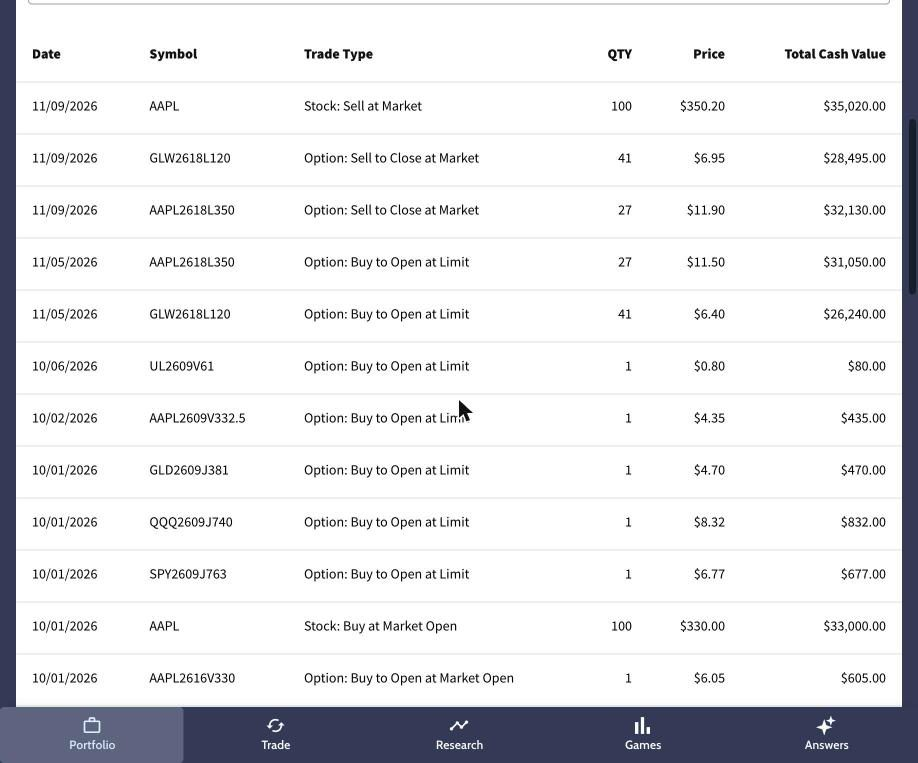

**Anexo B · Órdenes del 04-nov y limitación de Sell To Open** — en *Open Trades* solo se pudieron colocar las patas largas
(*Option: Buy to Open at Limit, GTC*).

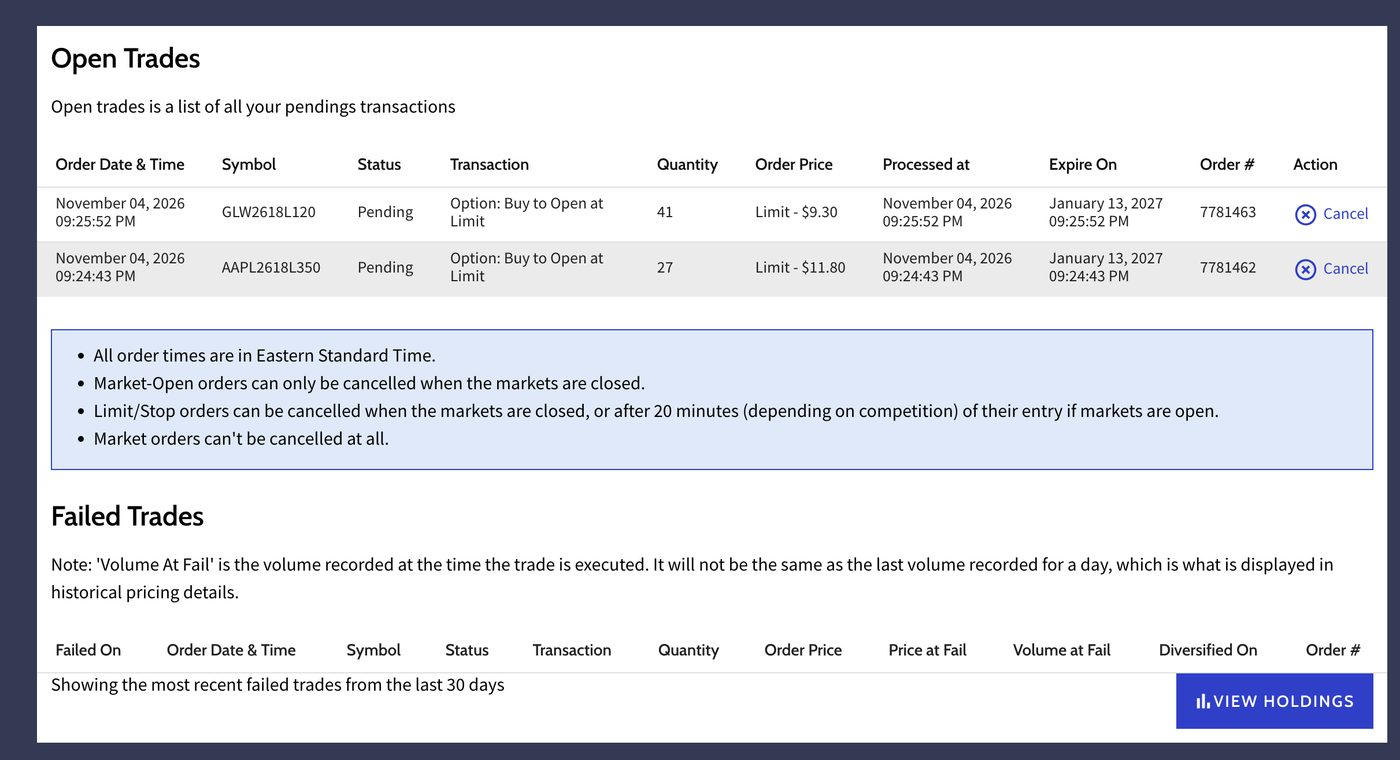

Formulario de opciones del simulador (AAPL call 360, 18-dic-2026, contrato fuera de cartera; no se envió ninguna orden): el menú *Action*
solo ofrece **Buy To Open** y **Sell To Close**. No existe *Sell To Open* para escribir opciones.

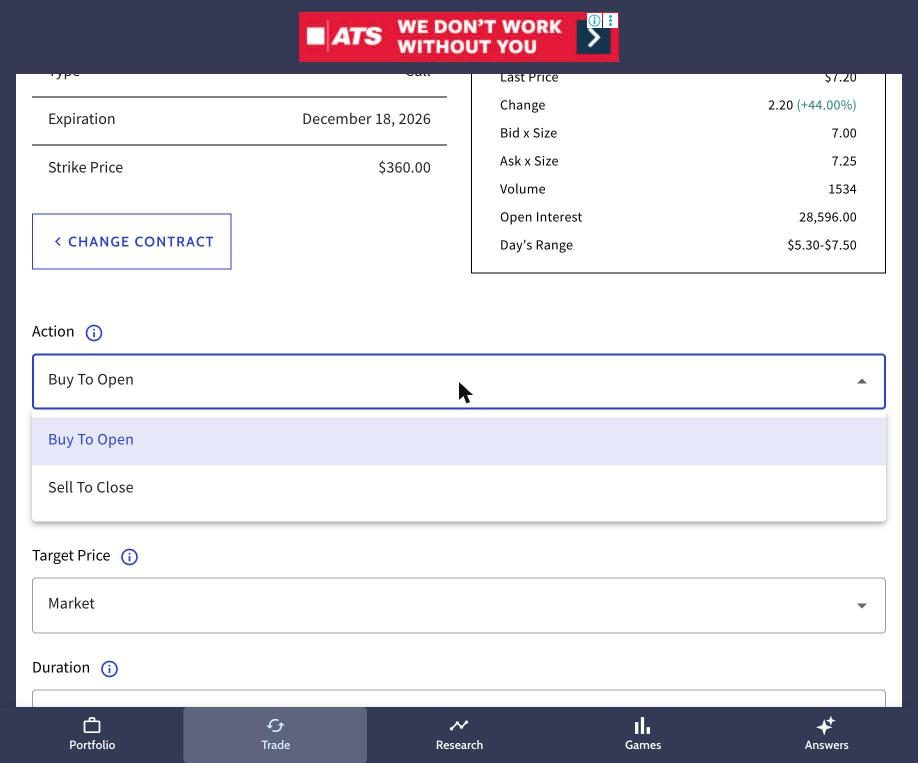

**Anexo C · Estado final del portafolio** — Account Value, Cash y Buying Power de $1,003,256.00; Annual Return de 2.35%.

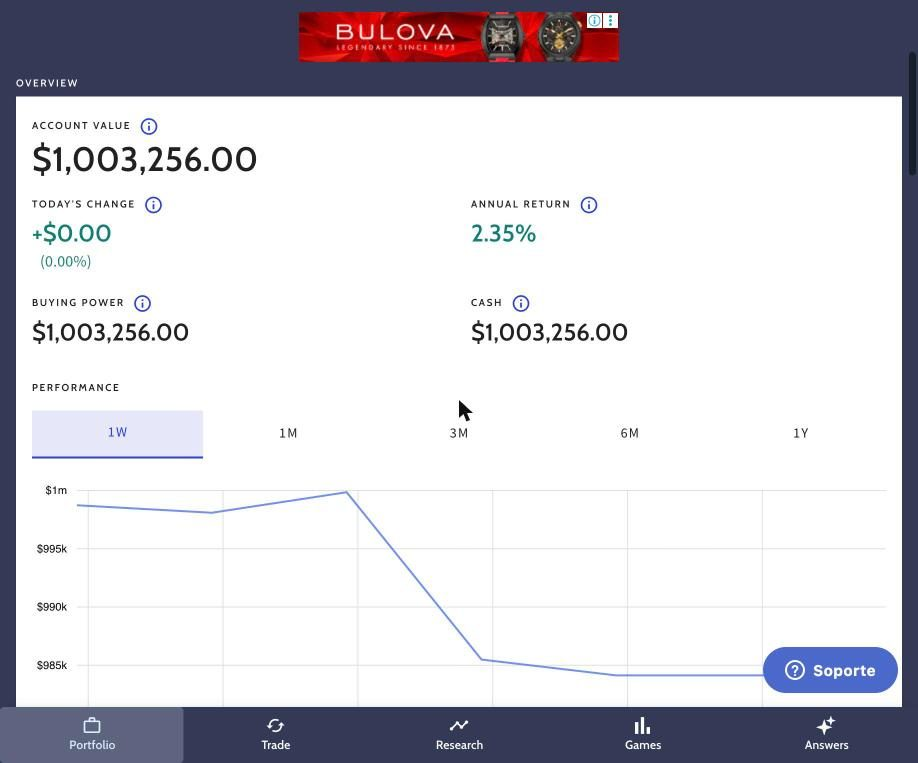

Performance en % a 1 semana con el S&P 500 activado (línea oscura = S&P 500; línea azul = cuenta). Fotos al cierre diario, sin las ventas del 09-nov.

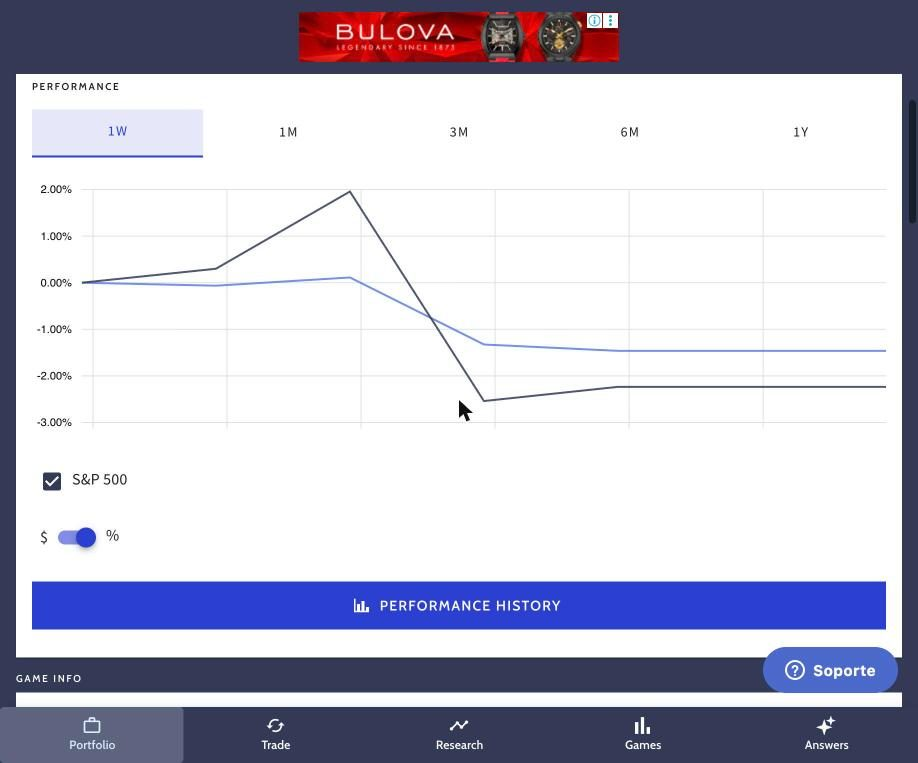

**Anexo D · Sin posiciones ni órdenes pendientes** — Holdings → Options: *"you have no option holdings yet"*; Stocks & ETFs tampoco muestra posiciones.

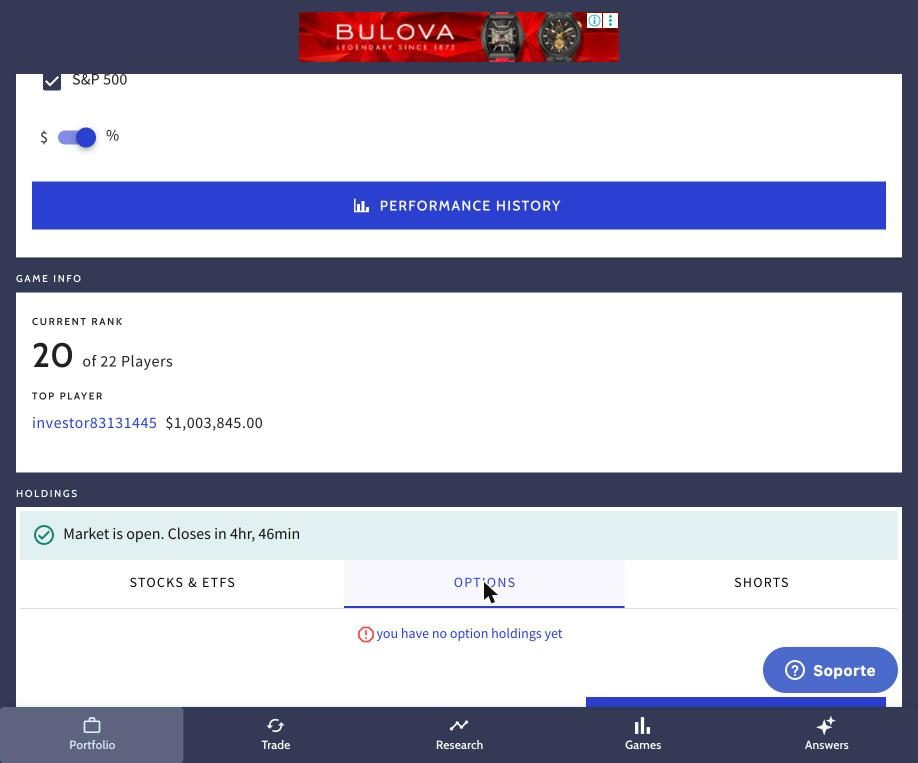

Order Status: *Open Trades* vacío y sin órdenes fallidas. El recuadro muestra las reglas de cancelación citadas en 19F.3.

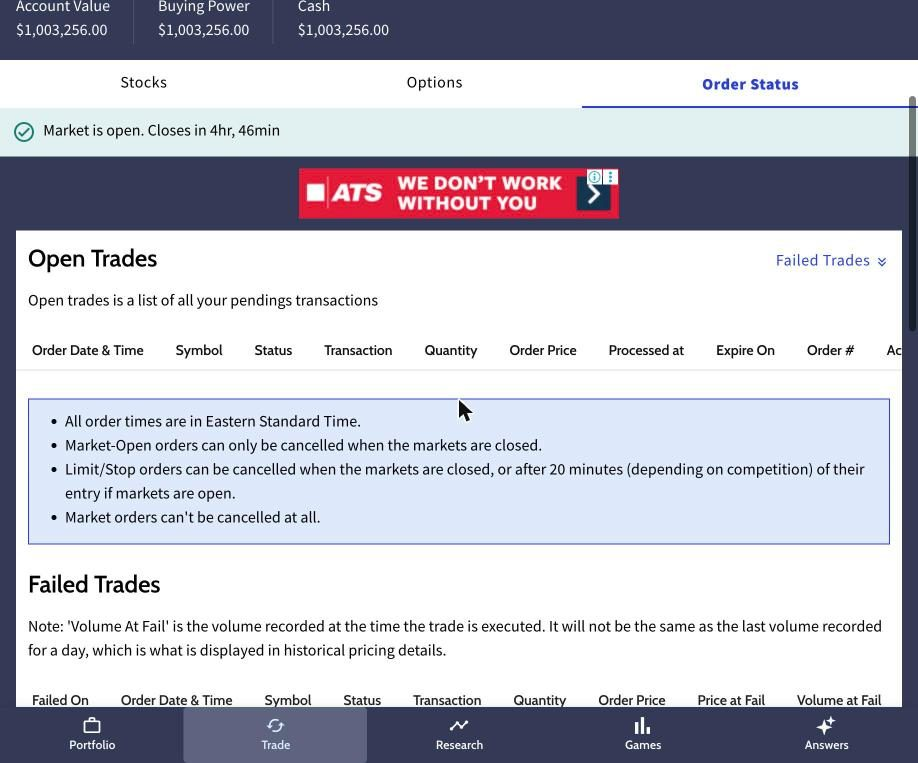

In [ ]:
# ===== 19F.6 · Pestaña "Cierre Investopedia" del dashboard (las capturas se leen de los adjuntos de este mismo notebook) =====
import glob
CAPTURAS_CIERRE = [
    ("cierre_A_trade_history.jpg", "Anexo A · Trade History (09-nov): compras del 05-nov y ventas del 09-nov"),
    ("cierre_B1_open_trades.jpg", "Anexo B · Open Trades del 04-nov: solo las patas largas (Buy to Open, Limit, GTC)"),
    ("cierre_B2_sin_sell_to_open.jpg", "Anexo B · Formulario de opciones: el menú Action solo tiene Buy To Open y Sell To Close"),
    ("cierre_C1_portfolio.jpg", "Anexo C · Portfolio Overview: Account Value $1,003,256 · Annual Return 2.35%"),
    ("cierre_C2_performance.jpg", "Anexo C · Performance 1 semana vs S&P 500 (fotos al cierre diario)"),
    ("cierre_D1_holdings.jpg", "Anexo D · Holdings → Options: sin posiciones"),
    ("cierre_D2_order_status.jpg", "Anexo D · Order Status: Open Trades vacío y reglas de cancelación"),
]

def _adjuntos_cierre():
    for p in sorted(set(glob.glob(os.path.join(CARPETA, "*.ipynb")) + glob.glob("*.ipynb")), key=os.path.getmtime, reverse=True):
        try:
            with open(p, encoding="utf-8") as fh: nb_ = json.load(fh)
        except Exception:
            continue
        out = {}
        for c in nb_.get("cells", []):
            for nombre, d in (c.get("attachments") or {}).items():
                if nombre.startswith("cierre_"):
                    mime, b64 = next(iter(d.items())); out[nombre] = (mime, b64 if isinstance(b64, str) else "".join(b64))
        if out:
            return out
    return {}

ADJ_CIERRE = _adjuntos_cierre()
caps_html = "".join(f'<figure class="fig" style="margin:0"><img src="data:{ADJ_CIERRE[n][0]};base64,{ADJ_CIERRE[n][1]}" '
                    f'style="width:100%;border-radius:8px;border:1px solid #e5e7eb" alt="{_esc(t)}"><figcaption class="nota">{_esc(t)}</figcaption></figure>'
                    for n, t in CAPTURAS_CIERRE if n in ADJ_CIERRE)
if not caps_html:
    caps_html = '<p class="nota">No se encontraron las capturas en el .ipynb de la carpeta; ver la sección 19F.5 del notebook.</p>'

kp_c = "".join([card2("P&L estrategia del proyecto", f"{_usd(PNL_EST)}", f"{PNL_EST/COSTO_EST:+.2%} en {SESIONES_MANT} sesiones · calls del 05-nov"),
                card2("P&L total realizado", f"{_usd(PNL_TOT)}", f"{PNL_TOT/COSTO_TOT:+.2%} sobre ${COSTO_TOT:,.0f} · 3 posiciones"),
                card2("Valor final de la cuenta", f"${VALOR_FINAL:,.0f}", "100% en efectivo · sin posiciones"),
                card2("Annual Return", f"{ANNUAL_RETURN:+.2%}", "Reportado por Investopedia"),
                card2("Ejecución vs plan", "Pata larga", "E1 bull call spread → solo calls largos"),
                card2("Causa", "Sin Sell To Open", "Restricción del simulador, no del modelo")])
_lims = """<ul>
<li><b>No existe "Sell To Open".</b> El menú <i>Action</i> solo ofrece Buy To Open y Sell To Close: no se pueden abrir posiciones cortas en
opciones. Por eso no se colocaron las patas cortas 385C (AAPL) y 145C (GLW), ni E2 ni E3.</li>
<li><b>No hay órdenes multi-pata.</b> Cada pata es una orden independiente: aun con permiso de venta habría <i>legging risk</i>.</li>
<li><b>Procesamiento diferido y reglas de cancelación.</b> Limit: no cancelables 20 min con mercado abierto; Market: nunca; Market-Open: solo con
mercado cerrado. Las órdenes del 04-nov se llenaron en la apertura del 05-nov.</li>
<li><b>Datos y ranking con retraso.</b> Performance y leaderboard se actualizan una vez al día (lugar 20 de 22 con un valor anterior).</li>
<li><b>Swaps fuera del alcance.</b> Los swaps de la sección 19E se valuaron con Refinitiv pero Investopedia no los ofrece: son coberturas propuestas.</li>
</ul>"""
_lect = """<ul>
<li><b>Se cumplió la tesis de volatilidad:</b> implícita AAPL 23.4% → 29.0% y GLW 58.7% → 70.1%, al nivel GARCH (29.7% y 68.1%). Los calls largos ganaron vega.</li>
<li><b>Dirección:</b> AAPL 349.51 → 342.37 y rebote a ≈348–350 el 09-nov; GLW 118.77 → 106.13 y rebote ≈ +6% intradía el día del cierre.</li>
<li><b>Sin ventaja para mantener:</b> con datos del 09-nov, E[P&L] al 13-nov de USD 508 (IV constante) y USD −606 (IV → GARCH), 53% de probabilidad de ganar.</li>
<li><b>Riesgo de modelo en GLW:</b> α+β = 0.999 (casi IGARCH); pronósticos con cautela.</li>
<li><b>Correlación AAPL–GLW:</b> EWMA −0.22 (promedio 0.31), 0.03 en residuos: diversificación alta.</li>
</ul>"""
CIERRE_HTML = (f'<div class="grid">{kp_c}</div>'
               f'<p class="nota">Juego "Derivados y Riesgos EGADE 26" · ejecución {FECHA_EJEC:%d-%b-%Y} · cierre {FECHA_CIERRE:%d-%b-%Y} · horas ET (Monterrey = ET − 1 h). '
               'Cierre con órdenes a mercado (Market · Day) para garantizar la ejecución el mismo día.</p>'
               f'<h3>1 · Precio de compra vs precio de venta</h3>{_t(RESUMEN_CIERRE.assign(**{"Rend. %": RESUMEN_CIERRE["Rend. %"].map("{:+.2%}".format), "Cantidad": RESUMEN_CIERRE["Cantidad"].map(lambda x: "" if pd.isna(x) else f"{x:,.0f}")}))}{_f("cierre_pnl")}'
               f'<h3>Detalle de órdenes</h3>{_t(TRADES_CIERRE.drop(columns=["Mult"]))}'
               f'<h3>2 · Cómo se comportó el mercado (04-nov vs 09-nov vs esta corrida)</h3>{_lect}{_t(MERCADO_CIERRE, True)}{_f("cierre_vol")}'
               f'<h3>3 · Por qué la estrategia no se ejecutó al 100%</h3>{_lims}{_t(LIMITES)}'
               f'<h3>Plan (bull call spread) vs ejecutado (call largo)</h3>{_t(PLAN_VS_EJEC)}{_f("cierre_payoff")}'
               f'<h3>Griegas de hoy por posición</h3>{_t(GRIEGAS_CIERRE)}'
               '<p class="nota">La pata corta del spread reduce delta, vega y theta. Con 4 sesiones y una implícita al alza, la mayor vega del call largo jugó a '
               'favor; el spread habría cedido parte de la ganancia a cambio de menos riesgo. Los resultados corresponden a la pata larga de E1.</p>'
               '<h3>4 · Conclusiones y lecciones</h3><ul><li>Portafolio cerrado por completo el 09-nov-2026, cuenta en $1,003,256 en efectivo.</li>'
               f'<li>La estrategia ganó {_usd(PNL_EST)} ({PNL_EST/COSTO_EST:+.2%}) en {SESIONES_MANT} sesiones, en línea con el E[P&L] de USD 3,585–3,934 estimado para los spreads completos.</li>'
               '<li>La ejecución fue parcial por una restricción del simulador, no por una decisión del modelo.</li>'
               '<li>Lecciones: validar antes lo que permite la plataforma; usar órdenes combinadas en spreads reales; cautela con GARCH casi integrados; '
               'en horizontes cortos manda el cambio de IV y la dirección.</li></ul>'
               f'<h3>5 · Evidencia (capturas de Investopedia)</h3><div class="two">{caps_html}</div>')
CIERRE_CONCL = (f"<p><b>Cierre en Investopedia (09-nov-2026).</b> Se ejecutó solo la pata larga del bull call spread recomendado (calls AAPL 350 y GLW 120) "
                f"porque el simulador no permite <i>Sell To Open</i>. Al cerrar, la estrategia ganó <b>{_usd(PNL_EST)} ({PNL_EST/COSTO_EST:+.2%})</b> en "
                f"{SESIONES_MANT} sesiones y el total realizado fue {_usd(PNL_TOT)}; la cuenta terminó en ${VALOR_FINAL:,.0f} en efectivo. La tesis de "
                "volatilidad se cumplió: la implícita convergió al nivel GARCH.</p>")
print(f"Pestaña de cierre lista · {len(ADJ_CIERRE)} capturas embebidas")

## 20 · Gráficas

In [ ]:
PAL = dict(azul="#1f4e79", azul2="#2e75b6", verde="#2e7d32", rojo="#c62828", gris="#6b7280", oro="#b7791f")
LAY = dict(template="plotly_white", font=dict(family="Inter, Segoe UI, Arial", size=12), margin=dict(l=50, r=20, t=50, b=40),
           height=380, legend=dict(orientation="h", y=-0.22))
FIGS = {}
pctax = dict(tickformat=".0%")

f = go.Figure(go.Scatter(x=HIST.index, y=HIST.values, name="AAPL", line=dict(color=PAL["azul"])))
for val, nom, col in [(S, "Spot", PAL["gris"]), (K1, f"Conversión {PRIMA_CONV:.0%}", PAL["verde"]), (K2, f"Warrant {PRIMA_WARRANT:.0%}", PAL["rojo"])]:
    f.add_hline(y=val, line_dash="dash", line_color=col, annotation_text=f"{nom} ${val:,.0f}")
f.update_layout(title="AAPL — precio vs precios de conversión", **LAY); FIGS["precio"] = f

f = go.Figure(go.Scatter(x=list(ust_x), y=np.array(ust_y)*100, name="UST", mode="lines+markers", line=dict(color=PAL["gris"])))
UU = U.dropna(subset=["ytm"])
f.add_trace(go.Scatter(x=UU["anios"], y=UU["ytm"]*100, mode="markers", name="Bonos AAPL", text=UU["nombre"], marker=dict(color=PAL["azul2"], size=9)))
f.add_trace(go.Scatter(x=[T_BONO], y=[YTM*100], mode="markers", name="Bono elegido", marker=dict(color=PAL["rojo"], size=15, symbol="star")))
f.update_layout(title="Curva USD de Apple vs Treasuries", xaxis_title="Años", yaxis_title="Rendimiento (%)", **LAY); FIGS["curva"] = f

idx = REND.index
f = go.Figure()
f.add_trace(go.Scatter(x=idx, y=VOL_30.values, name="Histórica 30 días", line=dict(color=PAL["gris"], width=1)))
f.add_trace(go.Scatter(x=idx, y=vol_anual(V_EW), name="EWMA λ=0.94", line=dict(color="black", width=1, dash="dash")))
f.add_trace(go.Scatter(x=idx, y=vol_anual(V_G), name="GARCH(1,1)", line=dict(color=PAL["azul2"], width=2)))
f.add_hline(y=float(vol_anual(VL)), line_dash="dot", line_color=PAL["rojo"], annotation_text=f"V_L {vol_anual(VL):.1%}")
f.update_layout(title="AAPL: volatilidad anualizada por modelo", yaxis=pctax, **LAY); FIGS["vol_modelos"] = f

dd = np.arange(1, int(PLAZO_CONV*252) + 1)
f = go.Figure(go.Scatter(x=dd, y=vol_anual(pron_var(len(dd))), name="σ diaria pronosticada", line=dict(color=PAL["azul2"], width=2)))
f.add_trace(go.Scatter(x=dd, y=[vol_promedio(d) for d in dd], name="σ promedio hasta el día", line=dict(color=PAL["oro"], width=2, dash="dash")))
f.add_hline(y=float(vol_anual(VL)), line_dash="dot", line_color=PAL["rojo"], annotation_text="Largo plazo")
f.add_vline(x=HORIZON_DAYS, line_color=PAL["gris"], annotation_text="6 meses"); f.add_vline(x=int(PLAZO_CONV*252), line_color=PAL["verde"], annotation_text="6 años")
f.update_layout(title="Reversión a la media: estructura temporal GARCH", xaxis_title="Días hábiles", yaxis=pctax, **LAY); FIGS["vol_term"] = f

f = go.Figure()
if not CORR_EWMA.empty:
    f.add_trace(go.Scatter(x=CORR_60.index, y=CORR_60.values, name="Móvil 60 días", line=dict(color=PAL["gris"])))
    f.add_trace(go.Scatter(x=CORR_EWMA.index, y=CORR_EWMA.values, name="EWMA λ=0.94", line=dict(color="black", width=2)))
f.update_layout(title="Correlación AAPL – S&P 500", **LAY); FIGS["corr"] = f

dias = np.arange(HORIZON_DAYS + 1); pc = np.percentile(SIM, [5, 25, 50, 75, 95], axis=1)
f = go.Figure()
f.add_trace(go.Scatter(x=dias, y=pc[4], line=dict(width=0), showlegend=False))
f.add_trace(go.Scatter(x=dias, y=pc[0], fill="tonexty", fillcolor="rgba(46,117,182,.15)", line=dict(width=0), name="P5–P95"))
f.add_trace(go.Scatter(x=dias, y=pc[3], line=dict(width=0), showlegend=False))
f.add_trace(go.Scatter(x=dias, y=pc[1], fill="tonexty", fillcolor="rgba(46,117,182,.35)", line=dict(width=0), name="P25–P75"))
f.add_trace(go.Scatter(x=dias, y=pc[2], name="Mediana", line=dict(color=PAL["azul"], width=2)))
f.add_hline(y=S, line_dash="dot", line_color=PAL["gris"]); f.add_hline(y=K1, line_dash="dash", line_color=PAL["verde"], annotation_text="Conversión")
f.update_layout(title=f"Abanico Monte Carlo GARCH a {HORIZON_DAYS} días", xaxis_title="Días hábiles", **LAY); FIGS["abanico"] = f

ib = REND.index[INICIO_BT:]; lim = -Z_BT*np.sqrt(VG_BT[INICIO_BT:]); exc = u[INICIO_BT:] < lim
f = go.Figure(go.Scatter(x=ib, y=u[INICIO_BT:], name="Rendimiento diario (%)", line=dict(color=PAL["gris"], width=1)))
f.add_trace(go.Scatter(x=ib, y=lim, name="−VaR 99% GARCH", line=dict(color=PAL["azul2"], width=1.6)))
f.add_trace(go.Scatter(x=ib[exc], y=u[INICIO_BT:][exc], mode="markers", name="Excepciones", marker=dict(color="black", size=7)))
f.update_layout(title="Back testing del VaR 99% a 1 día", **LAY); FIGS["backtest"] = f

f = go.Figure(go.Bar(x=VOL_COMP["Volatilidad"], y=VOL_COMP["opcion_bono"], marker_color=[PAL["rojo"] if e else PAL["azul2"] for e in VOL_COMP["En uso"]],
                     text=[f"σ {s_:.1%}<br>cupón {c_:.2%}" for s_, c_ in zip(VOL_COMP["σ"], VOL_COMP["cupon"])], textposition="outside"))
f.update_layout(title="Valor de la opción de conversión por bono según la volatilidad", yaxis_title="USD por bono", **LAY); FIGS["opc_vol"] = f

f = go.Figure(go.Bar(x=EXH3["Año"], y=EXH3["Flujo"], name="Flujo", marker_color=PAL["azul2"]))
f.add_trace(go.Bar(x=EXH3["Año"], y=EXH3["VP"], name="Valor presente", marker_color=PAL["oro"]))
f.update_layout(title=f"Bono puro: cupón {C['cupon']:.2%} descontado al {YTM:.2%} → ${C['piso']:.1f}", barmode="group", yaxis_type="log", xaxis_title="Año", **LAY); FIGS["flujos"] = f

Sx = np.linspace(0.3*S, 2.5*S, 200)
f = go.Figure(go.Scatter(x=Sx, y=np.full_like(Sx, C["piso"]), name="Piso (bono puro)", line=dict(color=PAL["gris"], dash="dash")))
f.add_trace(go.Scatter(x=Sx, y=C["n"]*Sx, name="Paridad de conversión", line=dict(color=PAL["verde"], dash="dot")))
f.add_trace(go.Scatter(x=Sx, y=C["piso"] + C["n"]*bsm(Sx, C["K"], RF, SIGMA, PLAZO_CONV, Q_USO)["call"], name="Convertible", line=dict(color=PAL["azul"], width=3)))
f.add_vline(x=S, line_color=PAL["rojo"], annotation_text="Spot")
f.update_layout(title="Convertible = bono puro + calls (σ GARCH)", xaxis_title="Precio AAPL", yaxis_title="USD por bono", **LAY); FIGS["convertible"] = f

f = make_subplots(specs=[[{"secondary_y": True}]])
f.add_trace(go.Bar(x=[f"{p:.0%}" for p in SENS["Prima"]], y=SENS["opcion_bono"], name="Opción por bono", marker_color=PAL["azul2"]), secondary_y=False)
f.add_trace(go.Scatter(x=[f"{p:.0%}" for p in SENS["Prima"]], y=SENS["cupon"]*100, name="Cupón a la par (%)", line=dict(color=PAL["rojo"], width=3)), secondary_y=True)
f.update_layout(title="Menor prima → opción más valiosa → cupón más bajo", **LAY); FIGS["prima"] = f

f = go.Figure(go.Heatmap(z=HEAT.values, x=HEAT.columns, y=HEAT.index, colorscale="RdYlGn_r", text=np.round(HEAT.values, 2), texttemplate="%{text}%", colorbar=dict(title="Cupón %")))
f.update_layout(title="Cupón a la par: prima × volatilidad", xaxis_title="Volatilidad", yaxis_title="Prima", **{**LAY, "height": 420}); FIGS["heat"] = f

STg = np.linspace(0.5*S, 2.5*S, 200); pay = np.maximum(STg-K1, 0) - np.maximum(STg-K2, 0)
f = go.Figure(go.Scatter(x=STg, y=pay, name="Payoff call spread", line=dict(color=PAL["verde"], width=3)))
f.add_trace(go.Scatter(x=STg, y=pay - NETO/N_ACC*np.exp(RF*PLAZO_CONV), name="Neto de costo (VF)", line=dict(color=PAL["azul"], dash="dash")))
f.add_trace(go.Scatter(x=STg, y=np.maximum(STg-K1, 0), name="Dilución sin overlay", line=dict(color=PAL["rojo"], dash="dot")))
f.update_layout(title="Overlay: compra call 25% + venta warrant 60%", xaxis_title="AAPL al vencimiento", yaxis_title="USD por acción", **LAY); FIGS["spread"] = f

gx = bsm(Sx, C["K"], RF, SIGMA, PLAZO_CONV, Q_USO)
f = make_subplots(specs=[[{"secondary_y": True}]])
f.add_trace(go.Scatter(x=Sx, y=gx["delta_c"], name="Delta", line=dict(color=PAL["azul"])), secondary_y=False)
f.add_trace(go.Scatter(x=Sx, y=gx["vega"]*C["n"], name="Vega por bono", line=dict(color=PAL["verde"], dash="dot")), secondary_y=True)
f.update_layout(title="Griegas de la opción de conversión", xaxis_title="Precio AAPL", **LAY); FIGS["griegas"] = f

gr = np.linspace(np.percentile(ST_s, 0.5), np.percentile(ST_s, 99.5), 200)
f = make_subplots(specs=[[{"secondary_y": True}]])
f.add_trace(go.Histogram(x=ST_s, nbinsx=60, name="Distribución GARCH", marker_color="rgba(107,114,128,.35)", histnorm="probability density"), secondary_y=True)
f.add_trace(go.Scatter(x=gr, y=np.abs(gr - K_ATM) - costo_str, name="P&L straddle", line=dict(color=PAL["azul"], width=3)), secondary_y=False)
f.add_hline(y=0, line_color=PAL["gris"])
f.update_layout(title=f"Straddle ATM K={K_ATM} y distribución GARCH a 6 meses", xaxis_title="Precio al vencimiento", **LAY); FIGS["straddle"] = f
FIGS["vol_modelos"].show()

## 21 · Dashboard HTML (FINA 405 + caso Molson + GARCH)

In [ ]:
def fm(v, tipo="num", d=2):
    if v is None or (isinstance(v, float) and np.isnan(v)): return "n/d"
    return {"pct": f"{v*100:,.{d}f}%", "usd": f"${v:,.{d}f}", "bn": f"${v/1e9:,.1f} B", "x": f"{v:,.{d}f}x"}.get(tipo, f"{v:,.{d}f}")
def card(t, v, sub="", alerta=False):
    return f'<div class="card{" warn" if alerta else ""}"><div class="lab">{t}</div><div class="val">{v}</div><div class="sub">{sub}</div></div>'
def fuente(k): return FUENTES.get(k, "")
def esresp(k): return "respaldo" in FUENTES.get(k, "") or "SIMULADOS" in FUENTES.get(k, "")
def tabla(df): return df.to_html(classes="tbl", float_format=lambda x: f"{x:,.4f}", border=0, na_rep="n/d")
def fig(k): return f'<div class="fig">{FIGS[k].to_html(full_html=False, include_plotlyjs=False, config={"displayModeBar": False})}</div>'

ahorro_pb = (YTM - C["cupon"])*1e4
bt99 = BT[(BT["Confianza"] == "99%") & (BT["Modelo"] == "GARCH(1,1)")].iloc[0]

kpi_resumen = "".join([
    card("Bono base", "4.500% 2032", BONO["isin"]),
    card("Precio limpio", fm(precio_bono, d=3), fuente("precio_bono"), esresp("precio_bono")),
    card("YTM (tasa descuento)", fm(YTM, "pct"), "Análogo al 5.75% del caso"),
    card("Spread vs UST", f"{SPREAD*1e4:,.0f} pb", f"Dur. mod. {MOD:.2f}"),
    card("AAPL spot", fm(S, "usd"), fuente("S"), esresp("S")),
    card("σ convertible", fm(SIGMA, "pct", 1), fuente("vol")),
    card("rf 6 años", fm(RF, "pct"), fuente("rf"), esresp("ust5")),
    card("Dividend yield", fm(Q, "pct"), fuente("q"), esresp("q")),
    card("Opción conversión/bono", fm(C["opcion_bono"], "usd", 1), f"{C['n']:.3f} acc. × ${C['call_acc']:.2f}"),
    card("Bono puro", fm(C["piso"], "usd", 1), "Piso del convertible"),
    card("Cupón a la par", fm(C["cupon"], "pct"), f"Ahorro {ahorro_pb:,.0f} pb vs straight"),
    card("Call spread neto", fm(NETO/MONTO, "pct", 1), f"USD {NETO/1e6:,.1f} M · caso 8.6%"),
])
kpi_vol = "".join([
    card("α (shock)", f"{ALPHA:.4f}", "GARCH(1,1) MLE"), card("β (memoria)", f"{BETA:.4f}", f"Persistencia {ALPHA+BETA:.3f}"),
    card("Vida media shock", f"{VIDA_MEDIA:.0f} días", "ln 0.5 / ln(α+β)"),
    card("σ largo plazo", fm(float(vol_anual(VL)), "pct", 1), "V_L anualizada"),
    card("σ GARCH hoy", fm(float(vol_anual(V_NEXT)), "pct", 1), "Día siguiente"),
    card("σ histórica 1 año", fm(VOL_HIST_1A, "pct", 1), fuente("historia"), esresp("historia")),
    card("σ GARCH promedio 6 años", fm(VOL_GARCH_6A, "pct", 1), "Entra al convertible" if VOL_FUENTE == "GARCH" else "Referencia"),
    card("σ implícita ATM", fm(IV, "pct", 1), fuente("iv"), esresp("iv")),
])
kpi_riesgo = "".join([
    card("Mediana 6 meses", fm(MC["Mediana"], "usd"), f"P5 {MC['P5']:,.0f} · P95 {MC['P95']:,.0f}"),
    card("Prob. de subir", fm(MC["Prob. sube"], "pct", 1), f"μ supuesto {MU_ANUAL:.0%}"),
    card("VaR 99% 10 días", fm(MC["VaR 99% 10 días (%)"], "pct", 1), "Monte Carlo GARCH"),
    card("Kupiec VaR 99% GARCH", f"p = {bt99['p Kupiec']:.3f}", f"{bt99['Excepciones']} excepciones · {bt99['Resultado']}", bt99["p Kupiec"] < 0.05),
    card("Corr. EWMA vs S&P", fm(CORR_EWMA.iloc[-1] if not CORR_EWMA.empty else np.nan), f"Beta 1 año {BETA_MKT:.2f}"),
    card("Mejor modelo (AIC)", MEJOR_MODELO, "Hull 23.4"),
])
kpi_emp = "".join([card(k + (" (estimada)" if k == "Interest Coverage" and COB_EST else ""), fm(EMP[k], t),
                        "EBIT / (deuda × YTM)" if k == "Interest Coverage" and COB_EST else "Refinitiv") for k, t in [
    ("Market Cap", "bn"), ("Revenue (LTM)", "bn"), ("EBITDA", "bn"), ("Net Income", "bn"), ("Total Debt", "bn"), ("Cash & ST Inv.", "bn"),
    ("D/E", "x"), ("Debt/Assets", "pct"), ("Interest Coverage", "x"), ("Net Debt/EBITDA", "x"), ("EBIT Margin", "pct"), ("Net Margin", "pct")]])
kpi_pais = "".join([card("USD/CNY", fm(PAIS["USD/CNY"], d=4), "Spot"), card("China 10Y", fm(PAIS["China 10Y"], "pct"), "Gov. yield"),
                    card("US 10Y", fm(PAIS["US 10Y"], "pct"), "Treasury"), card("Diferencial CN−US", fm(PAIS["China 10Y"] - PAIS["US 10Y"], "pct"), "Puntos de tasa")])

concl = f"""
<p><b>Bono base.</b> {BONO['nombre']} ({BONO['isin']}): precio {precio_bono:.3f}, YTM {YTM:.2%}, {SPREAD*1e4:.0f} pb sobre UST,
duración modificada {MOD:.2f}. Es el análogo del bono straight a 6 años de Molson (5.75% en el caso).</p>
<p><b>Volatilidad (clase GARCH).</b> GARCH(1,1) estimado por máxima verosimilitud sobre {len(u):,} rendimientos diarios: α = {ALPHA:.3f},
β = {BETA:.3f}, persistencia {ALPHA+BETA:.3f} (un shock se diluye a la mitad en ~{VIDA_MEDIA:.0f} días). Hoy la volatilidad es {vol_anual(V_NEXT):.1%} y revierte hacia
{vol_anual(VL):.1%}; por eso la σ promedio para la vida del convertible (6 años) es <b>{VOL_GARCH_6A:.1%}</b>, frente a {VOL_HIST_1A:.1%} histórica de 1 año
y {IV:.1%} implícita. El mejor modelo por AIC es <i>{MEJOR_MODELO}</i>. Usar la σ de hoy subestimaría la opción: GARCH justifica una σ de largo plazo.</p>
<p><b>Convertible sintético a {PLAZO_CONV:.0f} años, prima {PRIMA_CONV:.0%}.</b> Con σ = {SIGMA:.1%} la opción vale ${C['opcion_bono']:.1f} por bono
({C['n']:.3f} acciones a ${C['K']:.2f}); el bono puro debe valer ${C['piso']:.1f}, lo que exige un cupón de <b>{C['cupon']:.2%}</b> vs {YTM:.2%} straight:
ahorro de {ahorro_pb:.0f} pb (≈ USD {(YTM-C['cupon'])*MONTO/1e6:,.1f} M al año sobre USD {MONTO/1e9:.1f} B). El árbol CRR americano agrega solo
${(am_['precio']-eu_)*C['n']:.2f} por bono de prima de ejercicio anticipado (q = {Q:.2%} ≪ r = {RF:.2%}), y el Monte Carlo GARCH (Duan) da
${MC_CALL*C['n']:.1f}: Black-Scholes es una aproximación válida, igual que en el caso.</p>
<p><b>Riesgo.</b> Para el inversionista, el VaR 99% a 10 días de la acción es {MC['VaR 99% 10 días (%)']:.1%}; el back testing del VaR 99% GARCH
{'pasa' if bt99['p Kupiec'] > 0.05 else 'no pasa'} la prueba de Kupiec (p = {bt99['p Kupiec']:.3f}). La dilución potencial es de solo
{fm(EMP.get('Dilución conv. 25%'), 'pct')} de las acciones: para Apple el convertible es una herramienta de costo, no de capital.</p>
<p><b>Call spread.</b> Note hedge {COSTO_HEDGE/MONTO:.1%} − warrants {INGRESO_WARR/MONTO:.1%} = costo neto <b>{NETO/MONTO:.1%}</b> del principal (caso: 8.6%).
Emitir directo al 60% exigiría cupón {C60['cupon']:.2%}; el VP de ese cupón extra (USD {VP_EXTRA/1e6:,.1f} M) frente al costo del spread (USD {NETO/1e6:,.1f} M)
confirma el punto del caso: <i>no hay free lunch</i>.</p>
<p><b>Estrategia de volatilidad.</b> σ GARCH 6m {VOL_GARCH_6M:.1%} vs implícita {IV:.1%} (razón {RATIO_VOL:.2f}): {SENAL}.
Straddle ATM K={K_ATM}: costo {STRADDLE['costo']:.2f}, P&L esperado {STRADDLE['pnl_esp']:.2f}, probabilidad de ganar {STRADDLE['prob_gan']:.0%}.</p>
<p><b>Limitaciones.</b> GARCH(1,1) supone normalidad y no capta asimetría (GJR/EGARCH); μ es un supuesto; el bono real tiene make-whole call
(Molson era non-call life) y Apple no tiene convertibles: es una emisión hipotética.</p>"""

concl += CIERRE_CONCL   # 19F · cierre del portafolio
tabs = [
 ("Resumen", f'<div class="grid">{kpi_resumen}</div><div class="two">{fig("convertible")}{fig("precio")}</div>'),
 ("Bonos AAPL", f'<p class="nota">Fuente: {FUENTE_UNIV}. Puntaje = cercanía a 6 años y a la par.</p>{fig("curva")}'
     + tabla(U.sort_values("puntaje", ascending=False)[["nombre", "cusip", "isin", "cupon", "vencimiento", "anios", "precio", "ytm", "puntaje"]].reset_index(drop=True))),
 ("Empresa & País", f'<h3>Apple Inc. — perfil financiero</h3><div class="grid">{kpi_emp}</div><h3>Contexto China</h3><div class="grid">{kpi_pais}</div>'),
 ("Volatilidad GARCH", f'<div class="grid">{kpi_vol}</div><div class="two">{fig("vol_modelos")}{fig("vol_term")}</div>'
     f'<h3>Parámetros y validación</h3><p class="nota">{ARCH_CHECK}</p>{tabla(GARCH_TAB.to_frame("AAPL"))}'
     f'<h3>Elección de modelo (Hull 23.4)</h3>{tabla(COMPAR.set_index("Modelo"))}<h3>Estructura temporal</h3>{tabla(EST_TEMP)}'),
 ("Riesgo & VaR", f'<div class="grid">{kpi_riesgo}</div><div class="two">{fig("abanico")}{fig("backtest")}</div>{fig("corr")}'
     f'<h3>Back testing (Kupiec)</h3>{tabla(BT.set_index(["Confianza", "Modelo"]))}<h3>Monte Carlo GARCH</h3>{tabla(MC.to_frame("AAPL"))}'),
 ("Opción de conversión", f'{fig("opc_vol")}{tabla(VOL_COMP.set_index("Volatilidad"))}'
     f'<h3>Exhibit 2 — Black-Scholes-Merton (q = {Q_USO:.2%})</h3>{tabla(EXH2)}'
     f'<h3>Americana (árbol CRR, N={N_ARBOL}) y Monte Carlo GARCH</h3>{tabla(AMER)}{tabla(GRIEGAS_CRR.to_frame("Griegas CRR americana (por acción)"))}{fig("griegas")}'),
 ("Bono puro & cupón", f'<h3>Exhibit 3</h3>{fig("flujos")}{tabla(EXH3)}<p class="nota">Convertible = ${C["piso"]:.2f} + ${C["opcion_bono"]:.2f} = ${C["piso"]+C["opcion_bono"]:.2f}</p>'),
 ("Sensibilidades", f'<div class="two">{fig("prima")}{fig("heat")}</div>{tabla(SENS)}'),
 ("Call spread", f'<h3>Exhibits 1 y 4</h3>{tabla(EXH4)}{fig("spread")}<p class="nota">Cupón directo al {PRIMA_WARRANT:.0%}: {C60["cupon"]:.3%} · σ warrant {VOL_W:.1%}</p>'),
 ("Estrategia volatilidad", f'<p><b>Señal:</b> {SENAL} (σ GARCH 6m {VOL_GARCH_6M:.1%} / σ implícita {IV:.1%} = {RATIO_VOL:.2f})</p>'
     f'{fig("straddle")}{tabla(OPC_ATM.set_index("Volatilidad"))}<p class="nota">Puntos de equilibrio {STRADDLE["be_inf"]:.2f} y {STRADDLE["be_sup"]:.2f}</p>'),
 ("Validación Molson", f'<p class="nota">El modelo reproduce los exhibits del caso con sus mismos supuestos.</p>{tabla(VALID.set_index("Concepto"))}'),
 ("Conclusiones", concl),
]
tabs.insert(len(tabs) - 2, ("Portafolio AAPL+GLW", T6_HTML))
tabs.insert(len(tabs) - 2, ("Seguimiento", SEG_HTML))
tabs.insert(len(tabs) - 2, ("Swaps", SW_HTML))
tabs.insert(len(tabs) - 2, ("Cierre Investopedia", CIERRE_HTML))
nav = "".join(f'<button class="tab{" on" if i == 0 else ""}" onclick="ver({i})">{t}</button>' for i, (t, _) in enumerate(tabs))
body = "".join(f'<section id="s{i}" style="display:{"block" if i == 0 else "none"}">{c}</section>' for i, (_, c) in enumerate(tabs))
fuentes_txt = " · ".join(f"{k}: {v}" for k, v in FUENTES.items() if not k.startswith("emp_"))
aviso = '<div class="aviso">⚠ Vista generada con datos simulados/respaldo — no son datos de mercado. Corre el notebook con tu sesión de Refinitiv.</div>' if esresp("historia") else ""

HTML = f"""<!doctype html><html lang="es"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>AAPL Convertible GARCH</title><script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
:root{{--bg:#f5f7fa;--card:#fff;--ink:#1a202c;--mut:#6b7280;--acc:#1f4e79;--warn:#b45309}}
body{{margin:0;background:var(--bg);color:var(--ink);font-family:Inter,Segoe UI,Arial,sans-serif}}
header{{background:linear-gradient(135deg,#0f2742,#1f4e79);color:#fff;padding:22px 28px}}
header h1{{margin:0;font-size:22px}} header p{{margin:4px 0 0;opacity:.85;font-size:13px}}
.aviso{{background:#fef3c7;color:#92400e;padding:10px 28px;font-size:13px;font-weight:600}}
nav{{display:flex;flex-wrap:wrap;gap:6px;padding:12px 28px;background:#fff;border-bottom:1px solid #e5e7eb;position:sticky;top:0;z-index:5}}
.tab{{border:1px solid #d1d5db;background:#fff;border-radius:18px;padding:6px 14px;cursor:pointer;font-size:13px;color:var(--ink)}}
.tab.on{{background:var(--acc);color:#fff;border-color:var(--acc)}}
main{{padding:20px 28px;max-width:1400px;margin:auto}}
.grid{{display:grid;grid-template-columns:repeat(auto-fill,minmax(200px,1fr));gap:12px;margin-bottom:18px}}
.card{{background:var(--card);border-radius:10px;padding:14px 16px;box-shadow:0 1px 3px rgba(0,0,0,.08);border-left:4px solid var(--acc)}}
.card.warn{{border-left-color:var(--warn)}} .lab{{font-size:12px;color:var(--mut);text-transform:uppercase;letter-spacing:.04em}}
.val{{font-size:22px;font-weight:700;margin:4px 0}} .sub{{font-size:11px;color:var(--mut)}}
.two{{display:grid;grid-template-columns:repeat(auto-fit,minmax(min(480px,100%),1fr));gap:14px}}
.fig{{background:#fff;border-radius:10px;padding:6px;margin-bottom:14px}}
table{{border-collapse:collapse;background:#fff;font-size:12.5px;margin:10px 0 18px;width:100%;overflow-x:auto;display:block}}
th,td{{padding:6px 10px;border-bottom:1px solid #eef0f3;text-align:right;white-space:nowrap}} th{{background:#f0f4f8;color:#334155}}
h3{{margin:18px 0 6px;color:#0f2742}} .nota{{font-size:12.5px;color:var(--mut)}} section p{{line-height:1.55;max-width:1050px}}
footer{{font-size:11px;color:var(--mut);padding:16px 28px}}
@media(max-width:600px){{main,nav,header,.aviso{{padding-left:16px;padding-right:16px}}}}
</style></head><body>
<header><h1>Apple Inc. (AAPL) — Bono Convertible Sintético con volatilidad GARCH</h1>
<p>{CURSO} · {AUTORES} · Base: caso Molson Coors (NE90-06-107) + Hull caps. 13, 22 y 23 · Datos: Refinitiv/LSEG · {HOY:%d-%b-%Y}</p></header>
{aviso}<nav>{nav}</nav><main>{body}</main>
<footer>Fuentes: {fuentes_txt}. Las tarjetas con borde ámbar usan valores de respaldo. Material académico; no es recomendación de inversión.</footer>
<script>function ver(i){{document.querySelectorAll("section").forEach((s,j)=>s.style.display=j==i?"block":"none");
document.querySelectorAll(".tab").forEach((b,j)=>b.classList.toggle("on",j==i));window.dispatchEvent(new Event("resize"));}}</script>
</body></html>"""

RUTA = os.path.join(CARPETA, "AAPL_Convertible_GARCH_Dashboard.html")
with open(RUTA, "w", encoding="utf-8") as fh: fh.write(HTML)
print("Dashboard guardado en:", os.path.abspath(RUTA))
from IPython.display import IFrame, display
display(IFrame(src=RUTA, width="100%", height=900))

## 22 · Exportar tablas a Excel

In [ ]:
RUTA_XLSX = os.path.join(CARPETA, "AAPL_Convertible_GARCH_Tablas.xlsx")
with pd.ExcelWriter(RUTA_XLSX, engine="openpyxl") as xw:
    for nombre, df_, idx_ in [("Universo_bonos", U, False), ("GARCH_parametros", GARCH_TAB.to_frame("AAPL"), True),
                              ("Eleccion_modelo", COMPAR, False), ("Estructura_vol", EST_TEMP, True), ("MonteCarlo", MC.to_frame("AAPL"), True),
                              ("Backtest_VaR", BT, False), ("Vol_vs_opcion", VOL_COMP, False), ("Exhibit2_Opcion", EXH2, True),
                              ("Americana_CRR_MC", AMER, True), ("Exhibit3_Bono", EXH3, False), ("Sensibilidad_prima", SENS, False),
                              ("Heatmap_cupon", HEAT, True), ("Exhibit4_CallSpread", EXH4, True), ("Opcion_ATM_6m", OPC_ATM, False),
                              ("Validacion_Molson", VALID, False), ("Port_GARCH", TAB_GARCH_P, True), ("Port_MC", MC_P, True), ("Port_Kupiec", BT_P, False), ("Port_Ordenes", ORDENES, False),
                              ("Port_Resultados", RES_P, False), ("Port_Salida", SALIDA, False), ("Seguimiento", SEG, False),
                              ("Swap_IRS", SENS_IRS, False), ("Swap_Curva", CURVA, False), ("Swap_FX", FLUJOS_FX, False), ("Swap_Equity", EQ, True),
                              ("Cierre_Operaciones", TRADES_CIERRE, False), ("Cierre_Resumen", RESUMEN_CIERRE, False), ("Cierre_Mercado", MERCADO_CIERRE, True),
                              ("Cierre_Limitaciones", LIMITES, False), ("Cierre_Plan_vs_Ejec", PLAN_VS_EJEC, False), ("Cierre_Griegas", GRIEGAS_CIERRE, False),
                              *[(f"Arbol_{n.replace(' ', '_')}"[:31], a["df"], False) for n, a in ARBOLES.items()], ("Fuentes", pd.Series(FUENTES).to_frame("Fuente"), True)]:
        df_.to_excel(xw, sheet_name=nombre, index=idx_)
print("Excel exportado en:", os.path.abspath(RUTA_XLSX))

## 22B · PDF de órdenes y justificación para Investopedia (AAPL + GLW)

In [ ]:
import importlib
try:
    import reportlab
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--force-reinstall", "--no-deps", "reportlab==4.0.9"])
    importlib.invalidate_caches()
    for _m in [k for k in list(sys.modules) if k.startswith("reportlab")]:
        del sys.modules[_m]
    import reportlab
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from xml.sax.saxutils import escape as xesc
from reportlab.lib.pagesizes import letter, landscape
from reportlab.lib import colors
from reportlab.lib.units import inch
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak

os.makedirs(os.path.join(CARPETA, "pdf_tmp"), exist_ok=True)
def png_arbol(nom):
    a = ARBOLES[nom]; df_ = a["df"]; c = a["c"]; ruta = os.path.join(CARPETA, "pdf_tmp", nom.replace(" ", "_") + ".png")
    fig_, ax = plt.subplots(figsize=(6.2, 3.6))
    for _, r_ in df_[df_.Paso < df_.Paso.max()].iterrows():
        for dj in (0, 1):
            h = df_[(df_.Paso == r_.Paso + 1) & (df_.Nodo == r_.Nodo + dj)].iloc[0]
            ax.plot([r_.Día, h.Día], [r_.S, h.S], color="#cbd5e1", lw=1, zorder=1)
    ax.scatter(df_.Día, df_.S, c=["#c62828" if e else "#1f4e79" for e in df_.Ejercer], s=40, zorder=2)
    for _, r_ in df_.iterrows():
        ax.annotate(f"{r_.S:.1f}\n{r_.V:.2f}", (r_.Día, r_.S), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=6)
    ax.set_title(f"{nom}: {c['simbolo']} (S / V; rojo = ejercer)", fontsize=9); ax.set_xlabel("Días", fontsize=8)
    fig_.tight_layout(); fig_.savefig(ruta, dpi=150); plt.close(fig_); return ruta
def png_pnl():
    ruta = os.path.join(CARPETA, "pdf_tmp", "pnl.png"); fig_, ax = plt.subplots(figsize=(9, 3.4))
    ax.hist(sum(PNL[(tk, e, "IV constante")] for tk, e in EJEC) if EJEC else np.zeros(10), bins=70, color="#2e75b6", alpha=0.7)
    ax.axvline(0, color="gray"); ax.set_title("P&L del portafolio de opciones al 13-nov (Monte Carlo GARCH conjunto)", fontsize=10)
    ax.set_xlabel("USD"); fig_.tight_layout(); fig_.savefig(ruta, dpi=150); plt.close(fig_); return ruta

ss = getSampleStyleSheet()
H1 = ParagraphStyle("h1", parent=ss["Title"], fontSize=16, textColor=colors.HexColor("#0f2742"))
H2 = ParagraphStyle("h2", parent=ss["Heading2"], textColor=colors.HexColor("#1f4e79"))
H3 = ParagraphStyle("h3", parent=ss["Heading3"], textColor=colors.HexColor("#0f2742"))
TX = ParagraphStyle("tx", parent=ss["BodyText"], fontSize=9, leading=12)
CEL = ParagraphStyle("cel", parent=ss["BodyText"], fontSize=7, leading=8.5)
AV = ParagraphStyle("av", parent=TX, textColor=colors.HexColor("#92400e"), backColor=colors.HexColor("#fef3c7"))
import re as _re
def P(t, st=TX): return Paragraph(_re.sub(r"&(?![a-zA-Z#][a-zA-Z0-9]*;)", "&amp;", t), st)
def fmtv(v):
    if isinstance(v, (float, np.floating)):
        return "n/d" if np.isnan(v) else f"{v:,.2f}" if abs(v) >= 1 or v == 0 else f"{v:.4f}"
    return xesc(str(v))
def tabla_pdf(df, anchos=None):
    data = [[Paragraph(f"<b>{xesc(str(c))}</b>", CEL) for c in df.columns]] + [[Paragraph(fmtv(v), CEL) for v in r_.values] for _, r_ in df.iterrows()]
    t = Table(data, colWidths=anchos, repeatRows=1)
    t.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e8eef5")), ("GRID", (0, 0), (-1, -1), 0.3, colors.HexColor("#cbd5e1")),
                           ("VALIGN", (0, 0), (-1, -1), "TOP"), ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f8fafc")])]))
    return t

RUTA_PDF = os.path.join(CARPETA, f"Ordenes_Investopedia_AAPL_GLW_{FECHA_EJEC:%d%b%Y}.pdf")
doc = SimpleDocTemplate(RUTA_PDF, pagesize=landscape(letter), leftMargin=0.45*inch, rightMargin=0.45*inch, topMargin=0.45*inch, bottomMargin=0.45*inch)
el = [P(f"Órdenes para Investopedia · AAPL + GLW · ejecución {FECHA_EJEC:%d-%b-%Y} · evaluación {FECHA_EVAL:%d-%b-%Y}", H1),
      P(f"{CURSO} · {AUTORES} · Tareas Clase 6 y 7 (GARCH, Monte Carlo, árboles binomiales y swaps) · Generado {pd.Timestamp.now():%d-%b-%Y %H:%M}")]
if API is None or any("SIMULADOS" in MK[tk]["fh"] for tk in tks):
    el.append(P("⚠ GENERADO SIN CONEXIÓN COMPLETA A LSEG: hay datos de respaldo. NO usar para operar.", AV))
el.append(Spacer(1, 6))

el.append(P("0 · Primero: órdenes pendientes del 4-nov", H2))
if len(CANCELAR):
    el.append(P("Estas órdenes ya no corresponden al mercado actual. <b>Cancélalas en Open Trades → Cancel ANTES de colocar las nuevas</b>:"))
    el.append(tabla_pdf(CANCELAR[["orden", "simbolo", "accion", "cantidad", "limite", "bid", "ask", "Diagnóstico"]]))
else:
    el.append(P("No hay órdenes pendientes que requieran acción."))
if EVENTO:
    el.append(P(xesc(EVENTO)))
el.append(Spacer(1, 6))
el.append(P("Resumen del mercado y del modelo", H2))
res_m = pd.DataFrame([{"Acción": tk, "Precio": MK[tk]["S"], "σ GARCH hoy": f"{MK[tk]['G']['vol_hoy']:.1%}", "σ largo plazo": f"{MK[tk]['G']['vol_lp']:.1%}",
                       "σ GARCH 1–3m": f"{INFO[tk]['vg1']:.1%} / {INFO[tk]['vg2']:.1%}", "σ implícita": f"{MK[tk]['iv']:.1%}",
                       "Dividendo": f"{MK[tk]['q']:.2%}", "Mediana 13-nov": MC_P.loc["Mediana 13-nov", tk],
                       "P5–P95 13-nov": f"{MC_P.loc['P5', tk]:.2f} – {MC_P.loc['P95', tk]:.2f}", "Fuente precio": MK[tk]["fS"]} for tk in tks])
el.append(tabla_pdf(res_m))
el.append(P(f"Tasa corta {R_CORTO:.2%} ({fuente('r_3m')}) · correlación AAPL–GLW (residuos GARCH) {RHO_Z:.2f} · capital disponible USD {CAPITAL_DISPONIBLE:,.0f}. "
            f"<b>Horario:</b> 9:30 ET = 8:30 Monterrey. <b>Control:</b> si el mid de Investopedia difiere más de 5% del límite o la acción abre más de 2% lejos del precio de la tabla, "
            f"vuelve a correr el notebook."))
el.append(PageBreak())

el.append(P("1 · Órdenes nuevas (capturar en este orden)", H2))
O_ = ORDENES.drop(columns=["Decisión"]).copy(); O_["Monto USD"] = O_["Monto USD"].map(lambda x: f"{x:,.0f}")
el.append(tabla_pdf(O_, [0.25*inch, 0.45*inch, 1.15*inch, 1.05*inch, 1.1*inch, 1.3*inch, 0.65*inch, 0.4*inch, 0.5*inch, 1.0*inch, 0.7*inch, 1.4*inch]))
el.append(P(f"Flujo neto al abrir todo: <b>USD {ORDENES['Monto USD'].sum():,.0f}</b> (− sale efectivo). La columna Símbolo es el código que muestra Investopedia "
            f"(p. ej. AAPL2618L330 = AAPL 18-dic-2026 call 330; la letra A–L es call de ene–dic y M–X put de ene–dic)."))
for paso in ["Trade → Options → símbolo → Expiration, Call/Put y Strike (verifica que el Symbol coincida con la tabla).",
             "Action: Buy To Open / Sell To Open · Number of Contracts · Target Price: Limit · Price: el límite · Duration: Good Until Cancelled.",
             "Spreads: primero la pata larga; cuando se llene, la corta. Covered call: primero las acciones (Stock: Buy).",
             "Preview Order → Submit → screenshot de la confirmación y de Open Trades. Al llenarse, registra el precio en posiciones_investopedia.csv."]:
    el.append(P("• " + paso))
el.append(PageBreak())

el.append(P("2 · ¿Por qué estas órdenes?", H2))
for tk in tks:
    d = MK[tk]; g_ = d["G"]; i_ = INFO[tk]
    c1l, c1s = PATAS[(tk, "E1")][0][2], PATAS[(tk, "E1")][1][2]; p2l, p2s = PATAS[(tk, "E2")][0][2], PATAS[(tk, "E2")][1][2]
    u1, u2, u3 = UNID[(tk, "E1")], UNID[(tk, "E2")], UNID[(tk, "E3")]
    r_ = RES_P[RES_P["Acción"] == tk].set_index(RES_P[RES_P["Acción"] == tk].Estrategia.str[:2])
    regimen = "por debajo" if g_["vol_hoy"] < g_["vol_lp"] else "por encima"
    caro = d["iv"] > i_["vg1"]
    el.append(P(f"{tk} · precio {d['S']:.2f}", H3))
    el.append(P(f"<b>Volatilidad.</b> El GARCH(1,1) estimado con 5 años de Refinitiv (α={g_['al']:.3f}, β={g_['be']:.3f}, persistencia {g_['al']+g_['be']:.3f}, "
                f"vida media de un shock {g_['vida']:.0f} días) dice que la volatilidad de hoy, {g_['vol_hoy']:.1%}, está {regimen} de su nivel de largo plazo "
                f"({g_['vol_lp']:.1%}); por reversión a la media, la σ promedio esperada es {i_['vg1']:.1%} hasta {i_['e1']:%d-%b} y {i_['vg2']:.1%} hasta {i_['e2']:%d-%b}. "
                f"La implícita del mercado es {d['iv']:.1%}: las opciones están {'<b>caras</b> frente al modelo → conviene vender prima o usar spreads' if caro else '<b>baratas</b> frente al modelo → comprar opciones tiene ventaja de volatilidad'}."))
    el.append(P(f"<b>Dirección.</b> El Monte Carlo GARCH conjunto (μ={MU_ANUAL:.0%} supuesto, correlación {RHO_Z:.2f}) da al 13-nov una mediana de "
                f"{MC_P.loc['Mediana 13-nov', tk]:.2f} y un rango P5–P95 de {MC_P.loc['P5', tk]:.2f}–{MC_P.loc['P95', tk]:.2f}: sesgo levemente alcista con riesgo "
                f"a la baja → estrategias alcistas con pérdida acotada. Vencimientos de 1–3 meses ({i_['e1']:%d-%b} y {i_['e2']:%d-%b}), mensuales y líquidos."))
    el.append(P(f"<b>E1 · Bull call spread {c1l['K']:g}/{c1s['K']:g}.</b> Compra el call ATM y vende el de +1σ GARCH (≈ {d['S']:.2f} + {i_['m1']:.2f}). Débito {-u1['neto']/100:.2f}, "
                f"ganancia máx. {u1['ganancia']/100:.2f}, break-even {u1['be']:.2f}. Vender el call alto abarata la entrada y reduce vega. "
                f"{CANT[(tk,'E1')]} spreads = {PRESUPUESTO['E1']:.0%} del capital en riesgo. E[P&L] 13-nov: USD {r_.loc['E1','E[P&L] IV const.']:,.0f} (IV const.) / "
                f"USD {r_.loc['E1','E[P&L] IV→GARCH']:,.0f} (IV→GARCH) · {r_.loc['E1','Decisión']}."))
    el.append(P(f"<b>E2 · Bull put spread {p2s['K']:g}/{p2l['K']:g}.</b> Vende la put a −0.75σ GARCH y compra la de {p2l['K']:g} como seguro (ancho {i_['ancho']:g}). "
                f"Crédito {u2['neto']/100:.2f}, pérdida máx. {u2['perdida']/100:.2f}, break-even {u2['be']:.2f}; gana con el tiempo (theta) y si la implícita baja. "
                f"{CANT[(tk,'E2')]} spreads. E[P&L]: USD {r_.loc['E2','E[P&L] IV const.']:,.0f} / USD {r_.loc['E2','E[P&L] IV→GARCH']:,.0f} · "
                f"prob. de ganar {r_.loc['E2','Prob. ganancia']:.0%} · {r_.loc['E2','Decisión']}."))
    el.append(P(f"<b>E3 · Covered call.</b> {100*CANT[(tk,'E3')]} acciones + venta de {CANT[(tk,'E3')]} calls {c1s['K']:g}: cobra {c1s['limite']:.2f} por acción "
                f"({c1s['limite']/d['S']:.1%} en {(i_['e1']-FECHA_EJEC).days} días), deja subir hasta {c1s['K']:g} ({c1s['K']/d['S']-1:+.1%}) y baja el break-even a {u3['be']:.2f}. "
                f"E[P&L]: USD {r_.loc['E3','E[P&L] IV const.']:,.0f} · {r_.loc['E3','Decisión']}."))
el.append(P(f"<b>Portafolio.</b> E[P&L] al 13-nov USD {PORT_P['e_pnl']:,.0f} ({PORT_P['rend']:.2%} del capital) con IV constante y USD {PORT_P['e_pnl_g']:,.0f} si la IV converge a GARCH; "
            f"probabilidad de ganancia {PORT_P['prob']:.0%}; VaR 99% USD {PORT_P['var99']:,.0f}; pérdida máxima teórica USD {PORT_P['riesgo']:,.0f}. "
            f"Lectura honesta: con un horizonte de {H_P} sesiones la ventaja esperada es pequeña; el resultado depende sobre todo de la dirección (μ) y del theta, "
            f"y las estrategias marcadas 'sensible a IV' pierden si la implícita cae hacia GARCH."))
el.append(Image(png_pnl(), width=8.8*inch, height=3.3*inch))
el.append(PageBreak())

el.append(P("3 · Detalle por estrategia y plan de salida", H2))
el.append(tabla_pdf(RES_P[["Acción", "Estrategia", "Unidades", "Flujo inicial USD", "Pérdida máx. USD", "Ganancia máx. USD", "Break-even",
                           "E[P&L] IV const.", "E[P&L] IV→GARCH", "Prob. ganancia", "Delta", "Theta", "Vega", "Decisión"]]))
el.append(Spacer(1, 6)); el.append(tabla_pdf(SALIDA))
el.append(PageBreak())
el.append(P("4 · Árboles binomiales CRR (niveles de nodos)", H2))
imgs = [Image(png_arbol(n), width=4.9*inch, height=2.85*inch) for n in ARBOLES]
el.append(Table([imgs[i:i + 2] for i in range(0, len(imgs), 2)]))
for n, a in ARBOLES.items():
    el.append(P(f"<b>{n}</b> ({a['c']['simbolo']}): u={a['par']['u']:.4f}, d={a['par']['d']:.4f}, p={a['par']['p']:.4f}, Δt={a['par']['dt_dias']:.1f} días · "
                f"500 pasos {a['precio500']:.2f} · europea {a['europea']:.2f} · prima de ejercicio anticipado {a['precio500'] - a['europea']:.3f}"))
el.append(PageBreak())
el.append(P("5 · Swaps (Hull, Cap. 7): coberturas propuestas (no se operan en Investopedia)", H2))
TXT_VENT = (f"la ganancia total es {g_tot:.2%} ({G_VENT:.2%} c/u). " if g_tot > 0 else
            f"NO hay ventaja comparativa ({g_tot:.2%}): el diferencial en fija ({dif_f:.2%}) es menor que en flotante ({dif_v:.2%}). ")
el.append(P(f"<b>Tasas:</b> Apple recibiría {TASA_PAR:.2%} fijo (tasa par) y pagaría SOFR sobre su bono 4.500% 2032: costo final SOFR {COSTO_POST:+.2%}. "
            f"Un swap que recibe 4.5% vale USD {V_REC_FIJO:,.0f} (bonos = FRAs); DV01 USD {DV01:,.0f} por pb. "
            f"<b>Ventaja comparativa:</b> fijas reales Apple {FIJA_A:.2%} vs Corning {FIJA_B:.2%}; con spreads flotantes supuestos (SOFR+{SPR_A:.2%} y SOFR+{SPR_B:.2%}) "
            + TXT_VENT +
            f"<b>USD/MXN:</b> pagar USD y recibir MXN sobre USD {N_USD_FX:,.0f} (spot {FX:.4f}, tasas {R_USD3:.2%} vs {R_MXN:.2%}) protege al equipo en pesos; "
            f"si el peso se aprecia 10% el swap vale USD {valor_fx(FX*0.9):,.0f}. <b>Equity swap</b> recibe AAPL / paga GLW: exposición relativa sin desembolsar efectivo."))
el.append(P("6 · Evidencias (screenshots)", H2))
for s_ in ["Investopedia: cancelación de las órdenes del 4-nov, Preview/Confirm de cada orden nueva, Open Trades, Holdings y Portfolio Overview (hoy y el 13-nov).",
           "CME Group: QuikStrike/CVOL del Nasdaq-100 (contexto de volatilidad) y curva SOFR (para el swap de tasas).",
           "TradingView: AAPL y GLW diario con strikes y break-even marcados.",
           "Notebook: celda CONECTADO, tabla de órdenes, árboles y pestaña de Seguimiento del dashboard."]:
    el.append(P("• " + s_))
el.append(P("Material académico con dinero simulado. Los pronósticos usan supuestos (GARCH normal, μ supuesto, IV constante o convergente) y no garantizan ganancias."))
doc.build(el)

import shutil
from pathlib import Path
DESC = Path.home()/"Downloads"; DESC.mkdir(exist_ok=True)
try:
    shutil.copy(RUTA_PDF, DESC/Path(RUTA_PDF).name); print("PDF generado:", os.path.abspath(RUTA_PDF), "| copia en Descargas")
except Exception as e:
    print("PDF generado:", os.path.abspath(RUTA_PDF), "| no se copió a Descargas:", e)

## 23 · Descargar el dashboard y el notebook completo en HTML
Guarda el notebook (**Cmd+S**) antes de correr esta celda para que el HTML del código incluya las últimas salidas.

In [ ]:
import glob, base64, shutil
from pathlib import Path
from IPython.display import HTML as _HTML

DESCARGAS = Path.home()/"Downloads"; DESCARGAS.mkdir(exist_ok=True)
dash = Path(RUTA).resolve(); dash_dest = DESCARGAS/dash.name; shutil.copy(dash, dash_dest)

nb = next((Path(p).resolve() for p in sorted(glob.glob("*.ipynb"), key=os.path.getmtime, reverse=True)
           if "VOL_GARCH_6A" in open(p, encoding="utf-8").read()), None)
nb_html = None
if nb is None:
    print("⚠ No encontré el .ipynb en esta carpeta; solo se descarga el dashboard.")
else:
    res = subprocess.run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "html", "--output", f"{nb.stem}_codigo",
                          "--output-dir", str(DESCARGAS), str(nb)], capture_output=True, text=True)
    nb_html = DESCARGAS/f"{nb.stem}_codigo.html"
    if res.returncode != 0: print(res.stderr[-800:]); nb_html = None

def boton(ruta, texto):
    b64 = base64.b64encode(Path(ruta).read_bytes()).decode()
    return (f'<a download="{Path(ruta).name}" href="data:text/html;base64,{b64}" style="display:inline-block;margin:6px 10px 6px 0;'
            f'padding:10px 18px;background:#1f4e79;color:#fff;border-radius:8px;text-decoration:none;font-weight:600">⬇ {texto}</a>')
nb_dest = None
if nb is not None:
    nb_dest = DESCARGAS/nb.name
    if nb_dest.resolve() != nb.resolve(): shutil.copy(nb, nb_dest)
display(_HTML(boton(dash_dest, "Descargar dashboard HTML") + (boton(nb_html, "Descargar notebook completo HTML") if nb_html else "")
             + (boton(nb_dest, "Descargar notebook .ipynb") if nb_dest else "")))
print("Copiados en Descargas:", dash_dest, nb_html or "", nb_dest or "")

In [ ]:
!jupyter nbconvert --to html AAPL_Convertible_GARCH_Proyecto.ipynb

In [ ]:
!open AAPL_Convertible_GARCH_Proyecto.html